# Notebook 1 — Preparación de datos, red experimental y tiempos de recorrido

**Proyecto Integrador — Equipo 42 · Route Intelligence**

> **Alcance de esta notebook.** Esta notebook construye y valida la representación
> de red utilizada en el proyecto a partir de PEMS-BAY, incorpora las longitudes
> de las aristas y transforma las observaciones de velocidad en series temporales
> de tiempos de recorrido.
>
> Como resultado, se obtiene un núcleo dirigido fuertemente conexo y un conjunto
> de datos temporal que permite generar matrices de tiempos de viaje $T(t)$ para
> los instantes requeridos en los experimentos posteriores. La construcción y
> evaluación del baseline histórico $K=0$ se desarrollan en una notebook
> independiente.

## 1. Configuración y fuentes de datos

Se emplean tres fuentes de información complementarias:

1. **PEMS-BAY.** Se utiliza el archivo `pems-bay.h5`, correspondiente a la versión preprocesada del benchmark empleada en trabajos como DCRNN. Contiene series temporales de velocidad para **325 sensores viales del área de la Bahía de San Francisco**, con observaciones nominalmente cada **5 minutos entre enero y junio de 2017**. Este archivo constituye la fuente de información dinámica de tráfico utilizada en el proyecto.

2. **Augmented PEMS-BAY.** Como complemento espacial y descriptivo se utilizan dos archivos:
   - `sensor_metadata.csv`, que incorpora para cada sensor la autopista, sentido de circulación, *postmile*, coordenadas geográficas, longitud asociada al segmento representado y número de carriles;
   - `freeway_sensor_sequence.csv`, que proporciona el orden de los sensores dentro de cada corredor dirigido.

3. **OpenStreetMap (OSM).** Se utiliza como fuente auxiliar para inspeccionar la
infraestructura vial alrededor de los corredores PEMS-BAY, validar la plausibilidad
de conexiones candidatas entre ellos y, cuando resulte útil, apoyar la estimación
de su ubicación o longitud. OSM no determina por sí mismo la topología de la red
experimental.

Debe considerarse que PEMS-BAY representa condiciones y localizaciones observadas
en 2017, mientras que OSM refleja la red disponible al momento de la consulta.
Por ello, las decisiones de conectividad se documentan explícitamente y OSM se
utiliza como evidencia auxiliar, no como sustituto de la estructura observada en
PEMS-BAY.

In [ ]:
# Dependencias necesarias en Google Colab.
!pip -q install gdown osmnx scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 2.2 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
from math import radians, sin, cos, sqrt, atan2
import json
import re
import requests

import gdown
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd

from IPython.display import display
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

DATA_DIR = Path('/content/data')
AUG_DIR = DATA_DIR / 'augmented_pems_bay'
DERIVED_DIR = Path('/content/derived')

DATA_DIR.mkdir(parents=True, exist_ok=True)
AUG_DIR.mkdir(parents=True, exist_ok=True)
DERIVED_DIR.mkdir(parents=True, exist_ok=True)

# Evita repetir consultas OSM cuando OSMnx dispone de resultados en caché.
ox.settings.use_cache = True
ox.settings.log_console = False

In [ ]:
# ------------------------------------------------------------
# Descarga de PEMS-BAY
# ------------------------------------------------------------
# Archivo enlazado por el repositorio de DCRNN.
PEMS_PATH = DATA_DIR / 'pems-bay.h5'
PEMS_GDRIVE_ID = '1wD-mHlqAb2mtHOe_68fZvDh1LpDegMMq'

if not PEMS_PATH.exists():
    gdown.download(
        id=PEMS_GDRIVE_ID,
        output=str(PEMS_PATH),
        quiet=False
    )

# ------------------------------------------------------------
# Descarga de metadatos aumentados
# ------------------------------------------------------------
augmented_files = {
    'sensor_metadata.csv':
        'https://raw.githubusercontent.com/george-j-ste/'
        'Augmented-PEMS-BAY/main/data/sensor_graph/sensor_metadata.csv',

    'freeway_sensor_sequence.csv':
        'https://raw.githubusercontent.com/george-j-ste/'
        'Augmented-PEMS-BAY/main/data/sensor_graph/freeway_sensor_sequence.csv',
}

for filename, url in augmented_files.items():
    path = AUG_DIR / filename

    if not path.exists():
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        path.write_bytes(response.content)

print('Archivos preparados:')
print(' -', PEMS_PATH)
for filename in augmented_files:
    print(' -', AUG_DIR / filename)

Downloading...
From (original): https://drive.google.com/uc?id=1wD-mHlqAb2mtHOe_68fZvDh1LpDegMMq
From (redirected): https://drive.google.com/uc?id=1wD-mHlqAb2mtHOe_68fZvDh1LpDegMMq&confirm=t&uuid=c851781f-318f-4a0d-a7c2-f1769bd3fdb3
To: /content/data/pems-bay.h5
100%|██████████| 136M/136M [00:01<00:00, 75.5MB/s]


Archivos preparados:
 - /content/data/pems-bay.h5
 - /content/data/augmented_pems_bay/sensor_metadata.csv
 - /content/data/augmented_pems_bay/freeway_sensor_sequence.csv


## 2. Carga y validación de los datos

Antes de construir la red se verifica que los tres insumos describan el mismo conjunto de sensores y que el orden `Freeway-Direction` sea consistente con los metadatos.

Esta validación evita introducir conexiones espaciales sobre identificadores incompletos, duplicados o asignados a un corredor distinto.

In [ ]:
# Series temporales PEMS-BAY.
# `pems_raw` conserva exactamente los datos cargados desde la fuente.
pems_raw = pd.read_hdf(PEMS_PATH)

# Metadatos espaciales y secuencia dirigida de sensores.
metadata = pd.read_csv(AUG_DIR / 'sensor_metadata.csv')
sequence = pd.read_csv(AUG_DIR / 'freeway_sensor_sequence.csv')

print('PEMS-BAY')
print('-' * 70)
print('Dimensiones:', pems_raw.shape)
print('Inicio:', pems_raw.index.min())
print('Fin:', pems_raw.index.max())

print('\nSENSOR METADATA')
print('-' * 70)
print('Dimensiones:', metadata.shape)
print('Columnas:', metadata.columns.tolist())

print('\nFREEWAY SENSOR SEQUENCE')
print('-' * 70)
print('Dimensiones:', sequence.shape)
print('Columnas:', sequence.columns.tolist())


PEMS-BAY
----------------------------------------------------------------------
Dimensiones: (52116, 325)
Inicio: 2017-01-01 00:00:00
Fin: 2017-06-30 23:55:00

SENSOR METADATA
----------------------------------------------------------------------
Dimensiones: (325, 8)
Columnas: ['Sensor ID', 'Freeway', 'Direction', 'Postmile', 'Latitude', 'Longitude', 'Length (km)', 'Lanes']

FREEWAY SENSOR SEQUENCE
----------------------------------------------------------------------
Dimensiones: (325, 3)
Columnas: ['Freeway-Direction', 'Sensor Order', 'Sensor']


In [ ]:
# Normalizar identificadores para comparar fuentes sin depender del tipo
# numérico/string con el que cada archivo fue almacenado.
pems_ids = set(map(str, pems_raw.columns))
metadata_ids = set(metadata['Sensor ID'].astype(str))
sequence_ids = set(sequence['Sensor'].astype(str))

print('COBERTURA DE SENSORES')
print('-' * 70)
print('PEMS-BAY:', len(pems_ids))
print('Metadata:', len(metadata_ids))
print('Sequence:', len(sequence_ids))

print('\nPEMS = metadata:', pems_ids == metadata_ids)
print('PEMS = sequence:', pems_ids == sequence_ids)

print('\nDuplicados en metadata:',
      int(metadata['Sensor ID'].duplicated().sum()))
print('Duplicados en sequence:',
      int(sequence['Sensor'].duplicated().sum()))

# Coherencia entre la asignación de corredor del metadata y la secuencia.
metadata_check = metadata.copy()
metadata_check['Sensor ID'] = metadata_check['Sensor ID'].astype(str)
metadata_check['Freeway-Direction'] = (
    metadata_check['Freeway'].astype(str)
    + '-'
    + metadata_check['Direction'].astype(str)
)

sequence_check = sequence.copy()
sequence_check['Sensor'] = sequence_check['Sensor'].astype(str)

consistency = sequence_check.merge(
    metadata_check[['Sensor ID', 'Freeway-Direction']],
    left_on='Sensor',
    right_on='Sensor ID',
    suffixes=('_sequence', '_metadata'),
    how='left'
)

mismatches = consistency[
    consistency['Freeway-Direction_sequence']
    != consistency['Freeway-Direction_metadata']
]

print('\nInconsistencias Freeway-Direction:', len(mismatches))


COBERTURA DE SENSORES
----------------------------------------------------------------------
PEMS-BAY: 325
Metadata: 325
Sequence: 325

PEMS = metadata: True
PEMS = sequence: True

Duplicados en metadata: 0
Duplicados en sequence: 0

Inconsistencias Freeway-Direction: 0


## 3. Exploración inicial de PEMS-BAY

El EDA de esta sección caracteriza los insumos antes de utilizarlos en la construcción de la red y en las etapas posteriores de modelado:

- cobertura temporal y continuidad del índice;
- valores faltantes y registros iguales a cero;
- distribución de las observaciones anómalas;
- comportamiento agregado de la velocidad reportada;
- distribución espacial de los sensores;
- número de sensores por corredor.

La matriz original se conserva sin modificaciones como `pems_raw`. Después de analizar la distribución de los valores iguales a cero, se genera una copia de trabajo denominada `pems_analysis`, que incorpora únicamente el tratamiento documentado en esta sección. A partir de ese punto, los análisis que dependen de las velocidades utilizan `pems_analysis`; la construcción topológica de la red se apoya en los metadatos espaciales y en la secuencia de sensores.


In [ ]:
# ------------------------------------------------------------
# Calidad y continuidad temporal del conjunto original
# ------------------------------------------------------------
expected_index = pd.date_range(
    pems_raw.index.min(),
    pems_raw.index.max(),
    freq='5min'
)

missing_timestamps = expected_index.difference(pems_raw.index)

n_values = pems_raw.shape[0] * pems_raw.shape[1]
n_nan = int(pems_raw.isna().sum().sum())
n_zero = int((pems_raw == 0).sum().sum())

print('CALIDAD TEMPORAL')
print('-' * 70)
print('Registros temporales observados:', len(pems_raw))
print('Registros en rejilla naïve de 5 min:', len(expected_index))
print(
    'Intervalos ausentes respecto a rejilla naïve de 5 min:',
    len(missing_timestamps)
)
print('NaN:', n_nan)
print('Valores iguales a cero:', n_zero)
print('Proporción de ceros:', f'{n_zero / n_values:.5%}')

if len(missing_timestamps) > 0:
    display(
        pd.DataFrame(
            {'intervalo_ausente': missing_timestamps}
        )
    )


CALIDAD TEMPORAL
----------------------------------------------------------------------
Registros temporales observados: 52116
Registros en rejilla naïve de 5 min: 52128
Intervalos ausentes respecto a rejilla naïve de 5 min: 12
NaN: 0
Valores iguales a cero: 521
Proporción de ceros: 0.00308%


,intervalo_ausente
0,2017-03-12 02:00:00
1,2017-03-12 02:05:00
2,2017-03-12 02:10:00
3,2017-03-12 02:15:00
4,2017-03-12 02:20:00
5,2017-03-12 02:25:00
6,2017-03-12 02:30:00
7,2017-03-12 02:35:00
8,2017-03-12 02:40:00
9,2017-03-12 02:45:00


### Calidad y continuidad temporal

El conjunto PEMS-BAY contiene **52,116 registros temporales** para 325 sensores. No se identificaron valores `NaN` en la matriz de velocidades original.

Al comparar las marcas temporales con una secuencia regular de cinco minutos se identifican 12 intervalos aparentemente ausentes, todos ellos entre las 02:00 y las 02:55 del **12 de marzo de 2017**. Esta discontinuidad coincide con el inicio del horario de verano en California, cuando el reloj local avanza directamente de las 02:00 a las 03:00. Por tanto, estos intervalos no se interpretan como pérdida de observaciones, sino como una consecuencia de la representación temporal en hora local.

También se identificaron **521 valores de velocidad iguales a cero**, equivalentes a aproximadamente **0.0031 %** de las observaciones sensor-tiempo. Dado que un valor cero podría representar tanto una condición extrema como un registro anómalo, su distribución temporal y espacial se examina antes de decidir su tratamiento.

En conjunto, estos resultados muestran que PEMS-BAY presenta una **alta integridad temporal**, adecuada para el análisis experimental posterior.


In [ ]:
# ------------------------------------------------------------
# Distribución de valores de velocidad iguales a cero
# ------------------------------------------------------------
# El diagnóstico se realiza sobre el conjunto original.
zero_mask = pems_raw.eq(0)

zeros_by_sensor = zero_mask.sum(axis=0)
zeros_by_time = zero_mask.sum(axis=1)

sensors_with_zeros = zeros_by_sensor[zeros_by_sensor > 0]
times_with_zeros = zeros_by_time[zeros_by_time > 0]

print('DISTRIBUCIÓN DE VALORES IGUALES A CERO')
print('-' * 70)
print('Total de ceros:', int(zero_mask.sum().sum()))
print('Sensores con al menos un cero:', len(sensors_with_zeros))
print('Timestamps con al menos un cero:', len(times_with_zeros))
print('Máximo de ceros en un mismo sensor:', int(zeros_by_sensor.max()))
print(
    'Máximo de sensores en cero simultáneamente:',
    int(zeros_by_time.max())
)

print('\nSensores con mayor número de valores cero:')
display(
    sensors_with_zeros
    .sort_values(ascending=False)
    .head(10)
    .rename('n_ceros')
    .to_frame()
)


DISTRIBUCIÓN DE VALORES IGUALES A CERO
----------------------------------------------------------------------
Total de ceros: 521
Sensores con al menos un cero: 270
Timestamps con al menos un cero: 4
Máximo de ceros en un mismo sensor: 4
Máximo de sensores en cero simultáneamente: 217

Sensores con mayor número de valores cero:


,n_ceros
sensor_id,
407364,4
404461,4
407373,4
404370,4
409526,4
408907,4
405613,4
404444,4
413877,3


In [ ]:
# ------------------------------------------------------------
# Timestamps en los que aparecen velocidades iguales a cero
# ------------------------------------------------------------
zero_events = (
    zeros_by_time[zeros_by_time > 0]
    .sort_values(ascending=False)
    .rename('n_sensores_en_cero')
    .to_frame()
)

zero_events['proporcion_sensores'] = (
    zero_events['n_sensores_en_cero'] / pems_raw.shape[1]
)

display(zero_events)


,n_sensores_en_cero,proporcion_sensores
2017-06-15 01:00:00,217,0.667692
2017-05-09 20:35:00,132,0.406154
2017-04-20 01:40:00,91,0.280000
2017-05-05 19:55:00,81,0.249231


### Tratamiento de valores iguales a cero

Los 521 valores de velocidad iguales a cero no se distribuyen de manera uniforme en el conjunto de datos. Se concentran exclusivamente en **cuatro marcas temporales**, en las que aparecen simultáneamente valores cero para 81, 91, 132 y 217 sensores, respectivamente. El caso de mayor alcance afecta aproximadamente al **66.8 % de los 325 sensores**.

La elevada concentración espacial de estos valores en instantes aislados hace poco plausible interpretarlos como situaciones reales de tráfico completamente detenido. Para efectos del análisis se consideran, por tanto, **observaciones anómalas asociadas al proceso de adquisición o preprocesamiento de los datos**.

Se conserva sin modificaciones el conjunto original y se genera una copia de trabajo. En esta última, únicamente los valores iguales a cero se tratan como observaciones ausentes y se estiman mediante interpolación temporal entre las observaciones válidas inmediatamente adyacentes. Esta decisión permite conservar la rejilla temporal regular de cinco minutos y evita eliminar las mediciones válidas de otros sensores correspondientes a los mismos instantes.

In [ ]:
# ------------------------------------------------------------
# Copia de trabajo con tratamiento de valores anómalos
# ------------------------------------------------------------

# La fuente original permanece intacta en `pems_raw`.
# La matriz de trabajo se utilizará a partir de este punto en los análisis
# y modelos que dependan de las velocidades.
pems_analysis = pems_raw.copy()

# Los ceros identificados se consideran observaciones ausentes.
pems_analysis = pems_analysis.mask(pems_analysis.eq(0))

# Al tratarse de anomalías aisladas, se interpolan temporalmente
# entre las observaciones válidas adyacentes de cada sensor.
pems_analysis = pems_analysis.interpolate(
    method='time',
    limit=1,
    limit_area='inside'
)

# Comprobaciones de integridad después del tratamiento.
n_changed = int((pems_analysis != pems_raw).sum().sum())

print('DATOS DESPUÉS DEL TRATAMIENTO')
print('-' * 70)
print('NaN restantes:', int(pems_analysis.isna().sum().sum()))
print('Valores iguales a cero:', int(pems_analysis.eq(0).sum().sum()))
print('Valores modificados:', n_changed)
print('Forma del conjunto:', pems_analysis.shape)

assert pems_analysis.shape == pems_raw.shape
assert int(pems_analysis.isna().sum().sum()) == 0
assert int(pems_analysis.eq(0).sum().sum()) == 0
assert n_changed == n_zero


DATOS DESPUÉS DEL TRATAMIENTO
----------------------------------------------------------------------
NaN restantes: 0
Valores iguales a cero: 0
Valores modificados: 521
Forma del conjunto: (52116, 325)


In [ ]:
# ------------------------------------------------------------
# Resumen por sensor
# ------------------------------------------------------------
# Las estadísticas descriptivas de velocidad utilizan la copia tratada.
# Se conserva, como referencia de calidad, el número de ceros observado
# originalmente en cada sensor.

sensor_stats = pd.DataFrame({
    'mean_speed': pems_analysis.mean(axis=0),
    'median_speed': pems_analysis.median(axis=0),
    'std_speed': pems_analysis.std(axis=0),
    'n_zeros_original': (pems_raw == 0).sum(axis=0)
})

print('RESUMEN DE ESTADÍSTICAS POR SENSOR')
display(sensor_stats.describe().T)

RESUMEN DE ESTADÍSTICAS POR SENSOR


,count,mean,std,min,25%,50%,75%,max
mean_speed,325.0,62.621609,2.581931,53.945039,60.888589,62.711465,64.539919,68.028865
median_speed,325.0,65.373846,2.098315,56.600000,63.900000,65.500000,66.800000,70.600000
std_speed,325.0,8.547669,3.501836,1.012289,5.950515,8.313407,11.156174,18.113331
n_zeros_original,325.0,1.603077,1.015006,0.000000,1.000000,2.000000,2.000000,4.000000


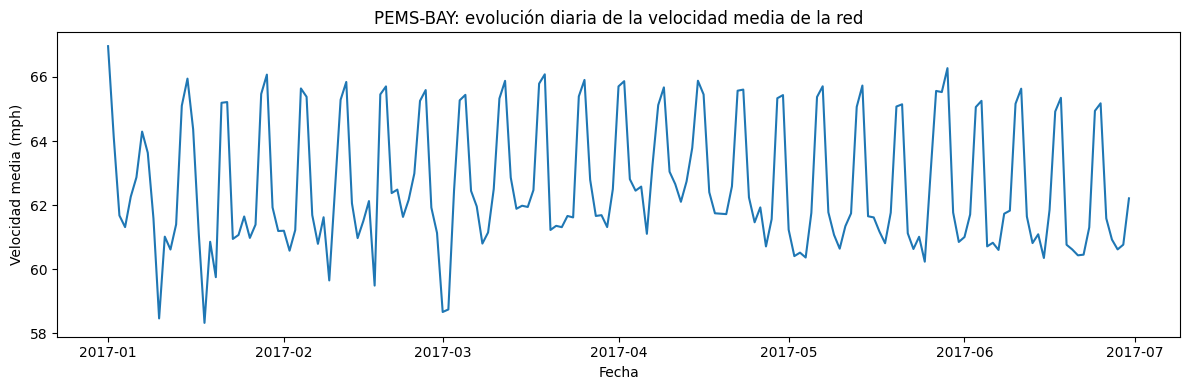

In [ ]:
# ------------------------------------------------------------
# Evolución diaria de la velocidad media de la red
# ------------------------------------------------------------
# Para cada instante se calcula primero la velocidad media entre
# los 325 sensores. Posteriormente se promedian esas observaciones
# dentro de cada día.

network_speed_5min = pems_analysis.mean(axis=1)

network_speed_daily = (
    network_speed_5min
    .groupby(network_speed_5min.index.normalize())
    .mean()
)

plt.figure(figsize=(12, 4))
plt.plot(
    network_speed_daily.index,
    network_speed_daily.values
)

plt.xlabel('Fecha')
plt.ylabel('Velocidad media (mph)')
plt.title('PEMS-BAY: evolución diaria de la velocidad media de la red')
plt.tight_layout()
plt.show()


### Evolución temporal agregada de la red

La velocidad media diaria de los 325 sensores presenta un patrón periódico claramente visible a lo largo del periodo analizado. Las oscilaciones se repiten aproximadamente con frecuencia semanal, mientras que no se observa una tendencia sostenida de aumento o disminución entre enero y junio de 2017.

Este comportamiento indica que las condiciones de tráfico presentan una estructura temporal recurrente. En consecuencia, variables asociadas al calendario —como la hora del día y el día de la semana— pueden contener información relevante para la posterior estimación de tiempos de viaje.

La gráfica representa un promedio agregado de toda la red y, por tanto, no pretende describir el comportamiento de corredores o sensores individuales, sino proporcionar una primera caracterización temporal del conjunto de datos.

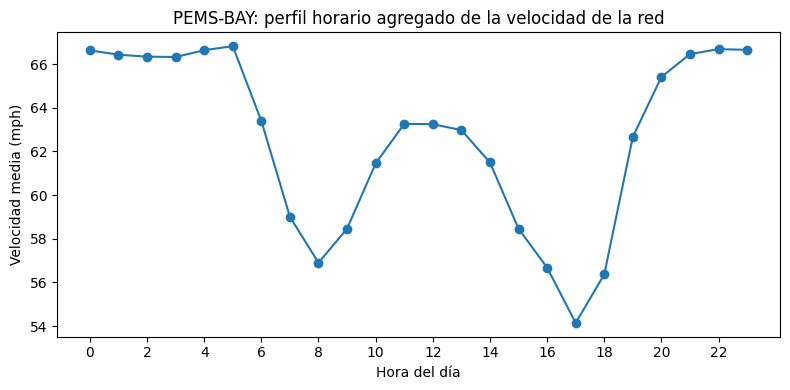

In [ ]:
# Perfil horario agregado. Ayuda a visualizar la variación sistemática
# de la movilidad a lo largo del día sin seleccionar sensores individuales.
network_speed_5min = pems_analysis.mean(axis=1)

hourly_profile = (
    network_speed_5min
    .groupby(network_speed_5min.index.hour)
    .mean()
)

plt.figure(figsize=(8, 4))
plt.plot(hourly_profile.index, hourly_profile.values, marker='o')
plt.xticks(range(0, 24, 2))
plt.xlabel('Hora del día')
plt.ylabel('Velocidad media (mph)')
plt.title('PEMS-BAY: perfil horario agregado de la velocidad de la red')
plt.tight_layout()
plt.show()


### Perfil horario agregado

El perfil horario agregado muestra una estructura diaria claramente diferenciada. La velocidad media de la red disminuye durante dos periodos principales: uno en la mañana, aproximadamente entre las 7:00 y las 9:00 horas, y otro durante la tarde, aproximadamente entre las 16:00 y las 18:00 horas. La reducción vespertina es más pronunciada en el promedio de la red.

Fuera de estos periodos se observa una recuperación de la velocidad, particularmente durante la noche y la madrugada, cuando los valores medios permanecen relativamente elevados y estables.

Este patrón confirma que la **hora del día constituye una fuente relevante de información temporal** para la estimación posterior del estado de la red y de los tiempos de viaje.

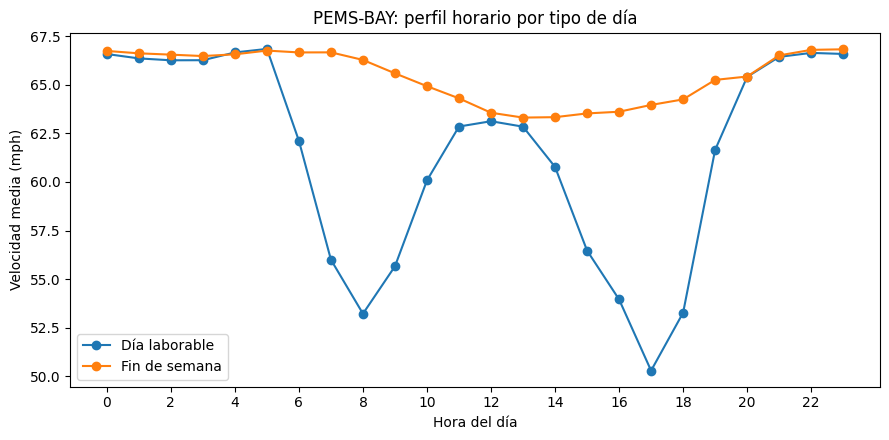

In [ ]:
# ------------------------------------------------------------
# Perfil horario: días laborables vs. fines de semana
# ------------------------------------------------------------

network_speed_5min = pems_analysis.mean(axis=1)

hourly_comparison = pd.DataFrame({
    'speed': network_speed_5min,
    'hour': network_speed_5min.index.hour,
    'day_type': np.where(
        network_speed_5min.index.dayofweek < 5,
        'Día laborable',
        'Fin de semana'
    )
})

hourly_comparison = (
    hourly_comparison
    .groupby(['day_type', 'hour'])['speed']
    .mean()
    .unstack(0)
)

plt.figure(figsize=(9, 4.5))

for day_type in hourly_comparison.columns:
    plt.plot(
        hourly_comparison.index,
        hourly_comparison[day_type],
        marker='o',
        label=day_type
    )

plt.xticks(range(0, 24, 2))
plt.xlabel('Hora del día')
plt.ylabel('Velocidad media (mph)')
plt.title('PEMS-BAY: perfil horario por tipo de día')
plt.legend()
plt.tight_layout()
plt.show()

### Diferencias entre días laborables y fines de semana

La separación del perfil horario entre días laborables y fines de semana revela diferencias sustanciales en la dinámica de la red.

Durante los **días laborables** se identifican dos periodos de reducción pronunciada de la velocidad media. El primero ocurre durante la mañana, con un mínimo alrededor de las 8:00 horas, y el segundo durante la tarde, con una caída todavía mayor alrededor de las 17:00 horas. Entre ambos periodos se observa una recuperación parcial de la velocidad.

En contraste, durante los **fines de semana** el perfil es considerablemente más estable. Aunque existe una reducción moderada durante las horas diurnas, no aparecen los descensos pronunciados característicos de los días laborables. Durante la madrugada y las últimas horas del día, ambos perfiles convergen en velocidades medias cercanas a sus valores máximos.

Estos resultados muestran que la dinámica temporal de PEMS-BAY depende conjuntamente de la **hora del día** y del **tipo de día**, lo que respalda la incorporación posterior de información temporal —como hora y día de la semana— en los modelos de estimación.

## 4. Corredores dirigidos y estructura espacial de sensores

`freeway_sensor_sequence.csv` proporciona una secuencia dirigida para cada
combinación autopista–sentido. Esta información se utiliza como la **estructura
primaria observada** de la red.

No se interpreta la matriz de similitud de DCRNN como si fuera un mapa físico.
Las conexiones dentro de cada corredor se definen directamente a partir del orden
de los sensores. Las posibles conexiones entre corredores se estudiarán
posteriormente a partir de su disposición espacial, utilizando OSM únicamente
como fuente auxiliar de validación.

In [ ]:
# Resumen de los corredores dirigidos
corridor_summary = (
    sequence
    .groupby('Freeway-Direction')
    .agg(
        n_sensors=('Sensor', 'size'),
        min_order=('Sensor Order', 'min'),
        max_order=('Sensor Order', 'max'),
        unique_orders=('Sensor Order', 'nunique')
    )
    .sort_values('n_sensors', ascending=False)
)

corridor_summary['orden_consistente'] = (
    (corridor_summary['min_order'] == 1)
    & (corridor_summary['max_order'] == corridor_summary['n_sensors'])
    & (corridor_summary['unique_orders'] == corridor_summary['n_sensors'])
)

# Verificaciones de integridad de la secuencia de corredores
assert corridor_summary['n_sensors'].sum() == 325, \
    "El número total de sensores en los corredores no coincide con PEMS-BAY."

assert corridor_summary['orden_consistente'].all(), \
    "Se detectó al menos un corredor con una secuencia de sensores inconsistente."

print('Número de corredores dirigidos:', len(corridor_summary))
display(corridor_summary)

Número de corredores dirigidos: 16


,n_sensors,min_order,max_order,unique_orders,orden_consistente
Freeway-Direction,,,,,
101-N,35,1,35,35,True
85-S,35,1,35,35,True
85-N,35,1,35,35,True
101-S,33,1,33,33,True
87-N,23,1,23,23,True
880-S,22,1,22,22,True
280-N,22,1,22,22,True
280-S,22,1,22,22,True
87-S,21,1,21,21,True


### Organización espacial por corredores dirigidos

Los 325 sensores de PEMS-BAY se distribuyen en **16 corredores dirigidos**, correspondientes a los distintos sentidos de circulación de las ocho autopistas representadas en los metadatos.

Para cada corredor se verificó la variable `Sensor Order`, que establece la secuencia de los sensores a lo largo del sentido de circulación. En los 16 casos, la numeración comienza en 1, termina en el número total de sensores del corredor y no presenta valores duplicados ni discontinuidades.

Esta consistencia permite utilizar el orden proporcionado por *Augmented PEMS-BAY* para construir las conexiones entre sensores consecutivos dentro de cada corredor, sin inferir su secuencia únicamente a partir de las coordenadas geográficas.

In [ ]:
# Integrar secuencia y metadatos en una sola tabla operativa.
seq_meta = sequence.copy()
seq_meta['Sensor'] = seq_meta['Sensor'].astype(str)

meta_net = metadata.copy()
meta_net['Sensor ID'] = meta_net['Sensor ID'].astype(str)
meta_net['Freeway'] = meta_net['Freeway'].astype(str)

seq_meta = seq_meta.merge(
    meta_net[
        [
            'Sensor ID',
            'Freeway',
            'Direction',
            'Postmile',
            'Latitude',
            'Longitude',
            'Length (km)',
            'Lanes'
        ]
    ],
    left_on='Sensor',
    right_on='Sensor ID',
    how='left',
    validate='one_to_one'
)

assert len(seq_meta) == 325
assert seq_meta['Sensor'].nunique() == 325

# Verificar que todos los sensores encontraron sus metadatos
required_metadata = [
    'Freeway', 'Direction', 'Postmile',
    'Latitude', 'Longitude', 'Length (km)', 'Lanes'
]

assert seq_meta[required_metadata].notna().all().all(), \
    "Al menos un sensor de la secuencia no encontró metadatos completos."

# Verificar consistencia entre el corredor de la secuencia
# y la autopista/sentido reportados en los metadatos
corridor_from_metadata = (
    seq_meta['Freeway'].astype(str)
    + '-'
    + seq_meta['Direction'].astype(str)
)

assert (seq_meta['Freeway-Direction'] == corridor_from_metadata).all(), \
    "Existe al menos un sensor cuya autopista o sentido no coincide con la secuencia."

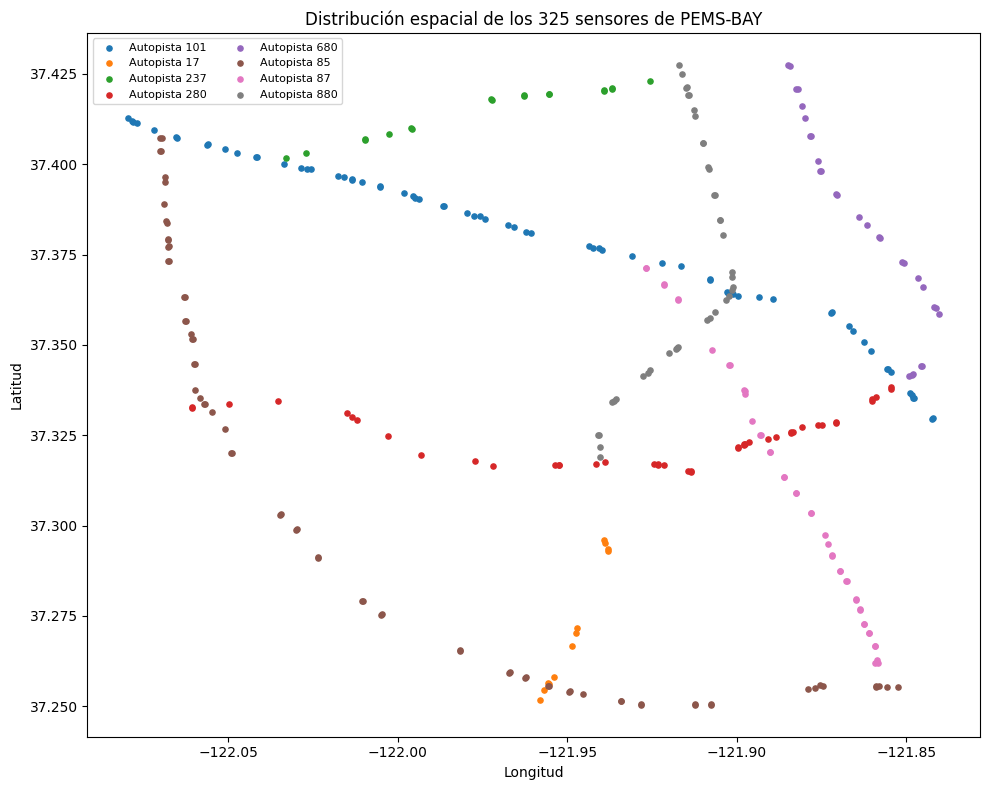

In [ ]:
# Visualización espacial de sensores por autopista.
plt.figure(figsize=(10, 8))

for freeway, group in metadata.groupby(metadata['Freeway'].astype(str)):
    plt.scatter(
        group['Longitude'],
        group['Latitude'],
        s=14,
        label=f'Autopista {freeway}'
    )

plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('Distribución espacial de los 325 sensores de PEMS-BAY')
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

### Distribución espacial de los sensores

Los 325 sensores de PEMS-BAY se distribuyen sobre **ocho autopistas**, cada una representada mediante sus dos sentidos de circulación, lo que da lugar a **16 corredores dirigidos**. En la figura los sensores se colorean por autopista, por lo que ambos sentidos de una misma vía comparten color.

Las coordenadas disponibles en *Augmented PEMS-BAY* permiten representar la geometría aproximada de la red y observar cómo los sensores siguen trayectorias coherentes con las autopistas a las que pertenecen. También se identifican distintas zonas en las que varios corredores se aproximan o intersectan.

Sin embargo, las coordenadas y el orden de los sensores dentro de cada corredor no especifican por sí mismos qué movimientos entre autopistas son físicamente posibles. Por esta razón, la red experimental se construye en dos etapas. Primero se conectan los sensores consecutivos de cada corredor utilizando el orden proporcionado por *Augmented PEMS-BAY*. Posteriormente se incorporan las conexiones entre corredores mediante información de la red vial obtenida de OpenStreetMap.

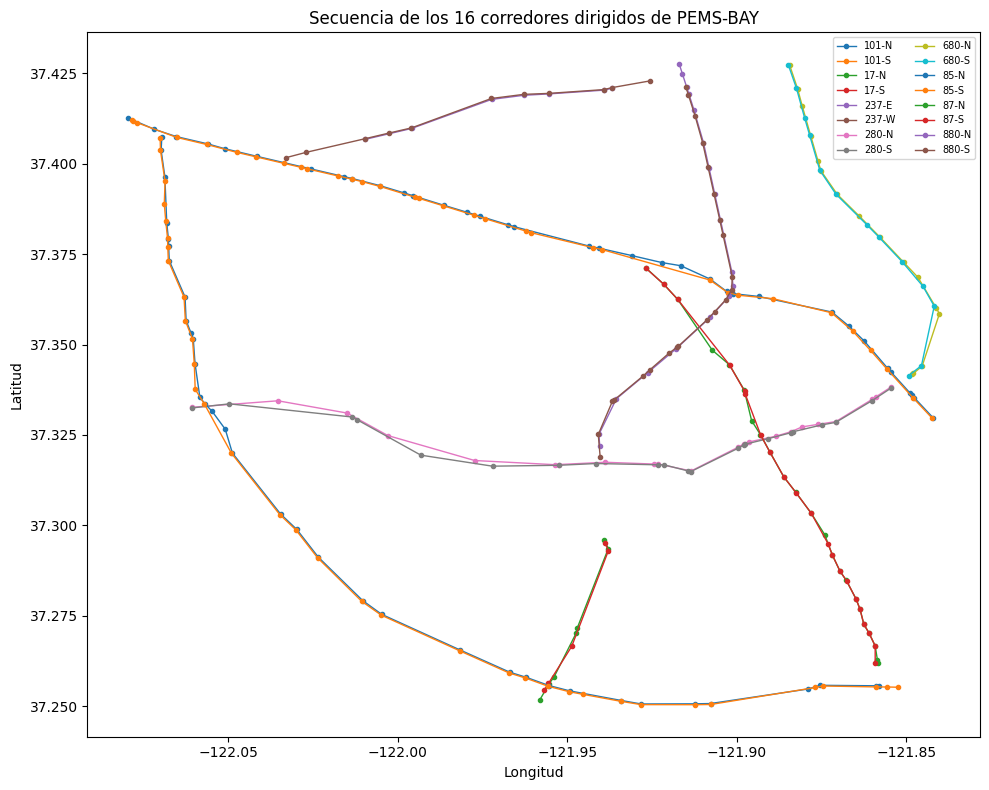

In [ ]:
# Visualización de las secuencias dirigidas.
# Las líneas son una representación reducida entre sensores consecutivos;
# no pretenden reproducir cada curva de la carretera.
plt.figure(figsize=(10, 8))

for corridor, group in seq_meta.groupby('Freeway-Direction'):
    g = group.sort_values('Sensor Order')
    plt.plot(
        g['Longitude'],
        g['Latitude'],
        marker='.',
        linewidth=1,
        label=corridor
    )

plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('Secuencia de los 16 corredores dirigidos de PEMS-BAY')
plt.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

### Secuencia espacial de los corredores dirigidos

A partir de `Sensor Order` se representan los **16 corredores dirigidos** definidos en *Augmented PEMS-BAY*. Los puntos corresponden a los sensores y las líneas unen, únicamente con fines de visualización, sensores consecutivos dentro de cada corredor.

Estas líneas **no representan el trazado vial exacto entre sensores**. Se muestran como segmentos rectos entre sus coordenadas para hacer visible la secuencia proporcionada por los metadatos. La distancia utilizada posteriormente para las aristas de la red no se obtiene de la longitud de estos segmentos gráficos.

La representación confirma que el orden de los sensores produce trayectorias espacialmente coherentes con los corredores viales y permite definir la estructura intracorredor de la red experimental. Para cada corredor dirigido, un sensor se conecta con el siguiente de acuerdo con `Sensor Order`.

En esta etapa los corredores permanecen independientes entre sí. Las conexiones entre autopistas se incorporan posteriormente utilizando la topología vial de OpenStreetMap.

## 5. Red intracorredor

Dentro de cada corredor se conecta el sensor de orden \(k\) con el sensor de orden \(k+1\). Para 325 sensores repartidos en 16 corredores, el número esperado de aristas consecutivas es:

\[
325 - 16 = 309.
\]

La distancia almacenada en esta etapa se obtiene de la diferencia de `Postmile` y se conserva como atributo geométrico. **Todavía no es un tiempo de viaje.**

In [ ]:
corridor_edge_rows = []

for corridor, group in seq_meta.groupby('Freeway-Direction'):

    g = (
        group
        .sort_values('Sensor Order')
        .reset_index(drop=True)
    )

    for i in range(len(g) - 1):

        a = g.iloc[i]
        b = g.iloc[i + 1]

        corridor_edge_rows.append({
            'from': a['Sensor'],
            'to': b['Sensor'],
            'corridor': corridor,
            'order_from': int(a['Sensor Order']),
            'order_to': int(b['Sensor Order']),
            'postmile_from': a['Postmile'],
            'postmile_to': b['Postmile'],

            # Postmile está expresado en millas; se convierte a km.
            'distance_km': (
                abs(b['Postmile'] - a['Postmile'])
                * 1.609344
            )
        })

corridor_edges = pd.DataFrame(corridor_edge_rows)

print('RED INTRACORREDOR')
print('-' * 70)
print('Sensores:', seq_meta['Sensor'].nunique())
print('Corredores:', seq_meta['Freeway-Direction'].nunique())
print('Aristas:', len(corridor_edges))
print('Esperadas:', 325 - 16)
print('Pares duplicados:',
      int(corridor_edges.duplicated(['from', 'to']).sum()))

display(corridor_edges.head(10))

RED INTRACORREDOR
----------------------------------------------------------------------
Sensores: 325
Corredores: 16
Aristas: 309
Esperadas: 309
Pares duplicados: 0


,from,to,corridor,order_from,order_to,postmile_from,postmile_to,distance_km
0,402359,401908,101-N,1,2,383.633,384.123,0.788579
1,401908,400804,101-N,2,3,384.123,384.193,0.112654
2,400804,402361,101-N,3,4,384.193,384.233,0.064374
3,402361,400400,101-N,4,5,384.233,384.743,0.820765
4,400400,401890,101-N,5,6,384.743,384.833,0.144841
5,401890,400996,101-N,6,7,384.833,385.473,1.029980
6,400996,400668,101-N,7,8,385.473,385.853,0.611551
7,400668,402362,101-N,8,9,385.853,386.237,0.617988
8,402362,400965,101-N,9,10,386.237,387.477,1.995587
9,400965,400001,101-N,10,11,387.477,387.897,0.675924


## 6. OpenStreetMap como fuente auxiliar de validación

PEMS-BAY y *Augmented PEMS-BAY* proporcionan la estructura primaria de la red:
sensores, coordenadas y secuencias dirigidas dentro de cada corredor. Sin embargo,
no describen explícitamente la infraestructura existente entre corredores próximos.

OpenStreetMap (OSM) se incorpora como una **fuente auxiliar de validación espacial**.
Su propósito es apoyar la revisión de conexiones candidatas sugeridas por la
geometría de los corredores PEMS-BAY y, cuando resulte necesario, proporcionar
contexto sobre la infraestructura vial existente.

OSM no se utilizará para reconstruir exhaustivamente todas las rampas ni para
imponer a la red experimental una réplica exacta de la red vial real. La red
experimental conserva deliberadamente un nivel de abstracción compatible con el
objetivo posterior de construir tiempos de recorrido a partir de las velocidades
históricas observadas.

In [ ]:
# ------------------------------------------------------------
# Funciones auxiliares para el procesamiento de OpenStreetMap
# ------------------------------------------------------------

def haversine_m(lat1, lon1, lat2, lon2):
    """Calcula la distancia Haversine entre dos coordenadas, en metros."""
    R = 6_371_000

    phi1 = radians(lat1)
    phi2 = radians(lat2)

    dphi = radians(lat2 - lat1)
    dlambda = radians(lon2 - lon1)

    a = (
        sin(dphi / 2) ** 2
        + cos(phi1) * cos(phi2) * sin(dlambda / 2) ** 2
    )

    return 2 * R * atan2(sqrt(a), sqrt(1 - a))


def extract_numbers(value):
    """
    Extrae identificadores numéricos de referencias OSM.

    Las referencias pueden almacenarse como un valor único o como
    una colección de valores.
    """
    if value is None:
        return set()

    values = value if isinstance(value, (list, tuple, set)) else [value]

    result = set()

    for item in values:
        if item is None or pd.isna(item):
            continue

        result.update(re.findall(r'\d+', str(item)))

    return result


def highway_values(value):
    """
    Normaliza el atributo `highway` de OSM como un conjunto de cadenas.
    """
    if value is None:
        return set()

    values = value if isinstance(value, (list, tuple, set)) else [value]

    return {
        str(item)
        for item in values
        if item is not None and not pd.isna(item)
    }


# Tipos de vía que OSM utiliza para representar rampas o enlaces
# asociados con autopistas y vías troncales.
LINK_TYPES = {
    'motorway_link',
    'trunk_link'
}


def is_link(value):
    """Indica si una arista OSM corresponde a una rampa o enlace."""
    return bool(highway_values(value) & LINK_TYPES)

In [ ]:
# ------------------------------------------------------------
# Descarga de la red vial auxiliar de OpenStreetMap
# ------------------------------------------------------------

# Envolvente espacial de los 325 sensores con un margen aproximado.
PAD = 0.02

left = seq_meta['Longitude'].min() - PAD
right = seq_meta['Longitude'].max() + PAD
bottom = seq_meta['Latitude'].min() - PAD
top = seq_meta['Latitude'].max() + PAD

bbox = (left, bottom, right, top)

# Se restringe la descarga a autopistas, vías troncales
# y sus respectivas rampas/enlaces.
freeway_filter = (
    '["highway"~"motorway|motorway_link|trunk|trunk_link"]'
)

# Grafo no simplificado:
# conserva la granularidad necesaria para analizar rampas,
# movimientos dirigidos y realizar posteriormente el snap.
G_osm_raw = ox.graph.graph_from_bbox(
    bbox,
    network_type='drive',
    simplify=False,
    retain_all=True,
    truncate_by_edge=True,
    custom_filter=freeway_filter
)

# Representación simplificada auxiliar:
# reduce nodos intermedios sin eliminar la estructura vial principal.
G_osm = ox.simplification.simplify_graph(
    G_osm_raw.copy()
)

print(
    'OSM RAW   - nodos:', len(G_osm_raw.nodes),
    'aristas:', len(G_osm_raw.edges)
)

print(
    'OSM SIMPL - nodos:', len(G_osm.nodes),
    'aristas:', len(G_osm.edges)
)

OSM RAW   - nodos: 20466 aristas: 20967
OSM SIMPL - nodos: 1885 aristas: 2269


## 7. Identificación y revisión de zonas candidatas de intercambio

La red intracorredor construida en las secciones anteriores representa la
secuencia dirigida de los sensores PEMS-BAY dentro de cada corredor. Para integrar
estos corredores en una sola red experimental es necesario identificar zonas de
la infraestructura vial donde puedan realizarse transferencias entre corredores.

OpenStreetMap se utiliza como fuente auxiliar para localizar infraestructura de
intercambio asociada con las autopistas presentes en PEMS-BAY. Las zonas
identificadas se consideran **candidatas de intercambio** y posteriormente se
consolidan para evitar representar varias veces una misma infraestructura física.

La identificación de una zona mediante OSM y su asociación con determinadas
autopistas no implica que todos los corredores PEMS-BAY correspondientes deban
conectarse al macronodo. La cobertura instrumentada puede comenzar o terminar
antes de alcanzar el intercambio, o encontrarse demasiado alejada para establecer
un anclaje funcionalmente razonable.

Por ello, las zonas candidatas se conservan como referencias de infraestructura y
su incorporación a la red experimental se determina posteriormente
**corredor por corredor**. Para cada zona se revisa la cobertura PEMS-BAY disponible
con el propósito de identificar qué corredores pueden proporcionar entradas,
salidas o ambas respecto del macronodo.

### 7.1 Identificación de componentes de intercambio en OSM

Las rampas y enlaces representados en OSM mediante las categorías
`motorway_link` y `trunk_link` se utilizan para identificar posibles zonas de
intercambio.

Se forman componentes conexas con estas aristas y se conservan únicamente aquellas
asociadas con al menos dos de las ocho autopistas representadas en PEMS-BAY.
Una misma zona física puede generar varias componentes, por lo que el resultado
de esta etapa todavía no constituye el conjunto final de zonas candidatas.

In [ ]:
# ------------------------------------------------------------
# 7.1 Identificación inicial de componentes de intercambio
# ------------------------------------------------------------

KNOWN_FREEWAYS = {
    '17', '85', '87', '101',
    '237', '280', '680', '880'
}

# Grafo auxiliar formado únicamente por rampas/enlaces.
G_links = nx.Graph()

for u, v, k, data in G_osm.edges(keys=True, data=True):

    if is_link(data.get('highway')):
        G_links.add_edge(u, v)

link_components = list(nx.connected_components(G_links))

interchange_rows = []

for component_id, nodes in enumerate(link_components):

    freeway_refs = set()

    # Identificar las autopistas principales incidentes
    # en cada componente de rampas.
    for node in nodes:

        incident_edges = (
            list(G_osm.in_edges(node, keys=True, data=True))
            + list(G_osm.out_edges(node, keys=True, data=True))
        )

        for u, v, k, data in incident_edges:

            if is_link(data.get('highway')):
                continue

            freeway_refs.update(
                extract_numbers(data.get('ref'))
            )

    freeway_refs &= KNOWN_FREEWAYS

    # Sólo interesan componentes asociadas con
    # al menos dos autopistas PEMS-BAY.
    if len(freeway_refs) < 2:
        continue

    xs = [G_osm.nodes[n]['x'] for n in nodes]
    ys = [G_osm.nodes[n]['y'] for n in nodes]

    interchange_rows.append({
        'component_id': component_id,
        'freeways': tuple(sorted(freeway_refs, key=int)),
        'n_link_nodes': len(nodes),
        'longitude': float(np.mean(xs)),
        'latitude': float(np.mean(ys))
    })

interchange_components = pd.DataFrame(interchange_rows)

assert not interchange_components.empty
assert interchange_components['component_id'].is_unique

print('Componentes *_link en OSM:', len(link_components))
print(
    'Componentes asociadas con al menos dos autopistas PEMS-BAY:',
    len(interchange_components)
)

display(
    interchange_components
    .sort_values(['freeways', 'latitude'])
    .reset_index(drop=True)
)

Componentes *_link en OSM: 620
Componentes asociadas con al menos dos autopistas PEMS-BAY: 46


,component_id,freeways,n_link_nodes,longitude,latitude
0,572,"(101, 237)",2,-122.035878,37.399320
1,573,"(101, 237)",2,-122.035700,37.400691
2,355,"(101, 237)",2,-122.035218,37.400779
3,16,"(101, 237)",4,-122.034819,37.401980
4,90,"(101, 280, 680)",12,-121.848664,37.336879
5,114,"(101, 280, 680)",6,-121.849624,37.338674
6,165,"(101, 280, 680)",8,-121.851062,37.339117
7,555,"(101, 880)",2,-121.900741,37.362868
8,203,"(101, 880)",2,-121.901738,37.363805
9,297,"(101, 880)",2,-121.902301,37.363869


### 7.2 Consolidación espacial de componentes de intercambio

Un mismo intercambio vial puede estar representado en OpenStreetMap por varias
componentes de rampas espacialmente próximas. Por ello, las componentes
identificadas en la etapa anterior se agrupan para obtener zonas candidatas de
intercambio.

La consolidación se realiza en dos etapas. Primero se agrupan componentes cuya
separación espacial es de hasta 500 m. Posteriormente, los grupos resultantes
pueden fusionarse cuando se encuentran a una distancia máxima de 800 m y comparten
al menos una autopista.

Estos valores se utilizan como parámetros de construcción de la representación
experimental y no constituyen umbrales generales para la identificación de
intercambios viales.

In [ ]:
# ------------------------------------------------------------
# 7.2 Consolidación de componentes en zonas candidatas
# ------------------------------------------------------------

FIRST_STAGE_M = 500
SECOND_STAGE_M = 800
EARTH_RADIUS_M = 6_371_000


# ------------------------------------------------------------
# Primera consolidación: componentes próximas
# ------------------------------------------------------------

coords_rad = np.radians(
    interchange_components[
        ['latitude', 'longitude']
    ].to_numpy()
)

clustering = DBSCAN(
    eps=FIRST_STAGE_M / EARTH_RADIUS_M,
    min_samples=1,
    metric='haversine'
).fit(coords_rad)

components_clustered = interchange_components.copy()
components_clustered['group_id'] = clustering.labels_


def union_freeways(series):
    """Une las autopistas asociadas con varias componentes."""
    freeways = set()

    for item in series:
        freeways.update(item)

    return tuple(sorted(freeways, key=int))


physical_groups = (
    components_clustered
    .groupby('group_id')
    .agg(
        freeways=('freeways', union_freeways),
        n_components=('component_id', 'size'),
        n_link_nodes=('n_link_nodes', 'sum'),
        latitude=('latitude', 'mean'),
        longitude=('longitude', 'mean')
    )
    .reset_index()
)


# ------------------------------------------------------------
# Segunda consolidación:
# grupos próximos que comparten alguna autopista
# ------------------------------------------------------------

H = nx.Graph()
H.add_nodes_from(physical_groups['group_id'])

groups = physical_groups.reset_index(drop=True)

for i in range(len(groups)):
    for j in range(i + 1, len(groups)):

        a = groups.iloc[i]
        b = groups.iloc[j]

        if not (set(a['freeways']) & set(b['freeways'])):
            continue

        distance_m = haversine_m(
            a['latitude'],
            a['longitude'],
            b['latitude'],
            b['longitude']
        )

        if distance_m <= SECOND_STAGE_M:
            H.add_edge(
                a['group_id'],
                b['group_id'],
                distance_m=distance_m
            )


# ------------------------------------------------------------
# Zonas candidatas finales
# ------------------------------------------------------------

candidate_rows = []

for component in nx.connected_components(H):

    group = physical_groups[
        physical_groups['group_id'].isin(component)
    ]

    freeways = set()

    for item in group['freeways']:
        freeways.update(item)

    freeways = tuple(sorted(freeways, key=int))

    weights = group['n_link_nodes'].to_numpy()

    candidate_rows.append({
        'freeways': freeways,
        'label': '-'.join(freeways),
        'n_components': int(group['n_components'].sum()),
        'n_link_nodes': int(group['n_link_nodes'].sum()),
        'latitude': np.average(
            group['latitude'],
            weights=weights
        ),
        'longitude': np.average(
            group['longitude'],
            weights=weights
        )
    })


interchange_candidates = (
    pd.DataFrame(candidate_rows)
    .sort_values(['label', 'latitude', 'longitude'])
    .reset_index(drop=True)
)

interchange_candidates.insert(
    0,
    'interchange_id',
    range(len(interchange_candidates))
)


# ------------------------------------------------------------
# Resumen
# ------------------------------------------------------------

print(
    'Componentes iniciales:',
    len(interchange_components)
)

print(
    'Grupos después de la primera consolidación:',
    len(physical_groups)
)

print(
    'Zonas candidatas finales:',
    len(interchange_candidates)
)

display(interchange_candidates)

Componentes iniciales: 46
Grupos después de la primera consolidación: 15
Zonas candidatas finales: 13


,interchange_id,freeways,label,n_components,n_link_nodes,latitude,longitude
0,0,"(101, 237)",101-237,4,10,37.400693,-122.035404
1,1,"(101, 280, 680)",101-280-680,5,32,37.339178,-121.849253
2,2,"(101, 880)",101-880,7,14,37.364044,-121.901792
3,3,"(17, 280, 880)",17-280-880,4,28,37.317857,-121.939957
4,4,"(17, 85)",17-85,1,20,37.255875,-121.955618
5,5,"(237, 680)",237-680,1,18,37.434831,-121.888330
6,6,"(237, 880)",237-880,5,22,37.427029,-121.917782
7,7,"(85, 101)",85-101,4,16,37.409213,-122.074128
8,8,"(85, 237)",85-237,4,8,37.384076,-122.068261
9,9,"(85, 280)",85-280,4,22,37.331484,-122.055386


### 7.3 Relación entre zonas candidatas y corredores PEMS-BAY

Las zonas candidatas identificadas mediante OSM se superponen sobre la estructura
espacial de los corredores PEMS-BAY para evaluar su posición respecto de la
cobertura instrumentada.

Esta representación permite distinguir zonas de intercambio que coinciden con
tramos claramente observados por PEMS-BAY de aquellas situadas cerca de los
extremos de cobertura o alejadas de los corredores asociados.

La existencia de una zona candidata no determina todavía su incorporación a la
red experimental. Esta decisión se realiza posteriormente mediante la revisión
conjunta de la infraestructura identificada y la cobertura disponible.

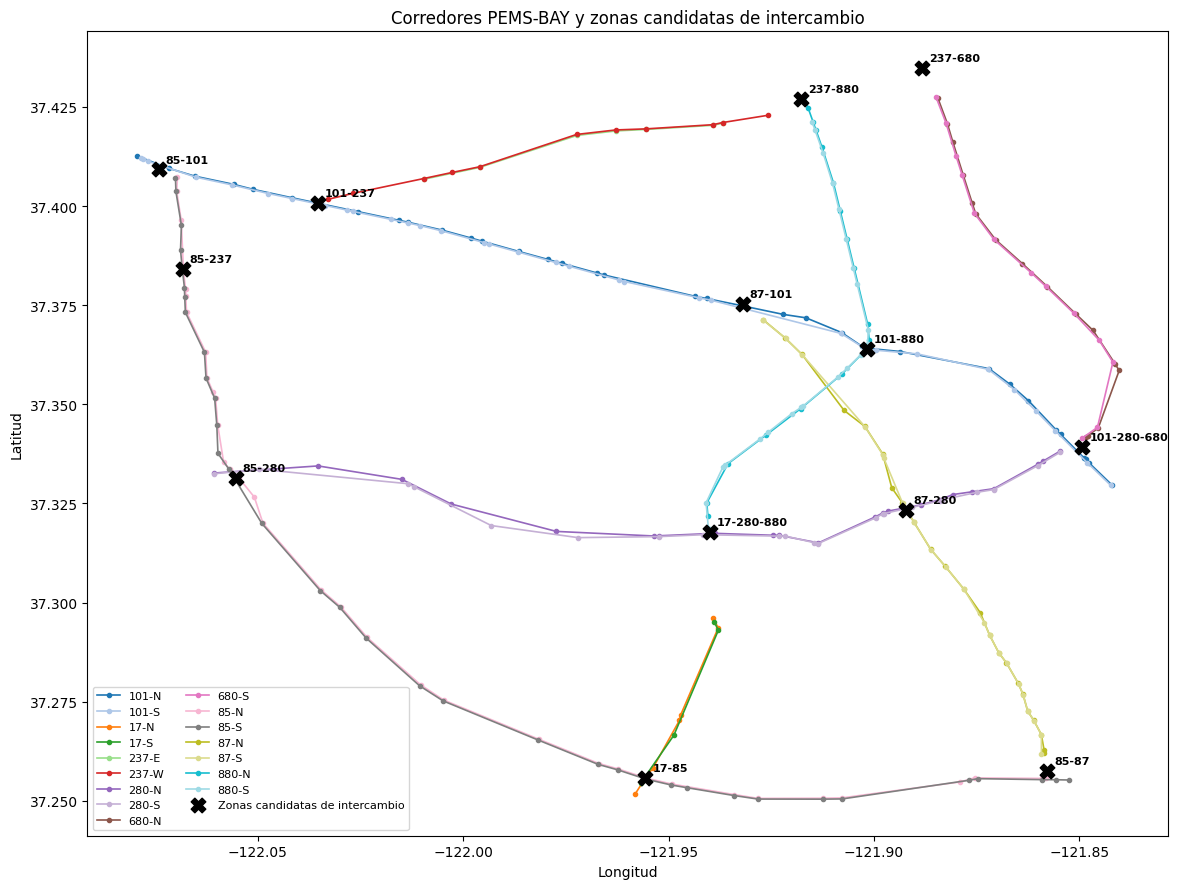

In [ ]:
# ------------------------------------------------------------
# 7.3 Corredores PEMS-BAY y zonas candidatas de intercambio
# ------------------------------------------------------------

corridors = sorted(
    seq_meta['Freeway-Direction'].unique()
)

colors = plt.cm.tab20(
    np.linspace(0, 1, len(corridors))
)

fig, ax = plt.subplots(figsize=(12, 9))

# Corredores dirigidos PEMS-BAY
for corridor, color in zip(corridors, colors):

    g = (
        seq_meta[
            seq_meta['Freeway-Direction'] == corridor
        ]
        .sort_values('Sensor Order')
    )

    ax.plot(
        g['Longitude'],
        g['Latitude'],
        marker='o',
        markersize=3,
        linewidth=1.2,
        color=color,
        label=corridor
    )

# Zonas candidatas identificadas con OSM
ax.scatter(
    interchange_candidates['longitude'],
    interchange_candidates['latitude'],
    marker='X',
    s=110,
    color='black',
    label='Zonas candidatas de intercambio',
    zorder=10
)

# Etiquetas de las zonas candidatas
for _, row in interchange_candidates.iterrows():

    ax.annotate(
        row['label'],
        (
            row['longitude'],
            row['latitude']
        ),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=8,
        fontweight='bold'
    )

ax.set_title(
    'Corredores PEMS-BAY y zonas candidatas de intercambio'
)
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')

ax.legend(
    ncol=2,
    fontsize=8
)

plt.tight_layout()
plt.show()

### Revisión de la cobertura en las zonas candidatas

La superposición permite distinguir zonas cuya infraestructura de intercambio
coincide directamente con la cobertura de los corredores PEMS-BAY y casos en los
que alguno de los corredores instrumentados termina antes de alcanzar la zona
identificada con OSM.

La revisión detallada se concentra en estas últimas situaciones, ya que requieren
determinar qué corredores pueden asociarse de forma funcional con cada zona de
intercambio a partir de la cobertura PEMS-BAY disponible.

### 7.4 Revisión local de zonas con cobertura parcial

Algunas zonas candidatas se encuentran próximas a los extremos de la cobertura
instrumentada. En estos casos se revisa localmente la relación entre la
infraestructura de intercambio y los sensores disponibles antes de decidir si la
zona puede representarse de manera razonable en la red experimental.

,Freeway-Direction,Sensor,Sensor Order,distance_km
80,237-E,404585,1,5.768141
81,237-E,400970,2,6.998365
82,237-E,400973,3,9.270047
83,237-E,400567,4,10.088060
97,237-W,401351,11,3.689356
96,237-W,400581,10,4.222588
95,237-W,404586,9,5.774836
94,237-W,400687,8,6.394353
202,85-N,407325,32,0.043193
201,85-N,407342,31,0.556996


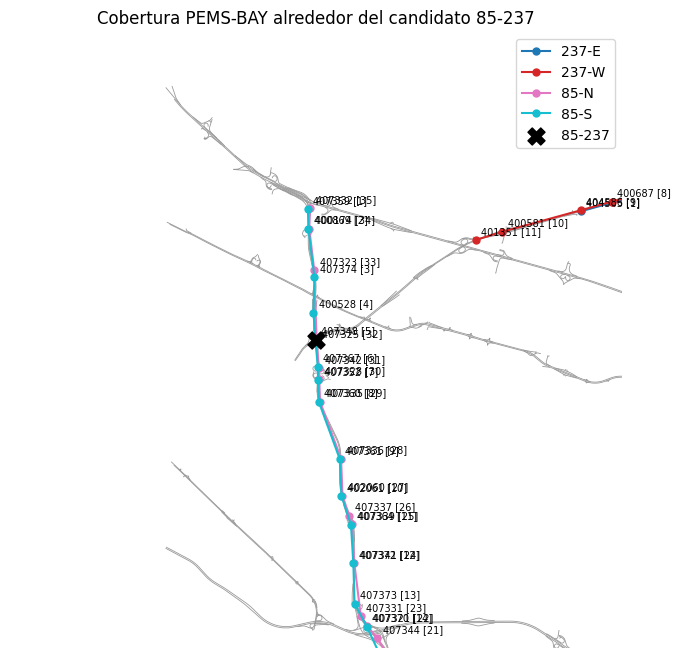

In [ ]:
# ------------------------------------------------------------
# Revisión local del candidato 85-237
# ------------------------------------------------------------

candidate = (
    interchange_candidates[
        interchange_candidates['label'] == '85-237'
    ]
    .iloc[0]
)

lat0 = float(candidate['latitude'])
lon0 = float(candidate['longitude'])

# Corredores de las autopistas involucradas
local = seq_meta[
    seq_meta['Freeway'].astype(str).isin(['85', '237'])
].copy()

# Distancia de cada sensor al punto candidato
local['distance_km'] = local.apply(
    lambda row: haversine_m(
        lat0,
        lon0,
        float(row['Latitude']),
        float(row['Longitude'])
    ) / 1000,
    axis=1
)

# Sensores más próximos de cada corredor
nearest = (
    local
    .sort_values('distance_km')
    .groupby('Freeway-Direction', as_index=False)
    .head(4)
    .sort_values(
        ['Freeway-Direction', 'distance_km']
    )
)

display(
    nearest[
        [
            'Freeway-Direction',
            'Sensor',
            'Sensor Order',
            'distance_km'
        ]
    ]
)


# ------------------------------------------------------------
# Mapa local
# ------------------------------------------------------------

radius_km = 6

dy = radius_km / 110.54
dx = radius_km / (
    111.32 * np.cos(np.deg2rad(lat0))
)

fig, ax = ox.plot_graph(
    G_osm,
    node_size=0,
    edge_linewidth=0.6,
    bgcolor='white',
    show=False,
    close=False
)

ax.set_xlim(lon0 - dx, lon0 + dx)
ax.set_ylim(lat0 - dy, lat0 + dy)

colors = plt.cm.tab10(
    np.linspace(
        0,
        1,
        local['Freeway-Direction'].nunique()
    )
)

for corridor, color in zip(
    sorted(local['Freeway-Direction'].unique()),
    colors
):

    g = (
        local[
            local['Freeway-Direction'] == corridor
        ]
        .sort_values('Sensor Order')
    )

    ax.plot(
        g['Longitude'],
        g['Latitude'],
        marker='o',
        markersize=5,
        linewidth=1.5,
        color=color,
        label=corridor,
        zorder=3
    )

    visible = g[
        g['Longitude'].between(lon0 - dx, lon0 + dx)
        & g['Latitude'].between(lat0 - dy, lat0 + dy)
    ]

    for _, row in visible.iterrows():
        ax.annotate(
            f"{row['Sensor']} [{int(row['Sensor Order'])}]",
            (row['Longitude'], row['Latitude']),
            xytext=(4, 4),
            textcoords='offset points',
            fontsize=7
        )

# Zona candidata
ax.scatter(
    [lon0],
    [lat0],
    marker='X',
    s=150,
    color='black',
    label='85-237',
    zorder=10
)

ax.set_title(
    'Cobertura PEMS-BAY alrededor del candidato 85-237'
)
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend()

plt.show()

,Freeway-Direction,Sensor,Sensor Order,distance_km
86,237-E,400873,7,4.545681
85,237-E,400296,6,4.767317
84,237-E,400104,5,6.175497
83,237-E,400567,4,6.811242
87,237-W,413845,1,3.560881
88,237-W,400158,2,4.544031
89,237-W,401014,3,4.766018
90,237-W,400449,4,6.172718
157,680-N,407150,16,0.907892
156,680-N,407151,15,1.660684


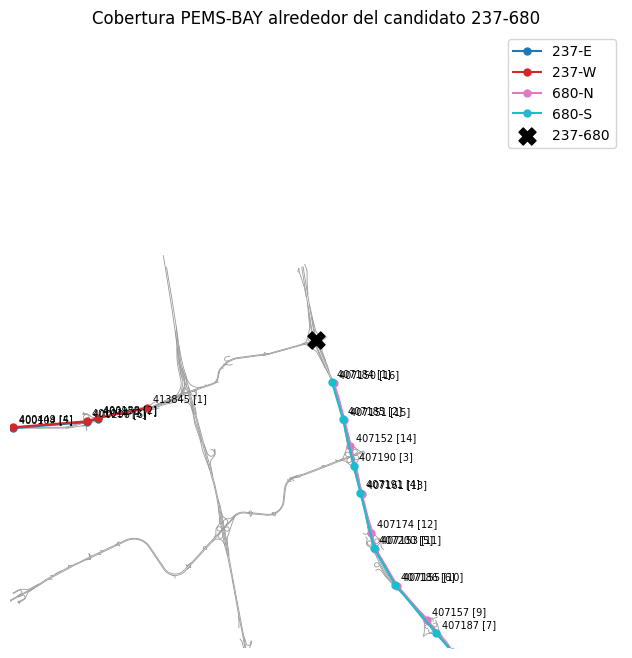

In [ ]:
# ------------------------------------------------------------
# Revisión local del candidato 237-680
# ------------------------------------------------------------

candidate = (
    interchange_candidates[
        interchange_candidates['label'] == '237-680'
    ]
    .iloc[0]
)

lat0 = float(candidate['latitude'])
lon0 = float(candidate['longitude'])

local = seq_meta[
    seq_meta['Freeway'].astype(str).isin(['237', '680'])
].copy()

# Distancia de cada sensor al punto candidato
local['distance_km'] = local.apply(
    lambda row: haversine_m(
        lat0,
        lon0,
        float(row['Latitude']),
        float(row['Longitude'])
    ) / 1000,
    axis=1
)

# Sensores más próximos de cada corredor
nearest = (
    local
    .sort_values('distance_km')
    .groupby('Freeway-Direction', as_index=False)
    .head(4)
    .sort_values(
        ['Freeway-Direction', 'distance_km']
    )
)

display(
    nearest[
        [
            'Freeway-Direction',
            'Sensor',
            'Sensor Order',
            'distance_km'
        ]
    ]
)


# ------------------------------------------------------------
# Mapa local
# ------------------------------------------------------------

radius_km = 6

dy = radius_km / 110.54
dx = radius_km / (
    111.32 * np.cos(np.deg2rad(lat0))
)

fig, ax = ox.plot_graph(
    G_osm,
    node_size=0,
    edge_linewidth=0.6,
    bgcolor='white',
    show=False,
    close=False
)

ax.set_xlim(lon0 - dx, lon0 + dx)
ax.set_ylim(lat0 - dy, lat0 + dy)

colors = plt.cm.tab10(
    np.linspace(
        0,
        1,
        local['Freeway-Direction'].nunique()
    )
)

for corridor, color in zip(
    sorted(local['Freeway-Direction'].unique()),
    colors
):

    g = (
        local[
            local['Freeway-Direction'] == corridor
        ]
        .sort_values('Sensor Order')
    )

    ax.plot(
        g['Longitude'],
        g['Latitude'],
        marker='o',
        markersize=5,
        linewidth=1.5,
        color=color,
        label=corridor,
        zorder=3
    )

    visible = g[
        g['Longitude'].between(lon0 - dx, lon0 + dx)
        & g['Latitude'].between(lat0 - dy, lat0 + dy)
    ]

    for _, row in visible.iterrows():
        ax.annotate(
            f"{row['Sensor']} [{int(row['Sensor Order'])}]",
            (row['Longitude'], row['Latitude']),
            xytext=(4, 4),
            textcoords='offset points',
            fontsize=7
        )

# Zona candidata
ax.scatter(
    [lon0],
    [lat0],
    marker='X',
    s=150,
    color='black',
    label='237-680',
    zorder=10
)

ax.set_title(
    'Cobertura PEMS-BAY alrededor del candidato 237-680'
)
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend()

plt.show()

#### Candidatos 85-237 y 237-680

La inspección local muestra que algunas zonas de intercambio presentan una
cobertura PEMS-BAY marcadamente distinta entre las autopistas asociadas.

En `85-237`, los corredores de la autopista 85 atraviesan la zona de intercambio,
mientras que los sensores disponibles de 237 se encuentran varios kilómetros
alejados. En `237-680` ocurre una situación semejante: los corredores de 680
alcanzan la zona de forma coherente, mientras que la cobertura instrumentada de
237 termina a mayor distancia.

Estas diferencias no constituyen por sí mismas un criterio para eliminar las
zonas de intercambio. Un macronodo puede seguir siendo útil para conectar
corredores con cobertura local adecuada, aun cuando otros corredores asociados
físicamente con el mismo intercambio no puedan anclarse de forma razonable.

La decisión sobre las conexiones efectivas se realiza posteriormente para cada
corredor dirigido.

,Freeway-Direction,Sensor,Sensor Order,distance_km
86,237-E,400873,7,1.806376
85,237-E,400296,6,2.027454
84,237-E,400104,5,3.437783
83,237-E,400567,4,4.077929
87,237-W,413845,1,0.840729
88,237-W,400158,2,1.804197
89,237-W,401014,3,2.025691
90,237-W,400449,4,3.435495
302,880-N,401489,18,0.088461
301,880-N,401464,17,0.288231


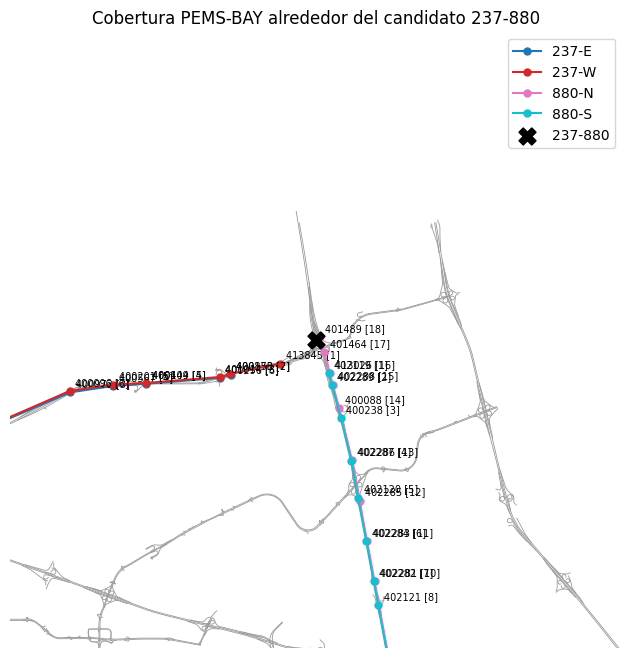

In [ ]:
# ------------------------------------------------------------
# Revisión local del candidato 237-880
# ------------------------------------------------------------

candidate = (
    interchange_candidates[
        interchange_candidates['label'] == '237-880'
    ]
    .iloc[0]
)

lat0 = float(candidate['latitude'])
lon0 = float(candidate['longitude'])

# Corredores de las autopistas involucradas
local = seq_meta[
    seq_meta['Freeway'].astype(str).isin(['237', '880'])
].copy()

# Distancia de cada sensor al punto candidato
local['distance_km'] = local.apply(
    lambda row: haversine_m(
        lat0,
        lon0,
        float(row['Latitude']),
        float(row['Longitude'])
    ) / 1000,
    axis=1
)

# Sensores más próximos de cada corredor
nearest = (
    local
    .sort_values('distance_km')
    .groupby('Freeway-Direction', as_index=False)
    .head(4)
    .sort_values(
        ['Freeway-Direction', 'distance_km']
    )
)

display(
    nearest[
        [
            'Freeway-Direction',
            'Sensor',
            'Sensor Order',
            'distance_km'
        ]
    ]
)

# ------------------------------------------------------------
# Mapa local
# ------------------------------------------------------------

radius_km = 6

dy = radius_km / 110.54
dx = radius_km / (
    111.32 * np.cos(np.deg2rad(lat0))
)

fig, ax = ox.plot_graph(
    G_osm,
    node_size=0,
    edge_linewidth=0.6,
    bgcolor='white',
    show=False,
    close=False
)

ax.set_xlim(lon0 - dx, lon0 + dx)
ax.set_ylim(lat0 - dy, lat0 + dy)

colors = plt.cm.tab10(
    np.linspace(
        0,
        1,
        local['Freeway-Direction'].nunique()
    )
)

for corridor, color in zip(
    sorted(local['Freeway-Direction'].unique()),
    colors
):

    g = (
        local[
            local['Freeway-Direction'] == corridor
        ]
        .sort_values('Sensor Order')
    )

    ax.plot(
        g['Longitude'],
        g['Latitude'],
        marker='o',
        markersize=5,
        linewidth=1.5,
        color=color,
        label=corridor,
        zorder=3
    )

    visible = g[
        g['Longitude'].between(lon0 - dx, lon0 + dx)
        & g['Latitude'].between(lat0 - dy, lat0 + dy)
    ]

    for _, row in visible.iterrows():
        ax.annotate(
            f"{row['Sensor']} [{int(row['Sensor Order'])}]",
            (row['Longitude'], row['Latitude']),
            xytext=(4, 4),
            textcoords='offset points',
            fontsize=7
        )

ax.scatter(
    [lon0],
    [lat0],
    marker='X',
    s=150,
    color='black',
    label='237-880',
    zorder=10
)

ax.set_title(
    'Cobertura PEMS-BAY alrededor del candidato 237-880'
)
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend()

plt.show()

#### Candidato 237–880

La zona de intercambio se encuentra próxima a los extremos instrumentados de
ambas autopistas. En la autopista 237, el sensor más cercano de `237-E`
corresponde al último sensor del corredor y se encuentra aproximadamente a
1.8 km del intercambio, mientras que el sensor más cercano de `237-W`
corresponde al primero y se encuentra a 0.8 km.

En la autopista 880 se observa el mismo patrón: `880-N` termina prácticamente
en la zona de intercambio y `880-S` inicia a menos de 1 km de ella.

La posición y el orden de los sensores son, por tanto, consistentes con una zona
de transición situada en el límite de la cobertura instrumentada. La zona
**237–880 se conserva como conexión candidata para la red experimental**.

,Freeway-Direction,Sensor,Sensor Order,distance_km
74,17-N,404370,7,2.428376
73,17-N,400221,6,2.701842
72,17-N,400436,5,5.171934
71,17-N,403329,4,5.332062
75,17-S,400100,1,2.537620
76,17-S,400298,2,2.764973
77,17-S,400278,3,5.755962
78,17-S,400073,4,6.982612
112,280-N,407710,15,0.112048
113,280-N,401400,16,1.108521


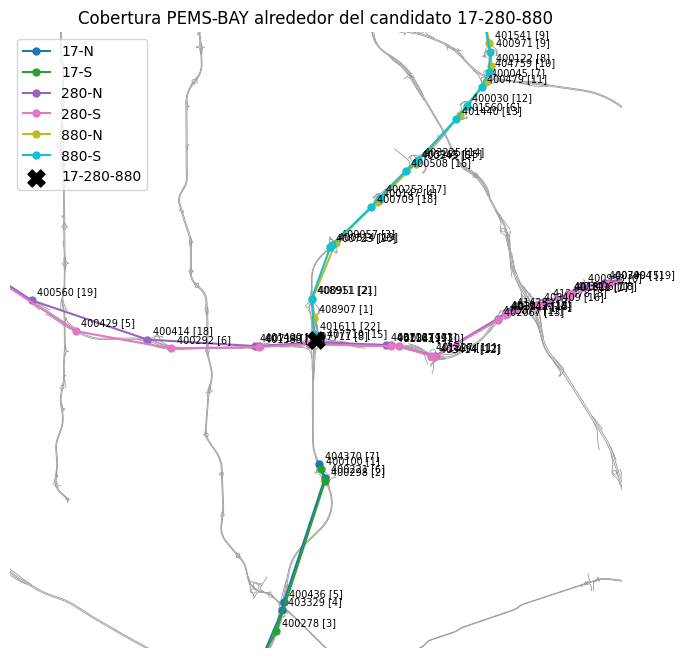

In [ ]:
# ------------------------------------------------------------
# Revisión local del candidato 17-280-880
# ------------------------------------------------------------

candidate = (
    interchange_candidates[
        interchange_candidates['label'] == '17-280-880'
    ]
    .iloc[0]
)

lat0 = float(candidate['latitude'])
lon0 = float(candidate['longitude'])

# Corredores de las tres autopistas involucradas
local = seq_meta[
    seq_meta['Freeway'].astype(str).isin(['17', '280', '880'])
].copy()

# Distancia de cada sensor al punto candidato
local['distance_km'] = local.apply(
    lambda row: haversine_m(
        lat0,
        lon0,
        float(row['Latitude']),
        float(row['Longitude'])
    ) / 1000,
    axis=1
)

# Sensores más próximos de cada corredor
nearest = (
    local
    .sort_values('distance_km')
    .groupby('Freeway-Direction', as_index=False)
    .head(4)
    .sort_values(
        ['Freeway-Direction', 'distance_km']
    )
)

display(
    nearest[
        [
            'Freeway-Direction',
            'Sensor',
            'Sensor Order',
            'distance_km'
        ]
    ]
)


# ------------------------------------------------------------
# Mapa local
# ------------------------------------------------------------

radius_km = 6

dy = radius_km / 110.54
dx = radius_km / (
    111.32 * np.cos(np.deg2rad(lat0))
)

fig, ax = ox.plot_graph(
    G_osm,
    node_size=0,
    edge_linewidth=0.6,
    bgcolor='white',
    show=False,
    close=False
)

ax.set_xlim(lon0 - dx, lon0 + dx)
ax.set_ylim(lat0 - dy, lat0 + dy)

corridors_local = sorted(
    local['Freeway-Direction'].unique()
)

colors = plt.cm.tab10(
    np.linspace(0, 1, len(corridors_local))
)

for corridor, color in zip(corridors_local, colors):

    g = (
        local[
            local['Freeway-Direction'] == corridor
        ]
        .sort_values('Sensor Order')
    )

    ax.plot(
        g['Longitude'],
        g['Latitude'],
        marker='o',
        markersize=5,
        linewidth=1.5,
        color=color,
        label=corridor,
        zorder=3
    )

    visible = g[
        g['Longitude'].between(lon0 - dx, lon0 + dx)
        & g['Latitude'].between(lat0 - dy, lat0 + dy)
    ]

    for _, row in visible.iterrows():
        ax.annotate(
            f"{row['Sensor']} [{int(row['Sensor Order'])}]",
            (row['Longitude'], row['Latitude']),
            xytext=(4, 4),
            textcoords='offset points',
            fontsize=7
        )

ax.scatter(
    [lon0],
    [lat0],
    marker='X',
    s=150,
    color='black',
    label='17-280-880',
    zorder=10
)

ax.set_title(
    'Cobertura PEMS-BAY alrededor del candidato 17-280-880'
)
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend()

plt.show()

#### Candidato 17–280–880

La autopista 280 se encuentra directamente instrumentada en la zona de
intercambio, con sensores de ambos sentidos a menos de 200 m. La cobertura
de 880 también alcanza la zona: `880-N` inicia a aproximadamente 0.4 km y
`880-S` termina a aproximadamente 0.1 km del punto representativo.

La autopista 17 presenta un hueco de instrumentación mayor, de aproximadamente
2.5 km. Sin embargo, la posición de los sensores es consistente con el límite
de cobertura: el sensor más próximo de `17-N` es el último del corredor y el
de `17-S` es el primero. La infraestructura vial observada proporciona además
continuidad espacial entre estos extremos y la zona de intercambio.

En consecuencia, **17–280–880 se conserva como zona candidata de conexión**,
considerando explícitamente el tramo no instrumentado de la autopista 17 en la
construcción posterior de la red experimental.

### 7.5 Revisión conjunta de las zonas restantes

Los casos examinados individualmente muestran que la distancia al intercambio
debe interpretarse junto con la posición del sensor dentro de cada corredor.
En particular, un sensor relativamente alejado puede seguir siendo representativo
cuando corresponde al inicio o al final de la cobertura instrumentada.

Para las zonas restantes se resume, por cada corredor involucrado, el sensor más
próximo al punto representativo del intercambio, su posición dentro de la secuencia
y su distancia. Esta información permite concentrar las inspecciones locales
adicionales únicamente en los casos que permanezcan ambiguos.

In [ ]:
# ------------------------------------------------------------
# 7.5 Resumen de cobertura para las zonas aún no revisadas
# ------------------------------------------------------------

reviewed = {
    '85-237',
    '237-680',
    '237-880',
    '17-280-880'
}

remaining_candidates = interchange_candidates[
    ~interchange_candidates['label'].isin(reviewed)
].copy()

coverage_rows = []

for _, candidate in remaining_candidates.iterrows():

    freeways = {str(f) for f in candidate['freeways']}

    lat0 = float(candidate['latitude'])
    lon0 = float(candidate['longitude'])

    relevant = seq_meta[
        seq_meta['Freeway'].astype(str).isin(freeways)
    ].copy()

    for corridor, group in relevant.groupby('Freeway-Direction'):

        g = group.sort_values('Sensor Order').copy()

        g['distance_km'] = g.apply(
            lambda row: haversine_m(
                lat0,
                lon0,
                float(row['Latitude']),
                float(row['Longitude'])
            ) / 1000,
            axis=1
        )

        nearest = g.loc[g['distance_km'].idxmin()]

        order = int(nearest['Sensor Order'])
        max_order = int(g['Sensor Order'].max())

        if order == 1:
            position = 'start'
        elif order == max_order:
            position = 'end'
        else:
            position = 'interior'

        coverage_rows.append({
            'interchange': candidate['label'],
            'corridor': corridor,
            'sensor': nearest['Sensor'],
            'order': order,
            'n_sensors': max_order,
            'position': position,
            'distance_km': float(nearest['distance_km'])
        })


remaining_coverage = (
    pd.DataFrame(coverage_rows)
    .sort_values(['interchange', 'corridor'])
    .reset_index(drop=True)
)

display(remaining_coverage)

,interchange,corridor,sensor,order,n_sensors,position,distance_km
0,101-237,101-N,404522,30,35,interior,0.570702
1,101-237,101-S,400545,8,33,interior,0.168861
2,101-237,237-E,404585,1,7,start,2.382025
3,101-237,237-W,401351,11,11,end,0.249605
4,101-280-680,101-N,402361,4,35,interior,0.294143
5,101-280-680,101-S,401906,32,33,interior,0.448928
6,101-280-680,280-N,401403,1,22,start,0.482838
7,101-280-680,280-S,401391,22,22,end,0.500174
8,101-280-680,680-N,407172,1,16,start,0.295210
9,101-280-680,680-S,400665,13,13,end,0.251474


### Evaluación conjunta de zonas con cobertura consistente

La revisión individual de los casos anteriores mostró que la distancia entre una
zona de intercambio y el sensor más próximo debe interpretarse junto con la
posición de ese sensor dentro de la secuencia dirigida del corredor.

Con este criterio, varias de las zonas restantes presentan una relación espacial
suficientemente clara con la cobertura de PEMS-BAY como para no requerir una
inspección cartográfica adicional. En estos casos se observa alguno de los
siguientes patrones:

- sensores de ambos sentidos localizados directamente en la zona de intercambio;
- corredores que atraviesan la zona con sensores interiores próximos;
- corredores cuyo inicio o final de cobertura coincide de manera coherente con la
  ubicación del intercambio.

Bajo estas condiciones, las zonas `101-280-680`, `101-880`, `17-85`, `85-101`,
`85-280`, `85-87`, `87-101` y `87-280` se consideran suficientemente respaldadas
por la cobertura observada para conservarse como conexiones candidatas de la red
experimental.

La decisión no se basa en un umbral único de distancia. Se considera conjuntamente
la proximidad espacial y la posición del sensor más cercano dentro del corredor.
La zona `101-237` se mantiene pendiente de revisión debido a que el corredor
`237-E` inicia aproximadamente a 2.4 km del punto representativo del intercambio,
mientras que los demás corredores asociados presentan una cobertura sensiblemente
más próxima.

,Freeway-Direction,Sensor,Sensor Order,distance_km
29,101-N,404522,30,0.570702
28,101-N,401997,29,0.888874
30,101-N,401998,31,1.437092
27,101-N,401996,28,1.803122
42,101-S,400545,8,0.168861
41,101-S,404554,7,0.570516
43,101-S,400743,9,0.649295
44,101-S,400330,10,0.793747
80,237-E,404585,1,2.382025
81,237-E,400970,2,3.629093


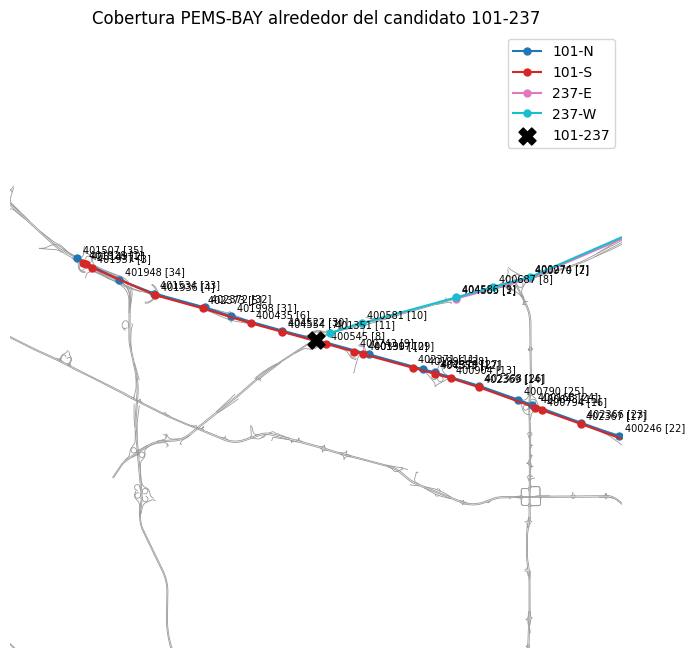

In [ ]:
# ------------------------------------------------------------
# Revisión local del candidato 101-237
# ------------------------------------------------------------

candidate = (
    interchange_candidates[
        interchange_candidates['label'] == '101-237'
    ]
    .iloc[0]
)

lat0 = float(candidate['latitude'])
lon0 = float(candidate['longitude'])

local = seq_meta[
    seq_meta['Freeway'].astype(str).isin(['101', '237'])
].copy()

local['distance_km'] = local.apply(
    lambda row: haversine_m(
        lat0,
        lon0,
        float(row['Latitude']),
        float(row['Longitude'])
    ) / 1000,
    axis=1
)

nearest = (
    local
    .sort_values('distance_km')
    .groupby('Freeway-Direction', as_index=False)
    .head(4)
    .sort_values(
        ['Freeway-Direction', 'distance_km']
    )
)

display(
    nearest[
        [
            'Freeway-Direction',
            'Sensor',
            'Sensor Order',
            'distance_km'
        ]
    ]
)

# ------------------------------------------------------------
# Mapa local
# ------------------------------------------------------------

radius_km = 5

dy = radius_km / 110.54
dx = radius_km / (
    111.32 * np.cos(np.deg2rad(lat0))
)

fig, ax = ox.plot_graph(
    G_osm,
    node_size=0,
    edge_linewidth=0.6,
    bgcolor='white',
    show=False,
    close=False
)

ax.set_xlim(lon0 - dx, lon0 + dx)
ax.set_ylim(lat0 - dy, lat0 + dy)

corridors_local = sorted(
    local['Freeway-Direction'].unique()
)

colors = plt.cm.tab10(
    np.linspace(0, 1, len(corridors_local))
)

for corridor, color in zip(corridors_local, colors):

    g = (
        local[
            local['Freeway-Direction'] == corridor
        ]
        .sort_values('Sensor Order')
    )

    ax.plot(
        g['Longitude'],
        g['Latitude'],
        marker='o',
        markersize=5,
        linewidth=1.5,
        color=color,
        label=corridor,
        zorder=3
    )

    visible = g[
        g['Longitude'].between(lon0 - dx, lon0 + dx)
        & g['Latitude'].between(lat0 - dy, lat0 + dy)
    ]

    for _, row in visible.iterrows():
        ax.annotate(
            f"{row['Sensor']} [{int(row['Sensor Order'])}]",
            (row['Longitude'], row['Latitude']),
            xytext=(4, 4),
            textcoords='offset points',
            fontsize=7
        )

ax.scatter(
    [lon0],
    [lat0],
    marker='X',
    s=150,
    color='black',
    label='101-237',
    zorder=10
)

ax.set_title(
    'Cobertura PEMS-BAY alrededor del candidato 101-237'
)
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend()

plt.show()

#### Candidato 101–237

La autopista 101 presenta cobertura directa en la zona de intercambio, con
sensores de ambos sentidos a menos de 0.6 km del punto representativo.

En la autopista 237 se observa una cobertura asimétrica. El corredor `237-W`
termina aproximadamente a 0.25 km del intercambio, mientras que `237-E` inicia
aproximadamente a 2.38 km. Aunque existe un tramo no instrumentado en este último
sentido, la posición de ambos sensores dentro de sus secuencias es consistente
con los límites de cobertura: `237-W` alcanza su último sensor y `237-E` comienza
en su primer sensor alrededor de la misma zona de transición.

Por esta razón, **101–237 se conserva como zona candidata de conexión**, dejando
explícito que su representación requerirá cubrir un tramo no instrumentado en el
sentido `237-E`.

In [ ]:
# ------------------------------------------------------------
# Zonas candidatas conservadas para la etapa de anclaje
# ------------------------------------------------------------

interchanges_for_anchoring = (
    interchange_candidates
    .copy()
    .reset_index(drop=True)
)

assert len(interchanges_for_anchoring) == 13
assert interchanges_for_anchoring['interchange_id'].is_unique
assert interchanges_for_anchoring['label'].is_unique

print(
    'Zonas candidatas conservadas para la etapa de anclaje:',
    len(interchanges_for_anchoring)
)

display(
    interchanges_for_anchoring[
        [
            'interchange_id',
            'label',
            'freeways',
            'latitude',
            'longitude'
        ]
    ]
)

Zonas candidatas conservadas para la etapa de anclaje: 13


,interchange_id,label,freeways,latitude,longitude
0,0,101-237,"(101, 237)",37.400693,-122.035404
1,1,101-280-680,"(101, 280, 680)",37.339178,-121.849253
2,2,101-880,"(101, 880)",37.364044,-121.901792
3,3,17-280-880,"(17, 280, 880)",37.317857,-121.939957
4,4,17-85,"(17, 85)",37.255875,-121.955618
5,5,237-680,"(237, 680)",37.434831,-121.888330
6,6,237-880,"(237, 880)",37.427029,-121.917782
7,7,85-101,"(85, 101)",37.409213,-122.074128
8,8,85-237,"(85, 237)",37.384076,-122.068261
9,9,85-280,"(85, 280)",37.331484,-122.055386


### 7.6 Zonas candidatas para la etapa de anclaje

La identificación mediante OSM produjo 13 zonas candidatas de intercambio. La
revisión de su cobertura PEMS-BAY mostró que la disponibilidad de sensores no es
uniforme entre las autopistas asociadas con cada zona.

Esta diferencia no se utiliza como criterio para descartar automáticamente un
intercambio. La identificación mediante OSM describe la infraestructura vial
existente, mientras que su incorporación a la red experimental depende de los
corredores PEMS-BAY que puedan asociarse de forma funcional con cada zona.

Por ello, las 13 zonas candidatas se conservan para la etapa de anclaje. En la
sección siguiente se evalúa individualmente cada corredor dirigido para determinar
si proporciona una entrada, una salida o ambas respecto del macronodo
correspondiente.

Esta estrategia permite conservar zonas de intercambio que siguen siendo útiles
para la red experimental aun cuando sólo una parte de las autopistas identificadas
por OSM disponga de cobertura PEMS-BAY adecuada en sus proximidades.

## 8. Representación de las zonas de intercambio mediante macronodos

Las zonas de intercambio conservadas se representan mediante **macronodos** que
abstraen la conectividad existente dentro de cada área de intercambio.

Un macronodo no corresponde a un punto físico exacto de la infraestructura ni
representa una rampa específica. Su función es proporcionar un nodo común de
transición entre los corredores PEMS-BAY que participan en una misma zona.

La red experimental queda formada por dos tipos de nodos:

$$
V = V_P \cup V_I,
$$

donde $V_P$ corresponde a los sensores PEMS-BAY y $V_I$ a los macronodos de
intercambio.

En esta etapa se definen únicamente los macronodos. La asociación de cada uno con
los sensores de los corredores correspondientes se determina posteriormente a
partir de la posición de la zona de intercambio respecto de la secuencia
instrumentada.

In [ ]:
# ------------------------------------------------------------
# 8.1 Construcción de macronodos
# ------------------------------------------------------------

macronodes = interchanges_for_anchoring[
    [
        'interchange_id',
        'label',
        'freeways',
        'latitude',
        'longitude'
    ]
].copy()

# Las autopistas corresponden a la asociación obtenida
# durante la detección de infraestructura en OSM.
macronodes = macronodes.rename(
    columns={'freeways': 'osm_freeways'}
)

# Identificador del nodo dentro de la red experimental.
macronodes.insert(
    0,
    'node_id',
    [f'I{i:02d}' for i in range(len(macronodes))]
)

macronodes['node_type'] = 'interchange'

assert len(macronodes) == 13
assert macronodes['node_id'].is_unique
assert macronodes['interchange_id'].is_unique
assert macronodes['label'].is_unique

display(macronodes)

,node_id,interchange_id,label,osm_freeways,latitude,longitude,node_type
0,I00,0,101-237,"(101, 237)",37.400693,-122.035404,interchange
1,I01,1,101-280-680,"(101, 280, 680)",37.339178,-121.849253,interchange
2,I02,2,101-880,"(101, 880)",37.364044,-121.901792,interchange
3,I03,3,17-280-880,"(17, 280, 880)",37.317857,-121.939957,interchange
4,I04,4,17-85,"(17, 85)",37.255875,-121.955618,interchange
5,I05,5,237-680,"(237, 680)",37.434831,-121.888330,interchange
6,I06,6,237-880,"(237, 880)",37.427029,-121.917782,interchange
7,I07,7,85-101,"(85, 101)",37.409213,-122.074128,interchange
8,I08,8,85-237,"(85, 237)",37.384076,-122.068261,interchange
9,I09,9,85-280,"(85, 280)",37.331484,-122.055386,interchange


### 8.2 Inspección local y anclaje de los macronodos

Cada macronodo representa funcionalmente una zona de intercambio identificada a
partir de la infraestructura vial de OSM. Las autopistas asociadas durante esa
detección se conservan en `osm_freeways`, pero esta asociación no implica que
todos sus corredores PEMS-BAY deban conectarse al macronodo.

La coordenada del macronodo se mantiene fija para todos los corredores asociados
con una misma zona. Debido a que representa una abstracción del intercambio
completo, no se espera que coincida exactamente con cada rampa, incorporación o
trayectoria vial. Los anclajes se determinan respecto de esta misma posición
representativa, sin desplazar el macronodo de forma independiente para cada
corredor.

Para cada zona se examinan individualmente los corredores dirigidos
correspondientes. El objetivo es determinar cuáles disponen de cobertura
PEMS-BAY que permita establecer un anclaje funcionalmente razonable y, para los
corredores seleccionados, identificar sus conexiones de entrada y salida.

Para un corredor dirigido pueden presentarse tres situaciones:

- **Macronodo interior:** la posición representativa del macronodo se encuentra
  entre dos sensores consecutivos $s_k$ y $s_{k+1}$. La conexión se representa
  como

$$
s_k \rightarrow I \rightarrow s_{k+1}.
$$

- **Macronodo anterior al inicio de la cobertura:** la zona de intercambio precede
  al primer sensor disponible del corredor, por lo que puede incorporarse

$$
I \rightarrow s_1.
$$

- **Macronodo posterior al final de la cobertura:** la zona de intercambio se
  encuentra después del último sensor disponible, por lo que puede incorporarse

$$
s_n \rightarrow I.
$$

Cuando la disposición espacial y la cobertura de un corredor no permiten
establecer una asociación funcional razonable con la zona de intercambio, dicho
corredor no se conecta al macronodo. Esto no implica eliminar el macronodo, que
puede conservarse si resulta útil para otros corredores con cobertura adecuada.

Las aristas que llegan al macronodo constituyen sus entradas y las que parten de
él constituyen sus salidas. Una trayectoria que alcance el macronodo por cualquiera
de sus entradas puede continuar por cualquiera de sus salidas, de acuerdo con la
representación funcional de la zona de intercambio.

In [ ]:
def plot_directed_sensors(
    ax,
    g,
    color,
    xmin,
    xmax,
    ymin,
    ymax,
    arrow_fraction=0.20,
    linewidth=1.4,
    mutation_scale=10,
    first_sensor_size=28,
    zorder=4
):
    """
    Dibuja la trayectoria de un corredor.

    - El primer sensor se representa como un punto sólido.
    - Los sensores posteriores se representan mediante una flecha
      cuya punta coincide con la ubicación del sensor.
    - La orientación sigue el incremento de Sensor Order.
    """

    g = (
        g
        .sort_values('Sensor Order')
        .reset_index(drop=True)
    )

    # Trayectoria completa del corredor.
    ax.plot(
        g['Longitude'],
        g['Latitude'],
        linewidth=linewidth,
        color=color,
        zorder=3
    )

    for i in range(len(g)):

        row = g.iloc[i]

        x = float(row['Longitude'])
        y = float(row['Latitude'])

        if not (
            xmin <= x <= xmax
            and ymin <= y <= ymax
        ):
            continue

        # ----------------------------------------------------
        # Primer sensor: no existe segmento previo observado.
        # Se representa como punto.
        # ----------------------------------------------------

        if i == 0:

            ax.scatter(
                [x],
                [y],
                s=first_sensor_size,
                color=color,
                zorder=zorder
            )

            continue

        # ----------------------------------------------------
        # Sensores posteriores: flecha sobre el segmento
        # previo -> sensor actual.
        # ----------------------------------------------------

        prev_row = g.iloc[i - 1]

        prev_x = float(prev_row['Longitude'])
        prev_y = float(prev_row['Latitude'])

        dx = x - prev_x
        dy = y - prev_y

        start_x = x - arrow_fraction * dx
        start_y = y - arrow_fraction * dy

        ax.annotate(
            '',
            xy=(x, y),                  # punta = sensor
            xytext=(start_x, start_y),  # cola sobre la ruta
            arrowprops={
                'arrowstyle': '-|>',
                'color': color,
                'lw': linewidth,
                'mutation_scale': mutation_scale,
                'shrinkA': 0,
                'shrinkB': 0
            },
            zorder=zorder
        )

In [ ]:
# ------------------------------------------------------------
# 8.2 Visor local para el anclaje de macronodos
# ------------------------------------------------------------

def inspect_macronode(
    node_id,
    context_radius_km=3.0,
    detail_radius_km=1.0
):

    # --------------------------------------------------------
    # Macronodo seleccionado
    # --------------------------------------------------------

    macro = (
        macronodes[
            macronodes['node_id'] == node_id
        ]
        .iloc[0]
    )

    lat0 = float(macro['latitude'])
    lon0 = float(macro['longitude'])

    freeways = {
        str(f) for f in macro['osm_freeways']
    }

    local = seq_meta[
        seq_meta['Freeway'].astype(str).isin(freeways)
    ].copy()

    # Distancia de cada sensor al macronodo.
    local['distance_km'] = local.apply(
        lambda row: haversine_m(
            lat0,
            lon0,
            float(row['Latitude']),
            float(row['Longitude'])
        ) / 1000,
        axis=1
    )

    # --------------------------------------------------------
    # Tabla: cuatro sensores más próximos por corredor
    # --------------------------------------------------------

    nearest4 = (
        local
        .sort_values('distance_km')
        .groupby(
            'Freeway-Direction',
            as_index=False
        )
        .head(4)
        .sort_values(
            [
                'Freeway-Direction',
                'Sensor Order'
            ]
        )
    )

    print(
        f"{macro['node_id']} · {macro['label']}"
    )

    display(
        nearest4[
            [
                'Freeway-Direction',
                'Sensor',
                'Sensor Order',
                'distance_km'
            ]
        ]
    )

    # Dos sensores más próximos por corredor.
    nearest2 = (
        local
        .sort_values('distance_km')
        .groupby(
            'Freeway-Direction',
            as_index=False
        )
        .head(2)
    )

    # --------------------------------------------------------
    # Límites de visualización
    # --------------------------------------------------------

    def window_limits(radius_km):

        dy = radius_km / 110.54

        dx = radius_km / (
            111.32
            * np.cos(
                np.deg2rad(lat0)
            )
        )

        return (
            lon0 - dx,
            lon0 + dx,
            lat0 - dy,
            lat0 + dy
        )

    context_limits = window_limits(
        context_radius_km
    )

    detail_limits = window_limits(
        detail_radius_km
    )

    # --------------------------------------------------------
    # Figura
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(16, 8)
    )

    corridors = sorted(
        local['Freeway-Direction'].unique()
    )

    colors = plt.cm.tab10(
        np.linspace(
            0,
            1,
            len(corridors)
        )
    )

    corridor_colors = dict(
        zip(corridors, colors)
    )

    # Posición de etiquetas según sentido.
    label_positions = {
        'N': {
            'xytext': (10, 8),
            'ha': 'left',
            'va': 'bottom'
        },
        'E': {
            'xytext': (10, -8),
            'ha': 'left',
            'va': 'top'
        },
        'S': {
            'xytext': (-10, -8),
            'ha': 'right',
            'va': 'top'
        },
        'W': {
            'xytext': (-10, 8),
            'ha': 'right',
            'va': 'bottom'
        }
    }

    # --------------------------------------------------------
    # Fondo OSM
    # --------------------------------------------------------

    for ax in axes:

        ox.plot_graph(
            G_osm,
            ax=ax,
            node_size=0,
            edge_linewidth=0.6,
            bgcolor='white',
            show=False,
            close=False
        )

    # ========================================================
    # Panel izquierdo: contexto
    # ========================================================

    ax_context = axes[0]

    xmin_c, xmax_c, ymin_c, ymax_c = (
        context_limits
    )

    ax_context.set_xlim(
        xmin_c,
        xmax_c
    )

    ax_context.set_ylim(
        ymin_c,
        ymax_c
    )

    # Macronodo detrás de corredores y sensores.
    ax_context.scatter(
        [lon0],
        [lat0],
        marker='X',
        s=150,
        color='black',
        label=(
            f"{macro['node_id']} · "
            f"{macro['label']}"
        ),
        zorder=2
    )

    for corridor in corridors:

        g = (
            local[
                local['Freeway-Direction'] == corridor
            ]
            .sort_values('Sensor Order')
        )

        color = corridor_colors[corridor]

        plot_directed_sensors(
            ax=ax_context,
            g=g,
            color=color,
            xmin=xmin_c,
            xmax=xmax_c,
            ymin=ymin_c,
            ymax=ymax_c,
            arrow_fraction=0.18,
            linewidth=1.4,
            mutation_scale=9
        )

        # Entrada auxiliar para la leyenda.
        ax_context.plot(
            [],
            [],
            color=color,
            linewidth=1.4,
            label=corridor
        )

    ax_context.set_title(
        f'Contexto · radio {context_radius_km:g} km'
    )

    # ========================================================
    # Panel derecho: detalle
    # ========================================================

    ax_detail = axes[1]

    xmin_d, xmax_d, ymin_d, ymax_d = (
        detail_limits
    )

    ax_detail.set_xlim(
        xmin_d,
        xmax_d
    )

    ax_detail.set_ylim(
        ymin_d,
        ymax_d
    )

    # Macronodo detrás.
    ax_detail.scatter(
        [lon0],
        [lat0],
        marker='X',
        s=150,
        color='black',
        zorder=2
    )

    for corridor in corridors:

        g = (
            local[
                local['Freeway-Direction'] == corridor
            ]
            .sort_values('Sensor Order')
        )

        color = corridor_colors[corridor]

        plot_directed_sensors(
            ax=ax_detail,
            g=g,
            color=color,
            xmin=xmin_d,
            xmax=xmax_d,
            ymin=ymin_d,
            ymax=ymax_d,
            arrow_fraction=0.22,
            linewidth=1.5,
            mutation_scale=11
        )

        # ----------------------------------------------------
        # Sensores visibles
        # ----------------------------------------------------

        visible = g[
            g['Longitude'].between(
                xmin_d,
                xmax_d
            )
            &
            g['Latitude'].between(
                ymin_d,
                ymax_d
            )
        ].copy()

        nearest_sensor_ids = set(
            nearest2.loc[
                nearest2['Freeway-Direction'] == corridor,
                'Sensor'
            ]
            .astype(str)
        )

        visible_labels = visible[
            visible['Sensor']
            .astype(str)
            .isin(nearest_sensor_ids)
        ]

        direction = corridor.split('-')[-1]

        label_style = label_positions[
            direction
        ]

        # ----------------------------------------------------
        # Etiquetas vinculadas al sensor
        # ----------------------------------------------------

        for _, row in visible_labels.iterrows():

            ax_detail.annotate(
                (
                    f"{row['Sensor']} "
                    f"[{int(row['Sensor Order'])}]"
                ),
                (
                    row['Longitude'],
                    row['Latitude']
                ),
                xytext=label_style['xytext'],
                textcoords='offset points',
                fontsize=8,
                color=color,
                ha=label_style['ha'],
                va=label_style['va'],

                # Línea entre texto y sensor.
                arrowprops={
                    'arrowstyle': '-',
                    'color': color,
                    'lw': 0.8,
                    'alpha': 0.8
                },

                # Fondo para mejorar legibilidad.
                bbox={
                    'facecolor': 'white',
                    'edgecolor': 'none',
                    'alpha': 0.75,
                    'pad': 1.0
                },

                zorder=8
            )

    ax_detail.set_title(
        f'Detalle · radio {detail_radius_km:g} km'
    )

    # --------------------------------------------------------
    # Formato general
    # --------------------------------------------------------

    for ax in axes:

        ax.set_xlabel('Longitud')
        ax.set_ylabel('Latitud')

    fig.suptitle(
        f"Anclaje local de "
        f"{macro['node_id']} · "
        f"{macro['label']}",
        fontsize=13,
        y=0.99
    )

    # Leyenda única.
    handles, labels = (
        ax_context.get_legend_handles_labels()
    )

    fig.legend(
        handles,
        labels,
        loc='upper center',
        bbox_to_anchor=(0.5, 0.955),
        ncol=min(len(labels), 6),
        fontsize=8
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.90]
    )

    plt.show()

### Convención de visualización para el anclaje de macronodos

La inspección de cada macronodo utiliza dos vistas complementarias de la misma
zona:

- **Contexto:** muestra una ventana amplia alrededor del intercambio para observar
  cómo llegan los corredores y reconocer posibles extremos o discontinuidades de
  cobertura.
- **Detalle:** utiliza una ventana más reducida para identificar con claridad los
  sensores próximos al macronodo y apoyar la selección de sus anclajes.

Los corredores se representan siguiendo el orden creciente de `Sensor Order`, que
define el sentido dirigido utilizado en la red experimental.

Cada sensor se representa de acuerdo con su posición dentro del corredor:

- el **primer sensor** se muestra como un punto, ya que no existe un segmento previo
  observado que permita representar su llegada;
- los sensores posteriores se muestran mediante una **flecha cuya punta coincide
  con la ubicación del sensor** y cuya orientación sigue el sentido de circulación
  del corredor.

En la vista de detalle se etiquetan únicamente los dos sensores más próximos de
cada corredor. La etiqueta conserva el color del corredor y se vincula mediante
una línea fina con la posición exacta del sensor para evitar ambigüedades cuando
varios sentidos se encuentran próximos.

El macronodo se representa mediante una **X negra** situada en el punto
representativo de la zona de intercambio. La X se dibuja por debajo de los
corredores y sensores para no ocultar elementos relevantes durante la selección
de los anclajes.

La red vial de OSM se mantiene en gris como referencia espacial y no determina por
sí misma la posición de los anclajes.

#### I00 · 101–237

Se revisa la posición del macronodo respecto de los cuatro corredores dirigidos
asociados con las autopistas 101 y 237, con el propósito de identificar los
sensores que deben funcionar como anclajes de entrada y salida.

I00 · 101-237


,Freeway-Direction,Sensor,Sensor Order,distance_km
27,101-N,401996,28,1.803122
28,101-N,401997,29,0.888874
29,101-N,404522,30,0.570702
30,101-N,401998,31,1.437092
41,101-S,404554,7,0.570516
42,101-S,400545,8,0.168861
43,101-S,400743,9,0.649295
44,101-S,400330,10,0.793747
80,237-E,404585,1,2.382025
81,237-E,400970,2,3.629093


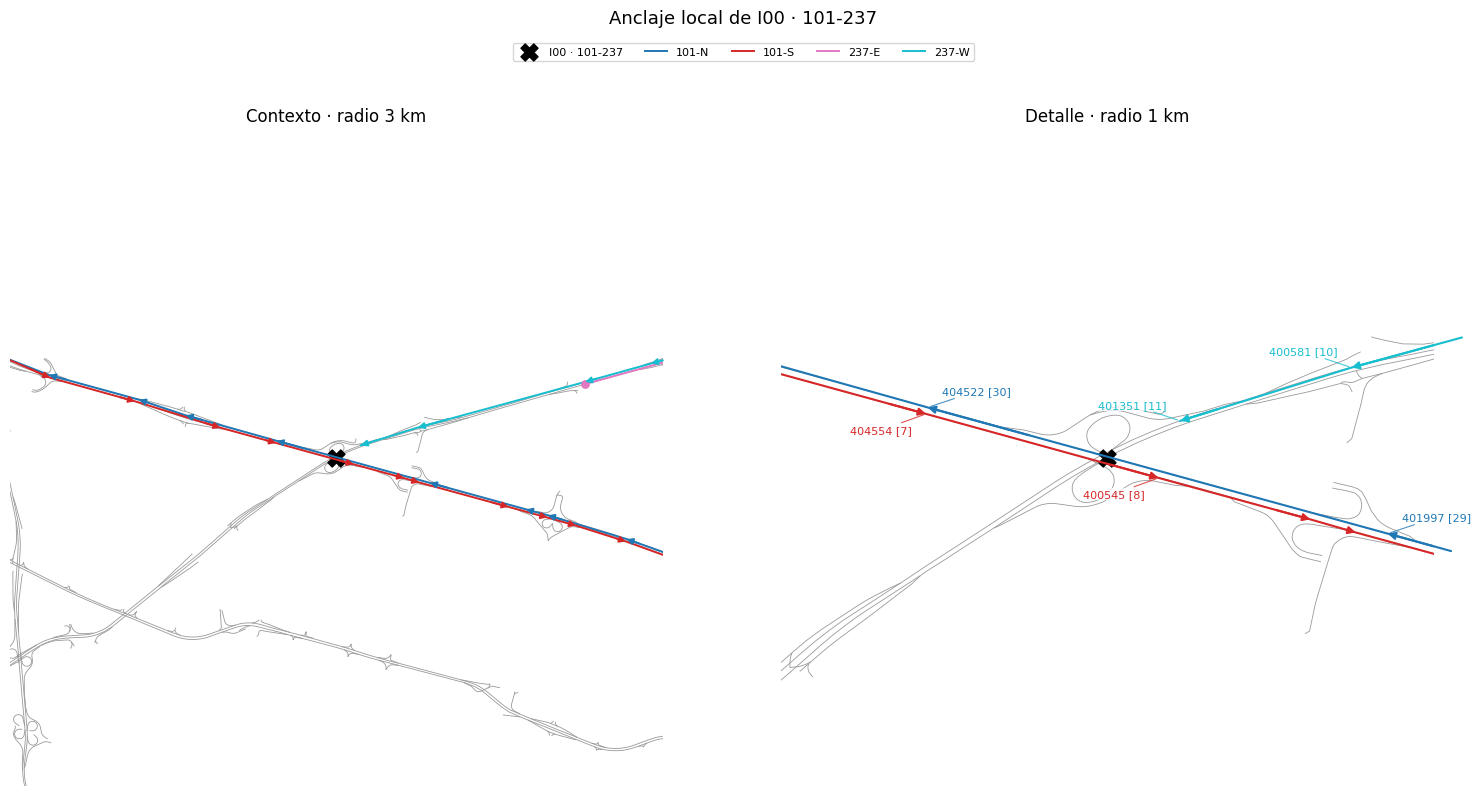

In [ ]:
inspect_macronode('I00')

**Anclaje seleccionado.** El macronodo `I00` se inserta dentro de ambos corredores
de la autopista 101. En `101-N` queda entre los sensores `401997 [29]` y
`404522 [30]`, mientras que en `101-S` queda entre `404554 [7]` y
`400545 [8]`.

En la autopista 237, la cobertura PEMS-BAY termina y comienza a ambos lados de la
zona de intercambio. El corredor `237-W` alcanza como último sensor a
`401351 [11]` antes del macronodo, mientras que `237-E` comienza en
`404585 [1]` después de éste.

Las conexiones dirigidas asociadas con `I00` quedan definidas como:

- `101-N`: `401997 → I00 → 404522`
- `101-S`: `404554 → I00 → 400545`
- `237-W`: `401351 → I00`
- `237-E`: `I00 → 404585`

Con estas conexiones, `I00` funciona como una zona de transferencia entre los
corredores participantes, de acuerdo con la representación funcional definida
para los macronodos.

#### I01 · 101–280–680

Se revisa la posición del macronodo respecto de los corredores dirigidos
asociados con las autopistas 101, 280 y 680 para identificar cuáles admiten
anclajes funcionalmente razonables y determinar sus conexiones de entrada y
salida.

I01 · 101-280-680


,Freeway-Direction,Sensor,Sensor Order,distance_km
1,101-N,401908,2,0.455228
2,101-N,400804,3,0.350939
3,101-N,402361,4,0.294143
4,101-N,400400,5,0.589845
64,101-S,400160,30,1.433203
65,101-S,401891,31,0.737505
66,101-S,401906,32,0.448928
67,101-S,402360,33,1.227842
98,280-N,401403,1,0.482838
99,280-N,401655,2,0.942843


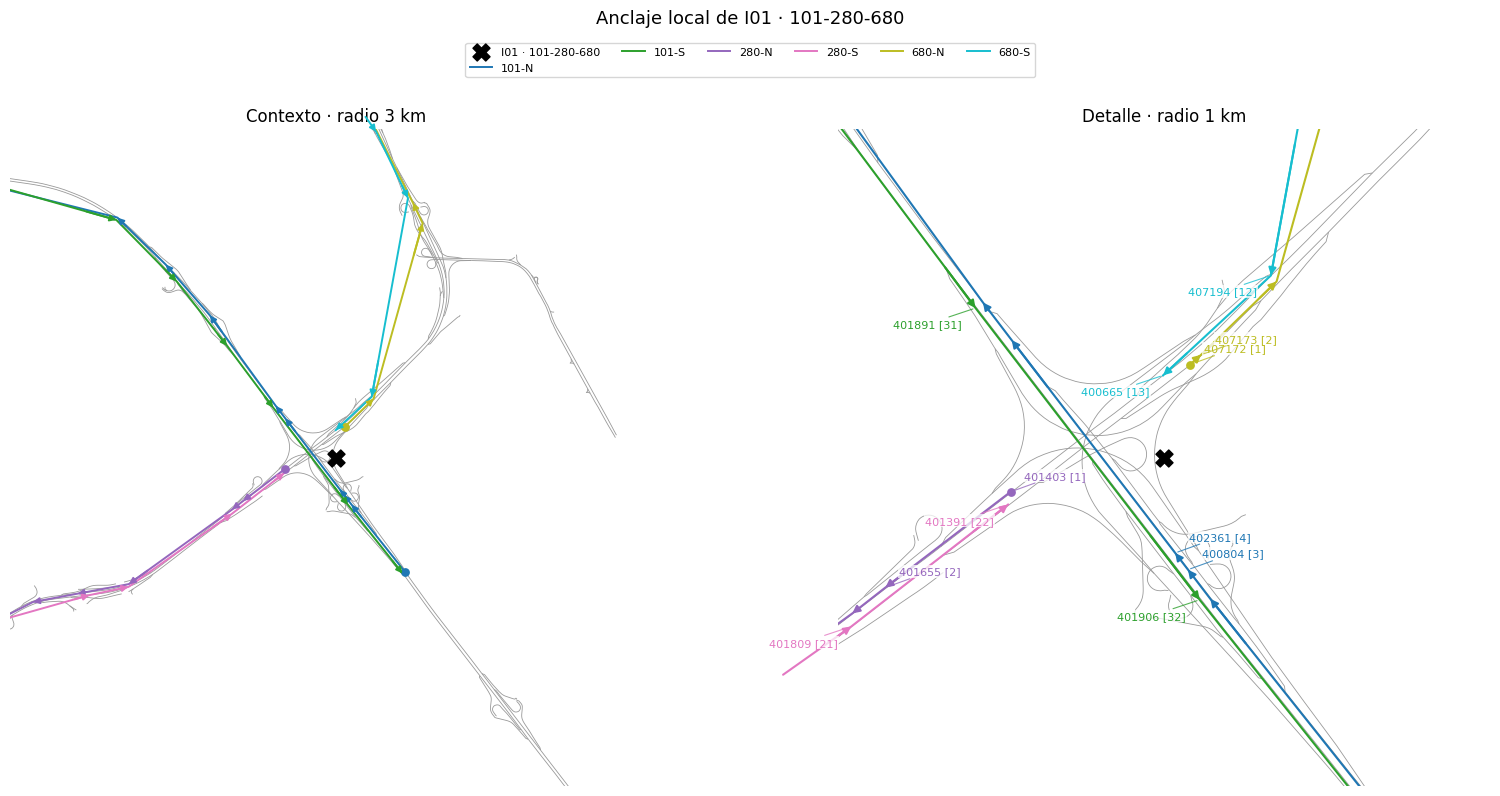

In [ ]:
inspect_macronode('I01')

**Anclaje seleccionado.** Los seis corredores asociados con `I01` presentan una
relación funcional coherente con la zona de intercambio.

Los corredores `101-N` y `101-S` atraviesan la zona y, por tanto, el macronodo se
inserta entre sensores consecutivos. En `101-N` queda entre `402361 [4]` y
`400400 [5]`, mientras que en `101-S` queda entre `401891 [31]` y
`401906 [32]`.

En las autopistas 280 y 680 la cobertura presenta un patrón terminal alrededor
del intercambio. Los corredores `280-S` y `680-S` alcanzan la zona desde sus
últimos sensores, mientras que `280-N` y `680-N` comienzan después de ella.

Las conexiones dirigidas asociadas con `I01` quedan definidas como:

- `101-N`: `402361 → I01 → 400400`
- `101-S`: `401891 → I01 → 401906`
- `280-N`: `I01 → 401403`
- `280-S`: `401391 → I01`
- `680-N`: `I01 → 407172`
- `680-S`: `400665 → I01`

De esta forma, `I01` funciona como una zona de transferencia entre los corredores
de las autopistas 101, 280 y 680.

#### I02 · 101–880

Se revisa la posición del macronodo respecto de los corredores dirigidos
asociados con las autopistas 101 y 880 para identificar cuáles admiten
anclajes funcionalmente razonables y determinar sus conexiones de entrada y
salida.

I02 · 101-880


,Freeway-Direction,Sensor,Sensor Order,distance_km
9,101-N,400965,10,0.729250
10,101-N,400001,11,0.056999
11,101-N,404753,12,0.127837
12,101-N,402364,13,0.702370
58,101-S,402365,24,0.691510
59,101-S,400394,25,0.087998
60,101-S,400922,26,0.204347
61,101-S,400109,27,1.102946
290,880-N,401560,6,0.902856
291,880-N,400045,7,0.081310


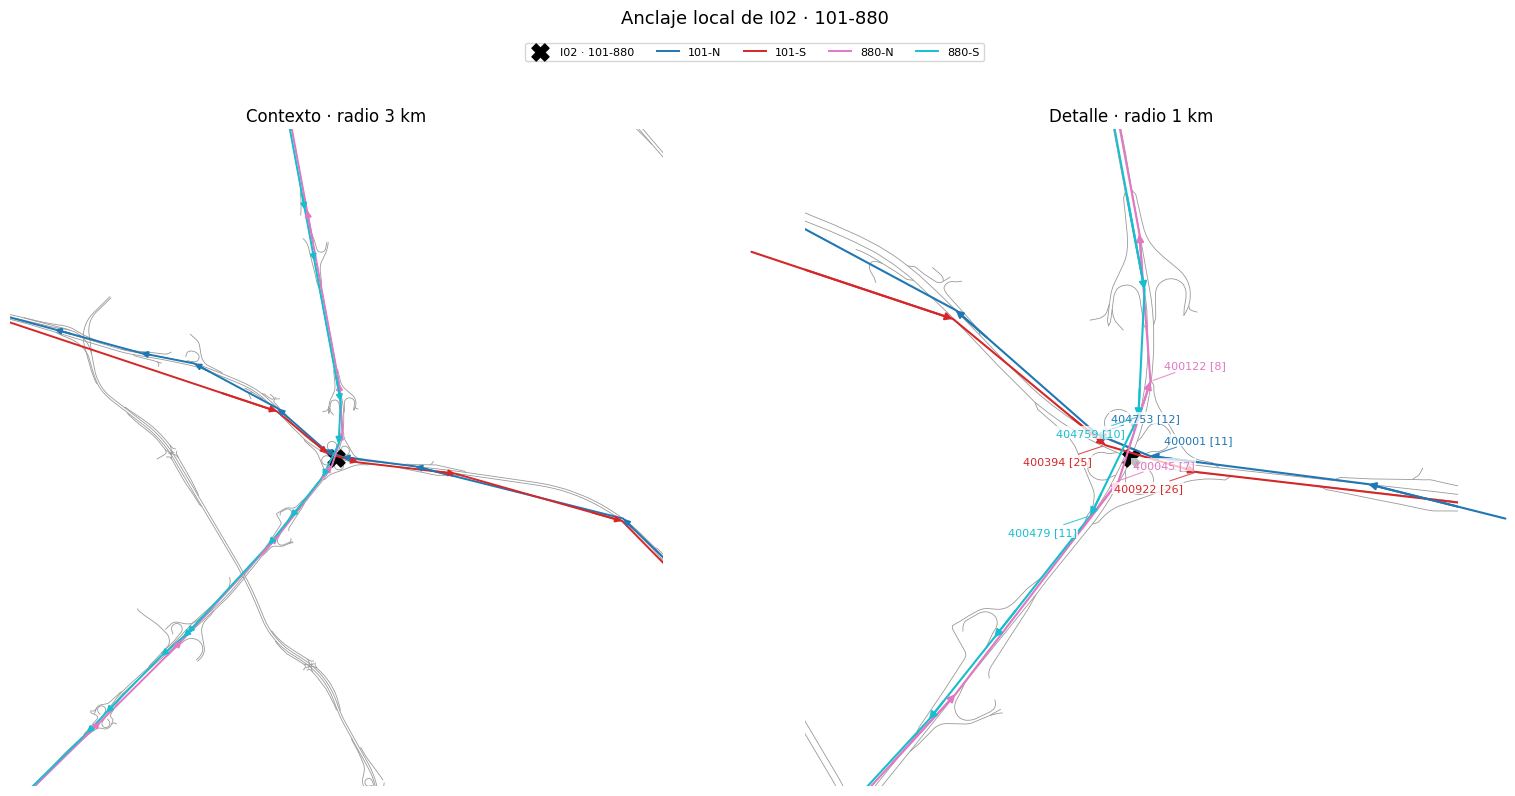

In [ ]:
inspect_macronode('I02')

**Anclaje seleccionado.** Los cuatro corredores asociados con `I02` presentan
cobertura PEMS-BAY en la zona de intercambio y permiten definir anclajes
interiores.

En `101-N`, el macronodo se localiza entre los sensores `400001 [11]` y
`404753 [12]`, mientras que en `101-S` queda entre `400394 [25]` y
`400922 [26]`.

Para la autopista 880, `I02` se ubica entre `400045 [7]` y `400122 [8]` en
`880-N`, y entre `404759 [10]` y `400479 [11]` en `880-S`.

Las conexiones dirigidas asociadas con `I02` quedan definidas como:

- `101-N`: `400001 → I02 → 404753`
- `101-S`: `400394 → I02 → 400922`
- `880-N`: `400045 → I02 → 400122`
- `880-S`: `404759 → I02 → 400479`

De esta forma, `I02` funciona como una zona de transferencia entre ambos sentidos
de las autopistas 101 y 880.

#### I03 · 17–280–880

Se revisa la posición del macronodo respecto de los corredores dirigidos
asociados con las autopistas 17, 280 y 880 para identificar cuáles admiten
anclajes funcionalmente razonables y determinar sus conexiones de entrada y
salida.

I03 · 17-280-880


,Freeway-Direction,Sensor,Sensor Order,distance_km
71,17-N,403329,4,5.332062
72,17-N,400436,5,5.171934
73,17-N,400221,6,2.701842
74,17-N,404370,7,2.428376
75,17-S,400100,1,2.537620
76,17-S,400298,2,2.764973
77,17-S,400278,3,5.755962
78,17-S,400073,4,6.982612
111,280-N,405701,14,1.372135
112,280-N,407710,15,0.112048


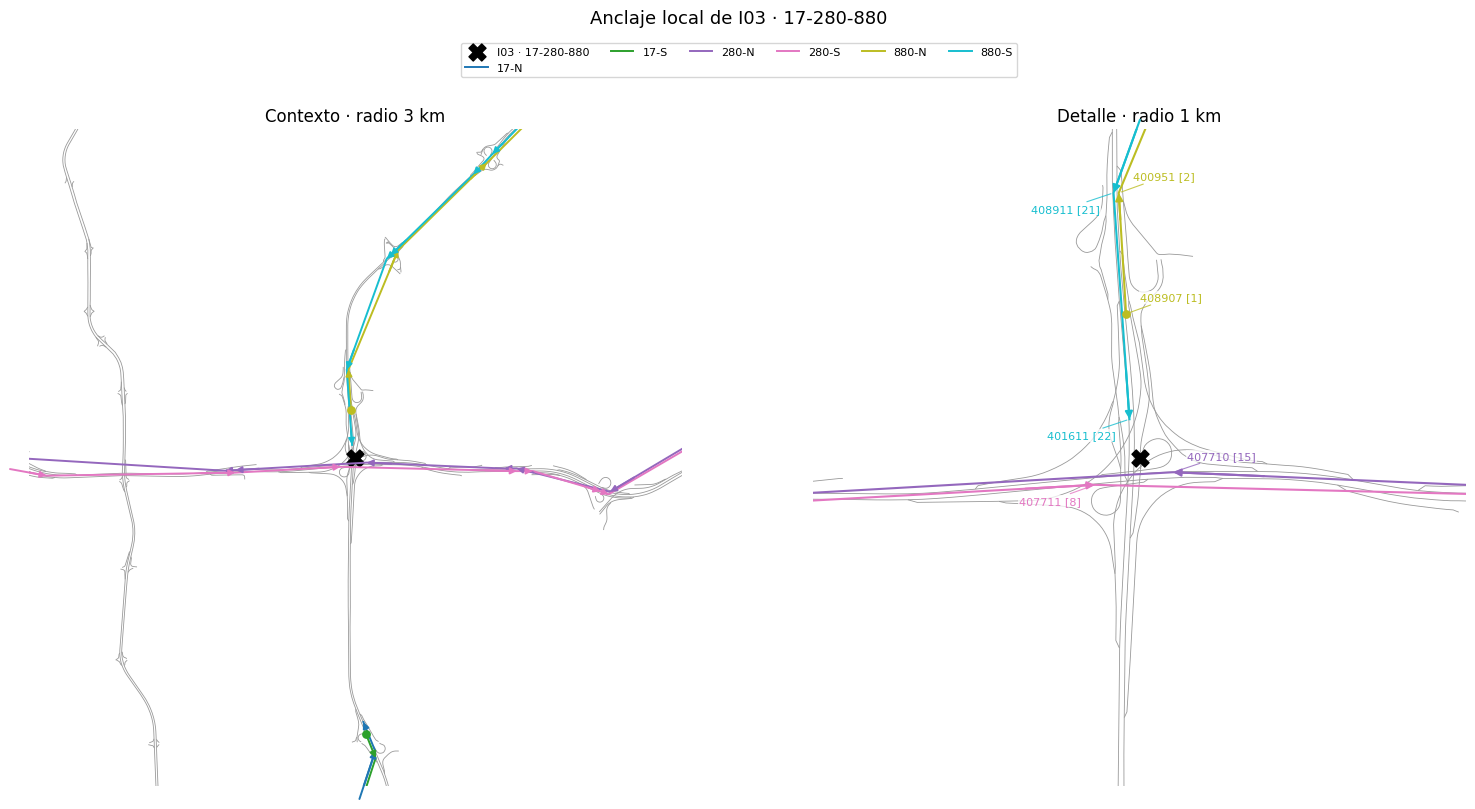

In [ ]:
inspect_macronode('I03')

**Anclaje seleccionado.** Los seis corredores asociados con `I03` permiten
establecer una relación funcional con la zona de intercambio, aunque presentan
distintos patrones de cobertura.

Los corredores `280-N` y `280-S` atraviesan directamente la zona. En `280-N`,
el macronodo se inserta entre `407710 [15]` y `401400 [16]`, mientras que en
`280-S` queda entre `407711 [8]` y `401163 [9]`.

Para la autopista 880 se observa un patrón terminal alrededor del intercambio:
`880-S` alcanza la zona desde su último sensor, `401611 [22]`, mientras que
`880-N` comienza en `408907 [1]`.

La cobertura de la autopista 17 termina aproximadamente 2.5 km antes de la zona
de intercambio. Sin embargo, los sensores involucrados corresponden al último
sensor de `17-N`, `404370 [7]`, y al primero de `17-S`, `400100 [1]`. La
continuidad vial observada en OSM permite interpretar esta separación como un
tramo terminal no instrumentado y conservar ambos corredores en el macronodo.

Las conexiones dirigidas asociadas con `I03` quedan definidas como:

- `17-N`: `404370 → I03`
- `17-S`: `I03 → 400100`
- `280-N`: `407710 → I03 → 401400`
- `280-S`: `407711 → I03 → 401163`
- `880-N`: `I03 → 408907`
- `880-S`: `401611 → I03`

De esta forma, `I03` integra los corredores de las autopistas 17, 280 y 880,
incluyendo extensiones terminales donde la cobertura PEMS-BAY no alcanza
directamente la infraestructura de intercambio.

#### I04 · 17–85

Se revisa la posición del macronodo respecto de los corredores dirigidos
asociados con las autopistas 17 y 85 para identificar cuáles admiten
anclajes funcionalmente razonables y determinar sus conexiones de entrada y
salida.

I04 · 17-85


,Freeway-Direction,Sensor,Sensor Order,distance_km
68,17-N,400649,1,0.510179
69,17-N,400715,2,0.043433
70,17-N,400240,3,0.300514
71,17-N,403329,4,1.759526
76,17-S,400298,2,4.421874
77,17-S,400278,3,1.336986
78,17-S,400073,4,0.047538
79,17-S,400832,5,0.174820
179,85-N,400485,9,0.595341
180,85-N,400822,10,0.027889


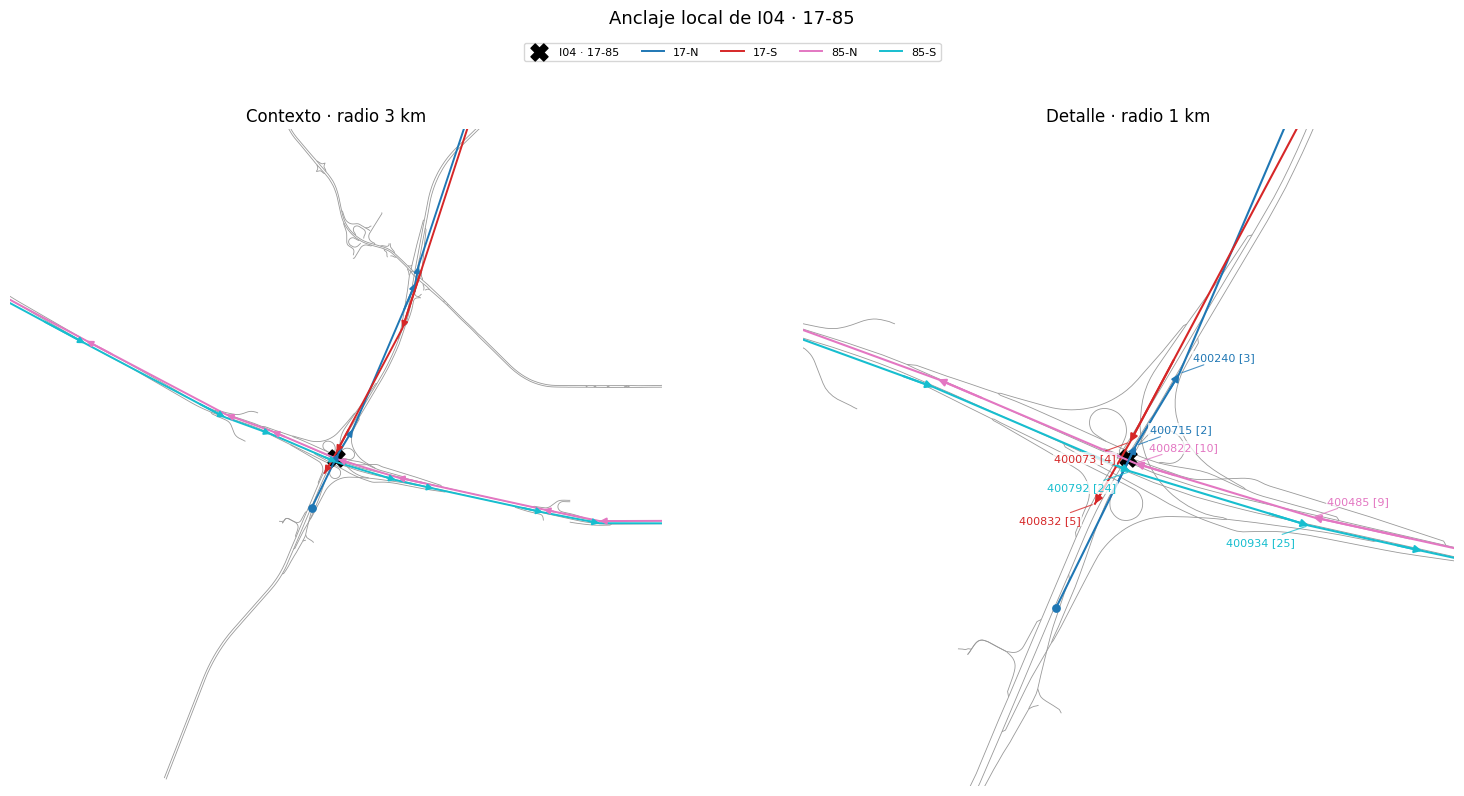

In [ ]:
inspect_macronode('I04')

**Anclaje seleccionado.** Los cuatro corredores asociados con `I04` atraviesan
la zona de intercambio y permiten definir anclajes interiores.

En `17-N`, el macronodo se encuentra entre `400649 [1]` y `400715 [2]`,
mientras que en `17-S` queda entre `400073 [4]` y `400832 [5]`.

Para la autopista 85, `I04` se localiza entre `400822 [10]` y `400464 [11]`
en `85-N`, y entre `400792 [24]` y `400934 [25]` en `85-S`.

Las conexiones dirigidas asociadas con `I04` quedan definidas como:

- `17-N`: `400649 → I04 → 400715`
- `17-S`: `400073 → I04 → 400832`
- `85-N`: `400822 → I04 → 400464`
- `85-S`: `400792 → I04 → 400934`

Este caso muestra que la proximidad al macronodo se utiliza para apoyar la
inspección local, pero la selección del par de anclaje depende también del
orden y del sentido del corredor. El sensor más próximo no determina por sí
solo qué segmento dirigido contiene la zona de intercambio.

#### I05 · 237–680

Se revisa la posición del macronodo respecto de los corredores dirigidos
asociados con las autopistas 237 y 680 para identificar cuáles admiten
anclajes funcionalmente razonables y determinar sus conexiones de entrada y
salida.

I05 · 237-680


,Freeway-Direction,Sensor,Sensor Order,distance_km
83,237-E,400567,4,6.811242
84,237-E,400104,5,6.175497
85,237-E,400296,6,4.767317
86,237-E,400873,7,4.545681
87,237-W,413845,1,3.560881
88,237-W,400158,2,4.544031
89,237-W,401014,3,4.766018
90,237-W,400449,4,6.172718
154,680-N,407161,13,3.138321
155,680-N,407152,14,2.190504


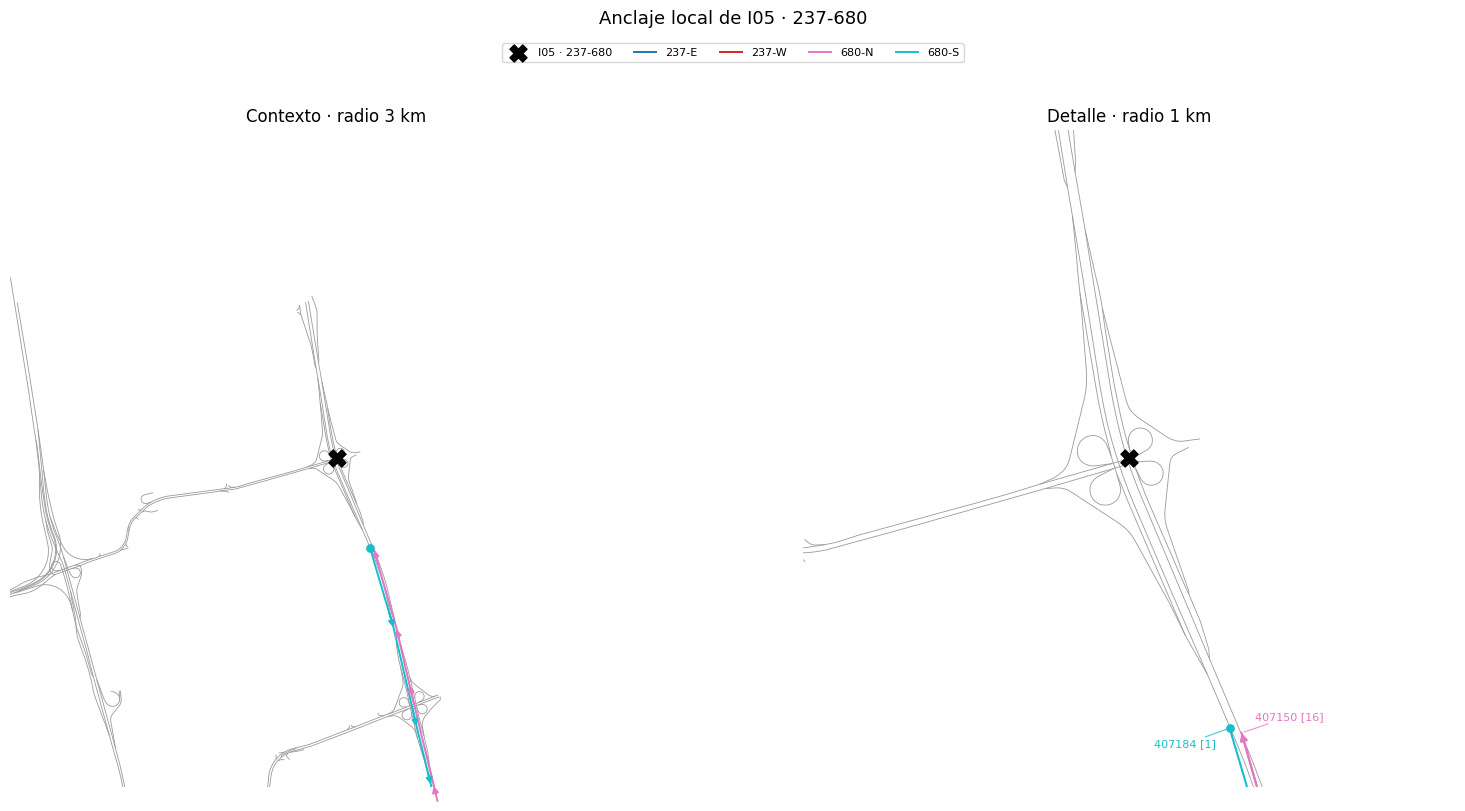

In [ ]:
inspect_macronode('I05')

**Anclaje seleccionado.** La revisión de `I05` muestra una cobertura claramente
asimétrica entre las autopistas asociadas con la zona de intercambio.

Los corredores de la autopista 680 presentan un patrón terminal coherente.
`680-N` alcanza la zona desde su último sensor, `407150 [16]`, situado
aproximadamente a 0.91 km del macronodo, mientras que `680-S` comienza en
`407184 [1]`, aproximadamente a 0.88 km.

En contraste, la cobertura disponible de la autopista 237 se encuentra varios
kilómetros alejada de la zona. El primer sensor de `237-W` se localiza
aproximadamente a 3.56 km y el último sensor de `237-E` a 4.55 km. Esta separación
no proporciona un anclaje local suficientemente representativo para incorporar
estos corredores al macronodo.

Por tanto, las conexiones dirigidas asociadas con `I05` quedan definidas
únicamente para la autopista 680:

- `680-N`: `407150 → I05`
- `680-S`: `I05 → 407184`

Aunque `I05` fue identificado mediante OSM como una zona de intercambio entre
las autopistas 237 y 680, en la red experimental funciona como un punto terminal
de conexión entre ambos sentidos de 680. Esto permite conservar infraestructura
útil para la conectividad del grafo sin forzar la incorporación de corredores
PEMS-BAY cuya cobertura se encuentra demasiado alejada de la zona.

#### I06 · 237–880

Se revisa la posición del macronodo respecto de los corredores dirigidos
asociados con las autopistas 237 y 880 para identificar cuáles admiten
anclajes funcionalmente razonables y determinar sus conexiones de entrada y
salida.

I06 · 237-880


,Freeway-Direction,Sensor,Sensor Order,distance_km
83,237-E,400567,4,4.077929
84,237-E,400104,5,3.437783
85,237-E,400296,6,2.027454
86,237-E,400873,7,1.806376
87,237-W,413845,1,0.840729
88,237-W,400158,2,1.804197
89,237-W,401014,3,2.025691
90,237-W,400449,4,3.435495
299,880-N,402288,15,0.934145
300,880-N,413026,16,0.696099


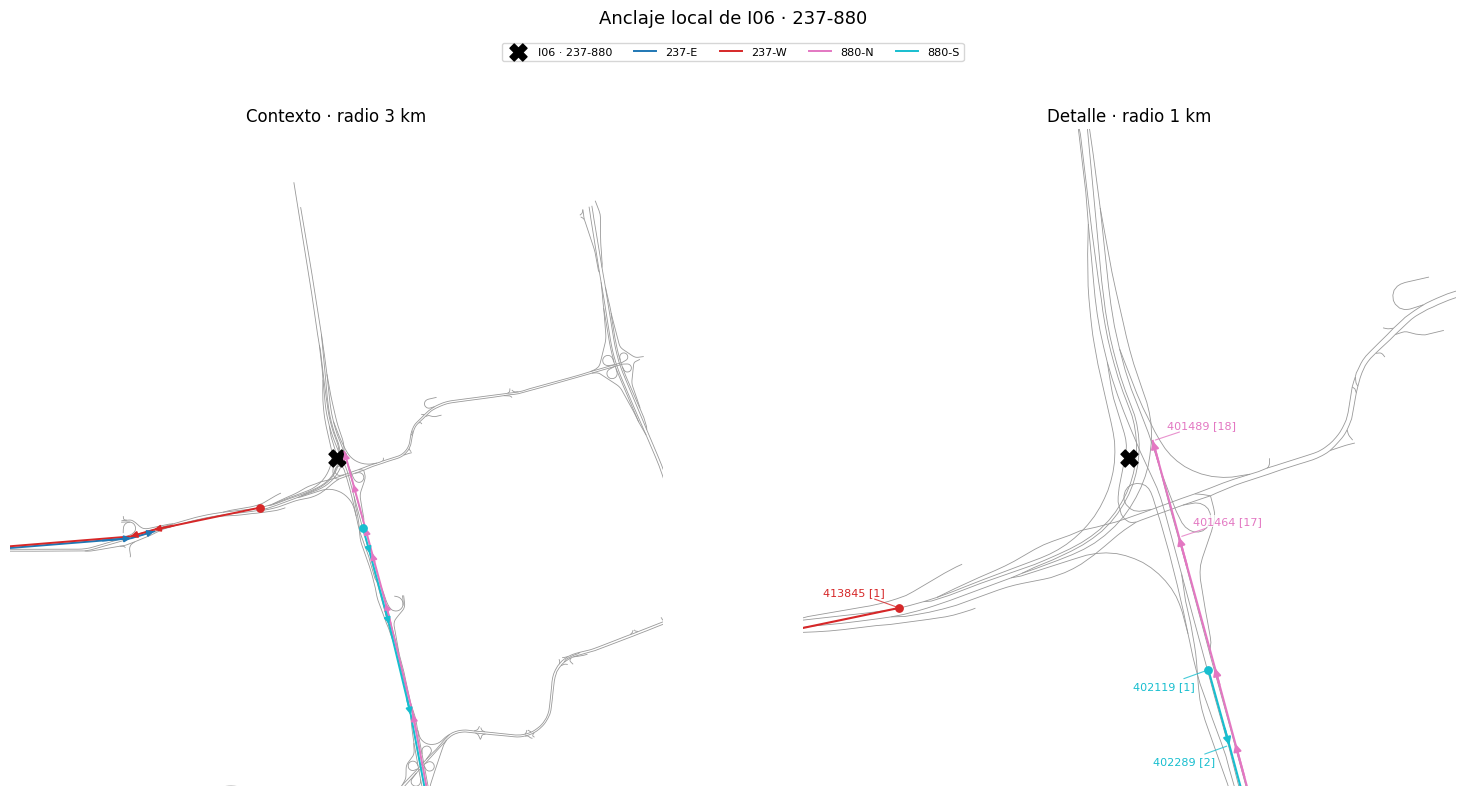

In [ ]:
inspect_macronode('I06')

**Anclaje seleccionado.** Los cuatro corredores asociados con `I06` presentan un
patrón terminal coherente alrededor de la zona de intercambio.

En la autopista 237, `237-E` alcanza la zona desde su último sensor,
`400873 [7]`, situado aproximadamente a 1.81 km del macronodo, mientras que
`237-W` comienza en `413845 [1]`, aproximadamente a 0.84 km. La disposición
terminal de ambos corredores y la continuidad vial observada en OSM permiten
asociarlos funcionalmente con el intercambio.

Para la autopista 880 se observa el mismo patrón. `880-N` termina en
`401489 [18]`, muy próximo al macronodo, mientras que `880-S` comienza en
`402119 [1]`.

Las conexiones dirigidas asociadas con `I06` quedan definidas como:

- `237-E`: `400873 → I06`
- `237-W`: `I06 → 413845`
- `880-N`: `401489 → I06`
- `880-S`: `I06 → 402119`

De esta forma, `I06` funciona como una zona de transferencia entre las
autopistas 237 y 880 a partir de los extremos instrumentados de sus cuatro
corredores.

#### I07 · 85–101

Se revisa la posición del macronodo respecto de los corredores dirigidos
asociados con las autopistas 85 y 101 para identificar cuáles admiten
anclajes funcionalmente razonables y determinar sus conexiones de entrada y
salida.

I07 · 85-101


,Freeway-Direction,Sensor,Sensor Order,distance_km
31,101-N,402372,32,1.660852
32,101-N,401534,33,0.804228
33,101-N,401948,34,0.214589
34,101-N,401507,35,0.613855
35,101-S,401926,1,0.491799
36,101-S,400149,2,0.444499
37,101-S,401937,3,0.335633
38,101-S,401936,4,0.821506
202,85-N,407325,32,2.885516
203,85-N,407323,33,1.502304


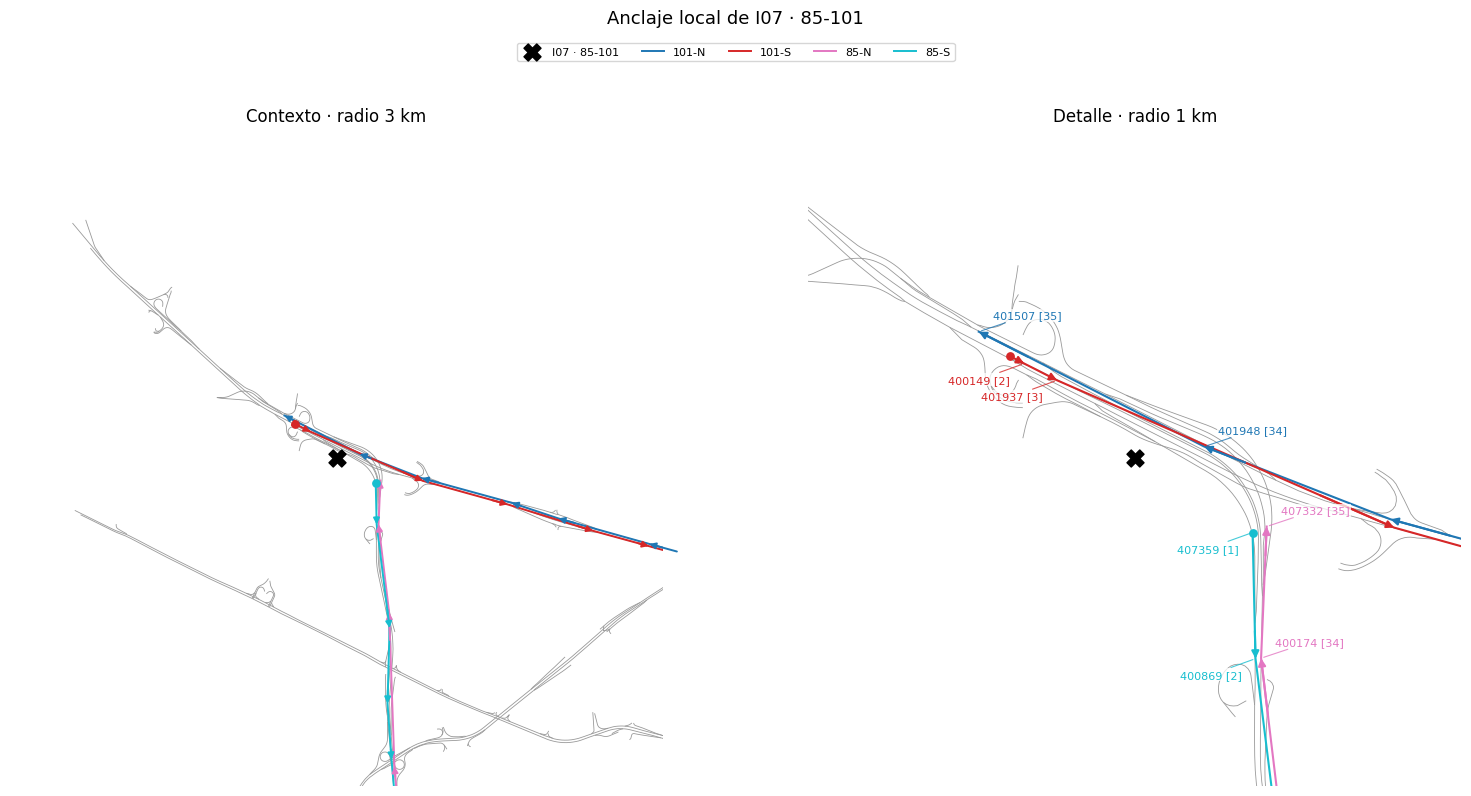

In [ ]:
inspect_macronode('I07')

**Anclaje seleccionado.** Los cuatro corredores asociados con `I07` permiten
establecer anclajes funcionalmente coherentes respecto de la posición fija del
macronodo.

Los corredores de la autopista 101 atraviesan la zona de intercambio. En
`101-N`, `I07` se inserta entre `401948 [34]` y `401507 [35]`, mientras que en
`101-S` queda entre `401937 [3]` y `401936 [4]`.

La autopista 85 presenta un patrón terminal: `85-N` alcanza la zona desde su
último sensor, `407332 [35]`, y `85-S` comienza en `407359 [1]`.

Las conexiones dirigidas asociadas con `I07` quedan definidas como:

- `101-N`: `401948 → I07 → 401507`
- `101-S`: `401937 → I07 → 401936`
- `85-N`: `407332 → I07`
- `85-S`: `I07 → 407359`

De esta forma, `I07` conecta funcionalmente los corredores de las autopistas 85
y 101 manteniendo una única posición representativa para toda la zona de
intercambio.

#### I08 · 85–237

Se revisa la posición del macronodo respecto de los corredores dirigidos
asociados con las autopistas 85 y 237 para identificar cuáles admiten
anclajes funcionalmente razonables y determinar sus conexiones de entrada y
salida.

I08 · 85-237


,Freeway-Direction,Sensor,Sensor Order,distance_km
80,237-E,404585,1,5.768141
81,237-E,400970,2,6.998365
82,237-E,400973,3,9.270047
83,237-E,400567,4,10.088060
94,237-W,400687,8,6.394353
95,237-W,404586,9,5.774836
96,237-W,400581,10,4.222588
97,237-W,401351,11,3.689356
199,85-N,407335,29,1.210475
200,85-N,407328,30,0.765317


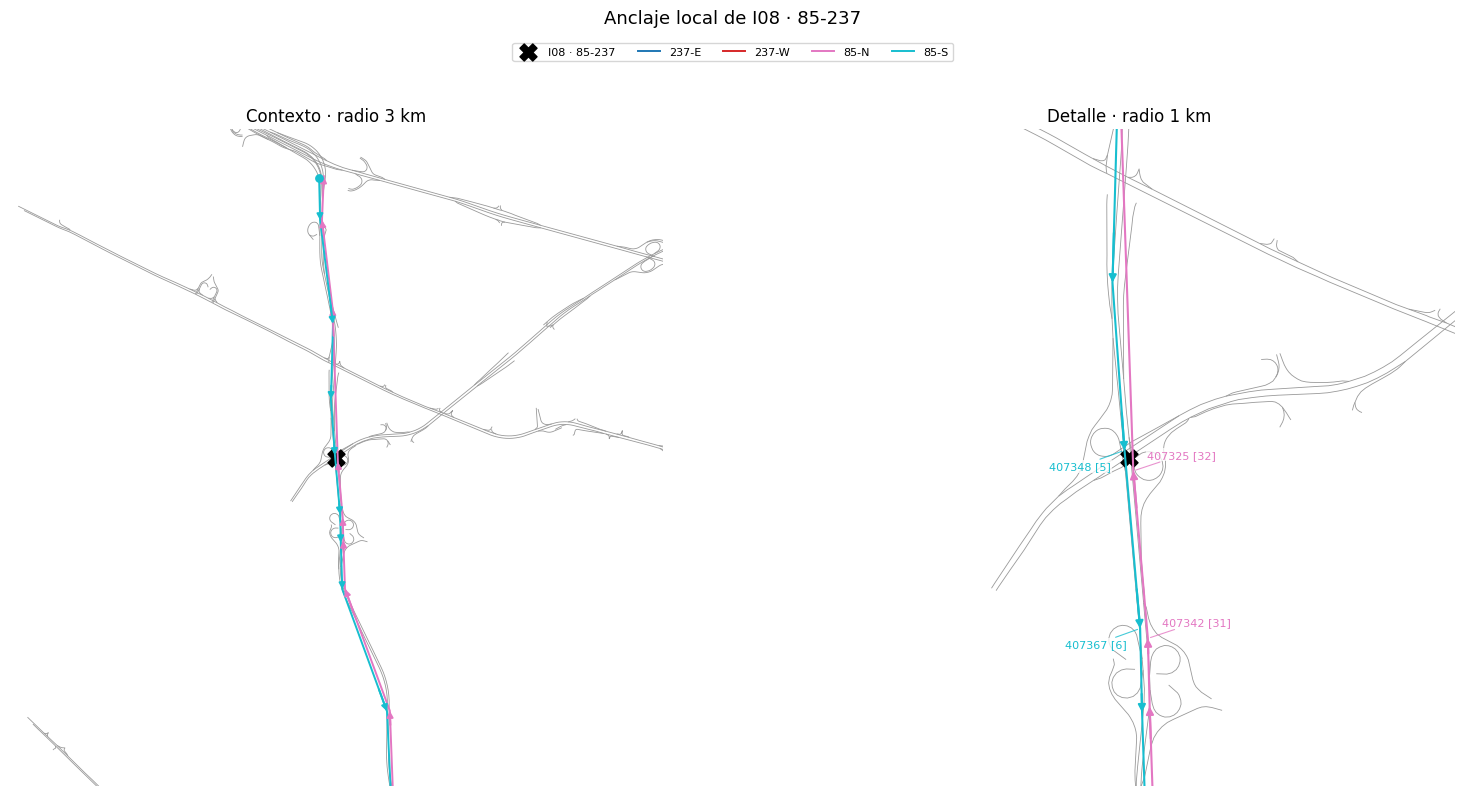

In [ ]:
inspect_macronode('I08')

**Anclaje seleccionado.** La revisión de `I08` muestra una cobertura claramente
asimétrica entre las autopistas asociadas con la zona de intercambio.

Los dos corredores de la autopista 85 atraviesan la zona y permiten definir
anclajes interiores. En `85-N`, la posición representativa del macronodo queda
entre `407325 [32]` y `407323 [33]`, mientras que en `85-S` queda entre
`407348 [5]` y `407367 [6]`.

En contraste, la cobertura PEMS-BAY de la autopista 237 se encuentra varios
kilómetros alejada. El último sensor de `237-W`, `401351 [11]`, se localiza
aproximadamente a 3.69 km del macronodo, mientras que el primer sensor de
`237-E`, `404585 [1]`, se encuentra aproximadamente a 5.77 km. Esta separación
no permite establecer un anclaje local suficientemente representativo para
incorporar dichos corredores.

Por tanto, las conexiones dirigidas asociadas con `I08` quedan definidas
únicamente para la autopista 85:

- `85-N`: `407325 → I08 → 407323`
- `85-S`: `407348 → I08 → 407367`

Aunque `I08` fue identificado mediante OSM como una zona de intercambio entre
las autopistas 85 y 237, en la red experimental funciona como un punto de
transferencia entre ambos sentidos de la autopista 85.

#### I09 · 85–280

Se revisa la posición del macronodo respecto de los corredores dirigidos
asociados con las autopistas 85 y 280 para identificar cuáles admiten
anclajes funcionalmente razonables y determinar sus conexiones de entrada y
salida.

I09 · 85-280


,Freeway-Direction,Sensor,Sensor Order,distance_km
116,280-N,400560,19,4.700052
117,280-N,400499,20,3.577187
118,280-N,400823,21,1.804152
119,280-N,401845,22,0.481780
120,280-S,401846,1,0.475599
121,280-S,404640,2,0.561588
122,280-S,400673,3,3.714054
123,280-S,400084,4,3.839382
190,85-N,404435,20,0.675751
191,85-N,407344,21,0.061857


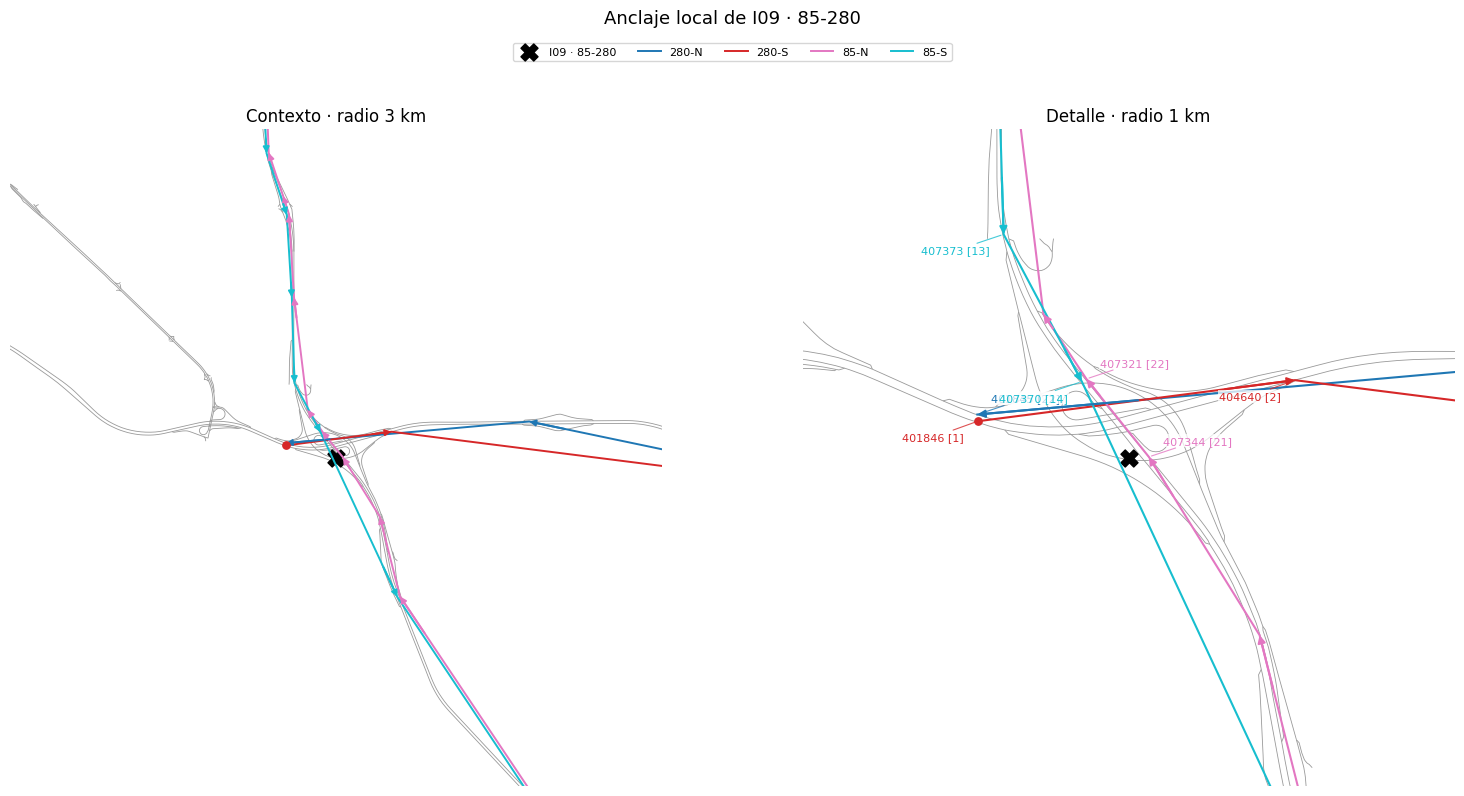

In [ ]:
inspect_macronode('I09')

**Anclaje seleccionado.** Los cuatro corredores asociados con `I09` atraviesan
la zona de intercambio y permiten definir anclajes interiores.

En la autopista 280, la posición representativa del macronodo queda entre
`400823 [21]` y `401845 [22]` en `280-N`, y entre `401846 [1]` y
`404640 [2]` en `280-S`.

Para la autopista 85, `I09` se localiza entre `407344 [21]` y `407321 [22]`
en `85-N`, mientras que en `85-S` queda entre `407370 [14]` y
`400209 [15]`.

Las conexiones dirigidas asociadas con `I09` quedan definidas como:

- `280-N`: `400823 → I09 → 401845`
- `280-S`: `401846 → I09 → 404640`
- `85-N`: `407344 → I09 → 407321`
- `85-S`: `407370 → I09 → 400209`

De esta forma, `I09` funciona como una zona de transferencia entre ambos
sentidos de las autopistas 85 y 280 mediante cuatro anclajes interiores.

#### I10 · 85–87

Se revisa la posición del macronodo respecto de los corredores dirigidos
asociados con las autopistas 85 y 87 para identificar cuáles admiten
anclajes funcionalmente razonables y determinar sus conexiones de entrada y
salida.

I10 · 85-87


,Freeway-Direction,Sensor,Sensor Order,distance_km
171,85-N,400268,1,0.221301
172,85-N,401555,2,0.241973
173,85-N,400052,3,1.574862
174,85-N,400461,4,1.892528
237,85-S,400085,32,1.510538
238,85-S,401495,33,0.273610
239,85-S,400637,34,0.315516
240,85-S,400519,35,0.536413
241,87-N,400280,1,0.486835
242,87-N,405613,2,0.567366


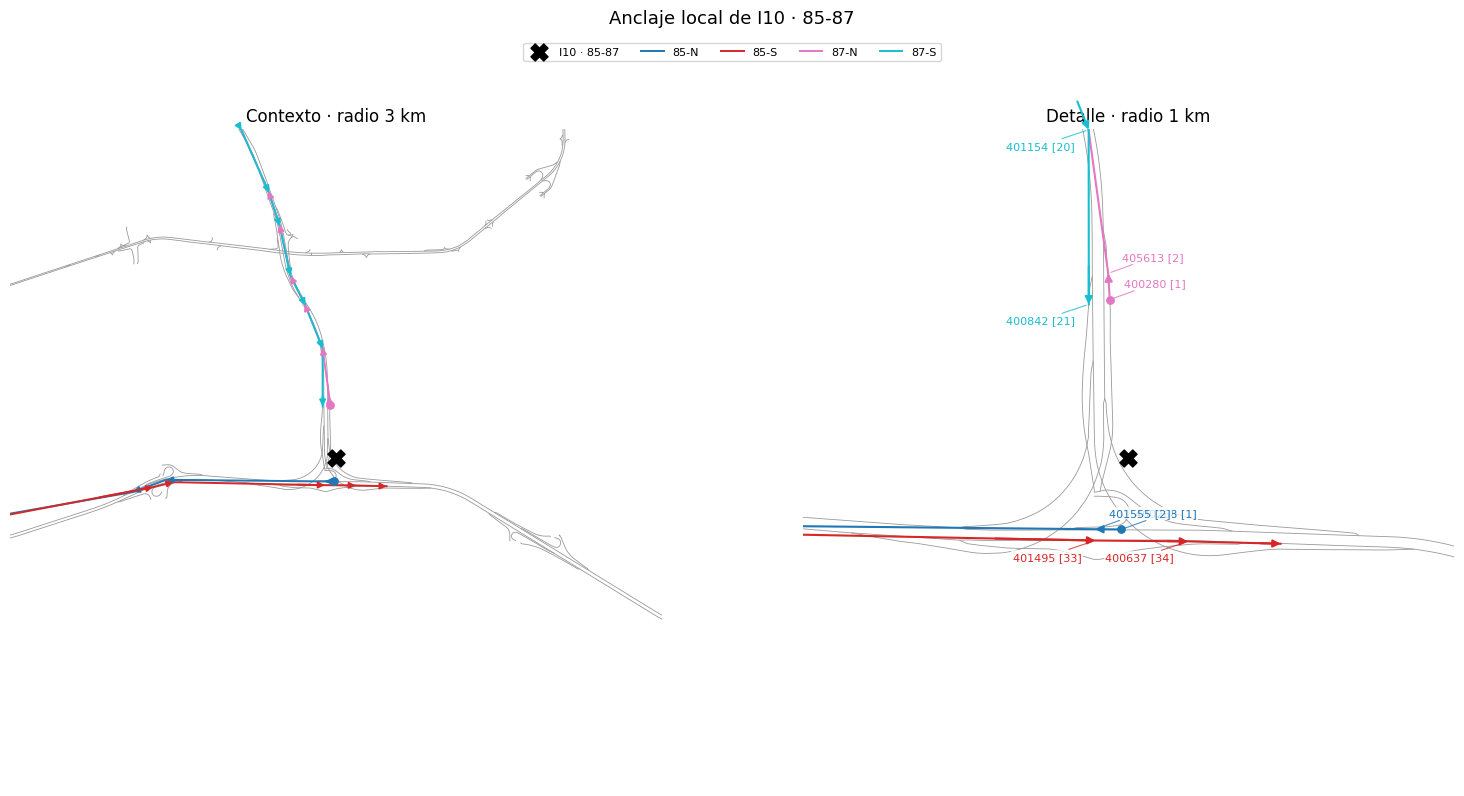

In [ ]:
inspect_macronode('I10')

**Anclaje seleccionado.** Los cuatro corredores asociados con `I10` permiten
establecer conexiones funcionales con la zona de intercambio, aunque la cobertura
no presenta el mismo patrón en ambos sentidos.

En la autopista 85, `85-N` comienza después de la posición representativa del
macronodo, por lo que `400268 [1]` funciona como su primer anclaje de salida.
En `85-S`, la cobertura atraviesa la zona y el macronodo queda entre
`401495 [33]` y `400637 [34]`.

La autopista 87 presenta un patrón terminal alrededor del intercambio. `87-S`
alcanza la zona desde su último sensor, `400842 [21]`, mientras que `87-N`
comienza en `400280 [1]`.

Las conexiones dirigidas asociadas con `I10` quedan definidas como:

- `85-N`: `I10 → 400268`
- `85-S`: `401495 → I10 → 400637`
- `87-N`: `I10 → 400280`
- `87-S`: `400842 → I10`

De esta forma, `I10` conecta funcionalmente los corredores de las autopistas 85
y 87 respetando la posición fija del macronodo y los límites de cobertura
observados en cada sentido.

#### I11 · 87–101

Se revisa la posición del macronodo respecto de los corredores dirigidos
asociados con las autopistas 87 y 101 para identificar cuáles admiten
anclajes funcionalmente razonables y determinar sus conexiones de entrada y
salida.

I11 · 87-101


,Freeway-Direction,Sensor,Sensor Order,distance_km
14,101-N,400911,15,0.913319
15,101-N,400760,16,0.101928
16,101-N,400964,17,0.798040
17,101-N,400227,18,1.055893
55,101-S,400895,21,2.626166
56,101-S,400586,22,0.956214
57,101-S,400172,23,0.699361
58,101-S,402365,24,2.268770
260,87-N,409524,20,3.691931
261,87-N,409525,21,1.900202


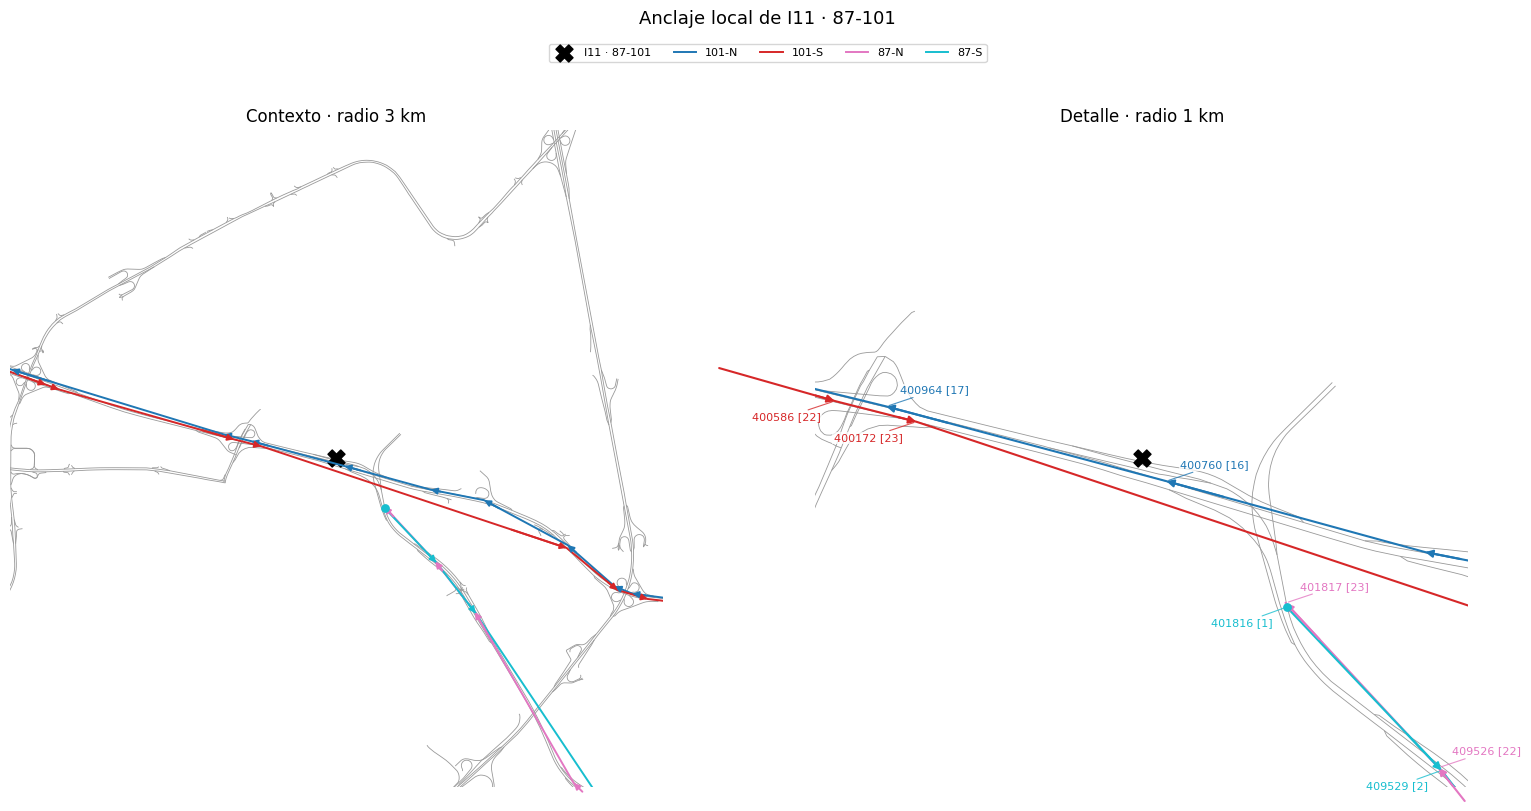

In [ ]:
inspect_macronode('I11')

**Anclaje seleccionado.** Los cuatro corredores asociados con `I11` permiten
establecer conexiones funcionales con la zona de intercambio.

Los corredores de la autopista 101 atraviesan la zona. En `101-N`, la posición
representativa del macronodo queda entre `400760 [16]` y `400964 [17]`,
mientras que en `101-S` queda entre `400172 [23]` y `402365 [24]`.

La autopista 87 presenta un patrón terminal alrededor del intercambio. `87-N`
alcanza la zona desde su último sensor, `401817 [23]`, mientras que `87-S`
comienza en `401816 [1]`.

Las conexiones dirigidas asociadas con `I11` quedan definidas como:

- `101-N`: `400760 → I11 → 400964`
- `101-S`: `400172 → I11 → 402365`
- `87-N`: `401817 → I11`
- `87-S`: `I11 → 401816`

De esta forma, `I11` conecta funcionalmente ambos sentidos de las autopistas
87 y 101 mediante una combinación de anclajes interiores y terminales.

#### I12 · 87–280

Se revisa la posición del macronodo respecto de los corredores dirigidos
asociados con las autopistas 87 y 280 para identificar cuáles admiten
anclajes funcionalmente razonables y determinar sus conexiones de entrada y
salida.

I12 · 87-280


,Freeway-Direction,Sensor,Sensor Order,distance_km
105,280-N,413878,8,0.345492
106,280-N,414284,9,0.386465
107,280-N,401942,10,0.509403
108,280-N,413877,11,0.688592
132,280-S,402067,13,0.691073
133,280-S,401943,14,0.509635
134,280-S,403412,15,0.494128
135,280-S,403409,16,0.150127
254,87-N,400258,14,1.226142
255,87-N,400916,15,0.372885


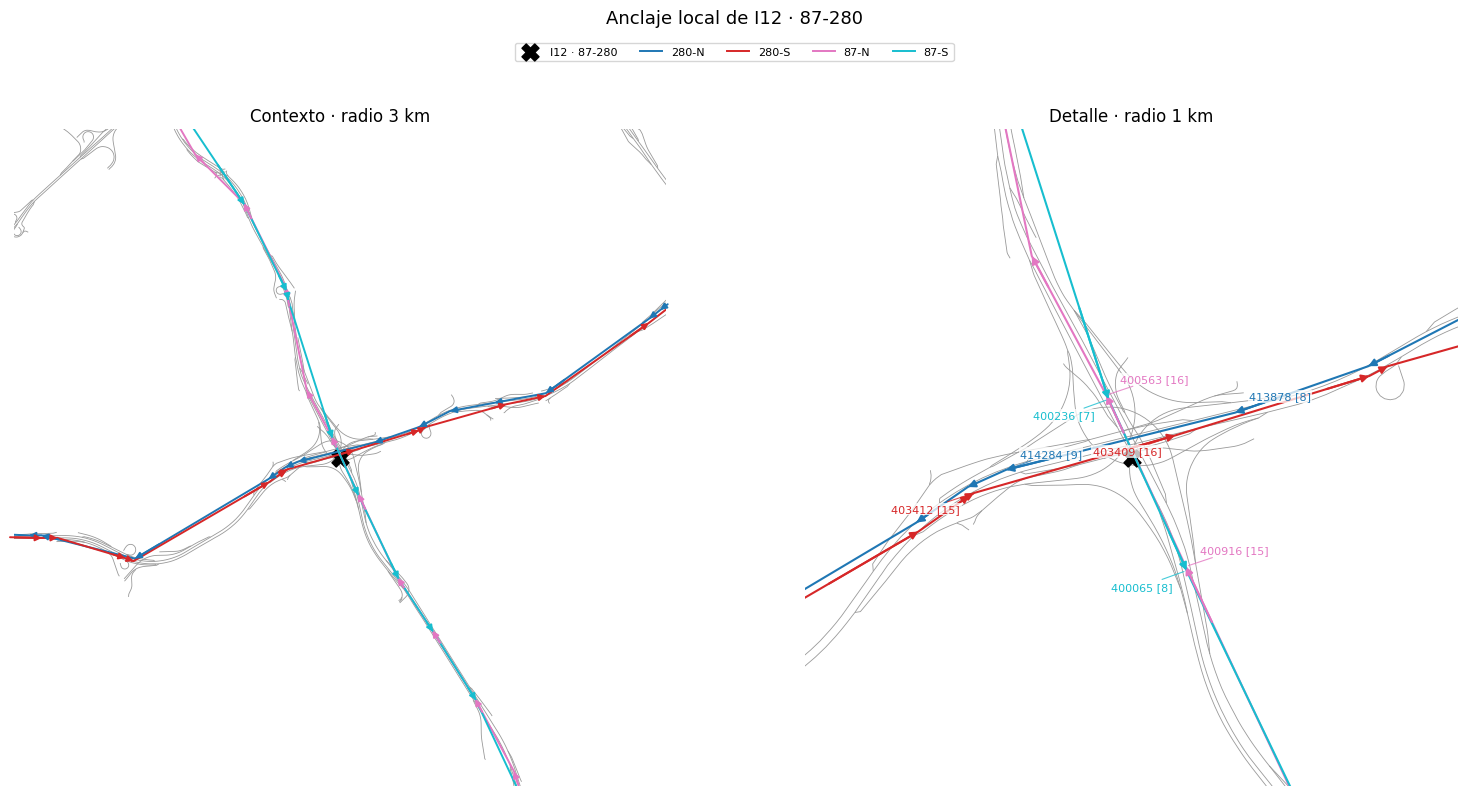

In [ ]:
inspect_macronode('I12')

**Anclaje seleccionado.** Los cuatro corredores asociados con `I12` atraviesan
la zona de intercambio y permiten definir anclajes interiores.

En la autopista 280, la posición representativa del macronodo queda entre
`413878 [8]` y `414284 [9]` en `280-N`, y entre `403412 [15]` y
`403409 [16]` en `280-S`.

Para la autopista 87, `I12` se localiza entre `400916 [15]` y `400563 [16]`
en `87-N`, mientras que en `87-S` queda entre `400236 [7]` y
`400065 [8]`.

Las conexiones dirigidas asociadas con `I12` quedan definidas como:

- `280-N`: `413878 → I12 → 414284`
- `280-S`: `403412 → I12 → 403409`
- `87-N`: `400916 → I12 → 400563`
- `87-S`: `400236 → I12 → 400065`

De esta forma, `I12` funciona como una zona de transferencia entre ambos
sentidos de las autopistas 87 y 280 mediante cuatro anclajes interiores.

### 8.3 Consolidación de las decisiones de anclaje

La inspección local de los 13 macronodos permite materializar las decisiones de
anclaje en una única tabla.

Para cada combinación macronodo–corredor se registra:

- `entry_sensor`: sensor desde el cual se ingresa al macronodo mediante una
  conexión `sensor → I`;
- `exit_sensor`: sensor hacia el cual se abandona el macronodo mediante una
  conexión `I → sensor`;
- `anchor_type`: relación del macronodo con la cobertura del corredor:
  `interior`, `before_start`, `after_end` o `inactive`.

En un anclaje interior existen tanto un sensor de entrada como uno de salida.
En los anclajes terminales sólo existe uno de ellos. El valor `inactive`
identifica corredores asociados con la zona mediante OSM que, después de la
revisión local, no se incorporan al macronodo.

Esta tabla constituye la especificación determinista utilizada posteriormente
para construir las aristas entre sensores y macronodos.

In [ ]:
# ------------------------------------------------------------
# 8.3 Consolidación de las decisiones de anclaje
# ------------------------------------------------------------

anchor_rows = [

    # I00 · 101-237
    ('I00', '101-N', 'interior',     '401997', '404522'),
    ('I00', '101-S', 'interior',     '404554', '400545'),
    ('I00', '237-W', 'after_end',    '401351', None),
    ('I00', '237-E', 'before_start', None,     '404585'),

    # I01 · 101-280-680
    ('I01', '101-N', 'interior',     '402361', '400400'),
    ('I01', '101-S', 'interior',     '401891', '401906'),
    ('I01', '280-N', 'before_start', None,     '401403'),
    ('I01', '280-S', 'after_end',    '401391', None),
    ('I01', '680-N', 'before_start', None,     '407172'),
    ('I01', '680-S', 'after_end',    '400665', None),

    # I02 · 101-880
    ('I02', '101-N', 'interior', '400001', '404753'),
    ('I02', '101-S', 'interior', '400394', '400922'),
    ('I02', '880-N', 'interior', '400045', '400122'),
    ('I02', '880-S', 'interior', '404759', '400479'),

    # I03 · 17-280-880
    ('I03', '17-N',  'after_end',    '404370', None),
    ('I03', '17-S',  'before_start', None,     '400100'),
    ('I03', '280-N', 'interior',     '407710', '401400'),
    ('I03', '280-S', 'interior',     '407711', '401163'),
    ('I03', '880-N', 'before_start', None,     '408907'),
    ('I03', '880-S', 'after_end',    '401611', None),

    # I04 · 17-85
    ('I04', '17-N', 'interior', '400649', '400715'),
    ('I04', '17-S', 'interior', '400073', '400832'),
    ('I04', '85-N', 'interior', '400822', '400464'),
    ('I04', '85-S', 'interior', '400792', '400934'),

    # I05 · 237-680
    ('I05', '237-E', 'inactive',  None,     None),
    ('I05', '237-W', 'inactive',  None,     None),
    ('I05', '680-N', 'after_end', '407150', None),
    ('I05', '680-S', 'before_start', None,  '407184'),

    # I06 · 237-880
    ('I06', '237-E', 'after_end',    '400873', None),
    ('I06', '237-W', 'before_start', None,     '413845'),
    ('I06', '880-N', 'after_end',    '401489', None),
    ('I06', '880-S', 'before_start', None,     '402119'),

    # I07 · 85-101
    ('I07', '101-N', 'interior',     '401948', '401507'),
    ('I07', '101-S', 'interior',     '401937', '401936'),
    ('I07', '85-N',  'after_end',    '407332', None),
    ('I07', '85-S',  'before_start', None,     '407359'),

    # I08 · 85-237
    ('I08', '85-N',  'interior', '407325', '407323'),
    ('I08', '85-S',  'interior', '407348', '407367'),
    ('I08', '237-E', 'inactive', None, None),
    ('I08', '237-W', 'inactive', None, None),

    # I09 · 85-280
    ('I09', '280-N', 'interior', '400823', '401845'),
    ('I09', '280-S', 'interior', '401846', '404640'),
    ('I09', '85-N',  'interior', '407344', '407321'),
    ('I09', '85-S',  'interior', '407370', '400209'),

    # I10 · 85-87
    ('I10', '85-N', 'before_start', None,     '400268'),
    ('I10', '85-S', 'interior',     '401495', '400637'),
    ('I10', '87-N', 'before_start', None,     '400280'),
    ('I10', '87-S', 'after_end',    '400842', None),

    # I11 · 87-101
    ('I11', '101-N', 'interior',     '400760', '400964'),
    ('I11', '101-S', 'interior',     '400172', '402365'),
    ('I11', '87-N',  'after_end',    '401817', None),
    ('I11', '87-S',  'before_start', None,     '401816'),

    # I12 · 87-280
    ('I12', '280-N', 'interior', '413878', '414284'),
    ('I12', '280-S', 'interior', '403412', '403409'),
    ('I12', '87-N',  'interior', '400916', '400563'),
    ('I12', '87-S',  'interior', '400236', '400065'),
]

anchor_decisions = pd.DataFrame(
    anchor_rows,
    columns=[
        'node_id',
        'corridor',
        'anchor_type',
        'entry_sensor',
        'exit_sensor'
    ]
)

assert len(anchor_decisions) == 56
assert anchor_decisions['node_id'].nunique() == 13

print('Decisiones macronodo-corredor:', len(anchor_decisions))
print(
    'Conexiones activas:',
    (anchor_decisions['anchor_type'] != 'inactive').sum()
)
print(
    'Corredores no conectados:',
    (anchor_decisions['anchor_type'] == 'inactive').sum()
)

display(anchor_decisions)

Decisiones macronodo-corredor: 56
Conexiones activas: 52
Corredores no conectados: 4


,node_id,corridor,anchor_type,entry_sensor,exit_sensor
0,I00,101-N,interior,401997,404522
1,I00,101-S,interior,404554,400545
2,I00,237-W,after_end,401351,None
3,I00,237-E,before_start,None,404585
4,I01,101-N,interior,402361,400400
5,I01,101-S,interior,401891,401906
6,I01,280-N,before_start,None,401403
7,I01,280-S,after_end,401391,None
8,I01,680-N,before_start,None,407172
9,I01,680-S,after_end,400665,None


In [ ]:
# ------------------------------------------------------------
# Validación de las decisiones de anclaje
# ------------------------------------------------------------

seq_check = seq_meta[
    ['Freeway-Direction', 'Sensor', 'Sensor Order']
].copy()

seq_check['Sensor'] = seq_check['Sensor'].astype(str)

issues = []

for _, row in anchor_decisions.iterrows():

    node_id = row['node_id']
    corridor = row['corridor']
    anchor_type = row['anchor_type']
    entry_sensor = row['entry_sensor']
    exit_sensor = row['exit_sensor']

    corridor_data = (
        seq_check[
            seq_check['Freeway-Direction'] == corridor
        ]
        .sort_values('Sensor Order')
    )

    max_order = int(corridor_data['Sensor Order'].max())

    # --------------------------------------------------------
    # Corredores inactivos
    # --------------------------------------------------------
    if anchor_type == 'inactive':

        if entry_sensor is not None or exit_sensor is not None:
            issues.append(
                f'{node_id} {corridor}: un corredor inactive '
                'no debe tener sensores de anclaje.'
            )

        continue

    # --------------------------------------------------------
    # Recuperar Sensor Order de los anclajes activos
    # --------------------------------------------------------
    entry_order = None
    exit_order = None

    if entry_sensor is not None:

        match = corridor_data[
            corridor_data['Sensor'] == str(entry_sensor)
        ]

        if len(match) != 1:
            issues.append(
                f'{node_id} {corridor}: entry_sensor '
                f'{entry_sensor} no pertenece al corredor.'
            )
        else:
            entry_order = int(match.iloc[0]['Sensor Order'])

    if exit_sensor is not None:

        match = corridor_data[
            corridor_data['Sensor'] == str(exit_sensor)
        ]

        if len(match) != 1:
            issues.append(
                f'{node_id} {corridor}: exit_sensor '
                f'{exit_sensor} no pertenece al corredor.'
            )
        else:
            exit_order = int(match.iloc[0]['Sensor Order'])

    # --------------------------------------------------------
    # Coherencia según el tipo de anclaje
    # --------------------------------------------------------
    if anchor_type == 'interior':

        if entry_order is None or exit_order is None:
            issues.append(
                f'{node_id} {corridor}: anclaje interior incompleto.'
            )

        elif exit_order != entry_order + 1:
            issues.append(
                f'{node_id} {corridor}: los sensores '
                f'{entry_order} y {exit_order} no son consecutivos.'
            )

    elif anchor_type == 'before_start':

        if entry_sensor is not None or exit_order != 1:
            issues.append(
                f'{node_id} {corridor}: before_start debe conectar '
                'el macronodo con el primer sensor.'
            )

    elif anchor_type == 'after_end':

        if exit_sensor is not None or entry_order != max_order:
            issues.append(
                f'{node_id} {corridor}: after_end debe conectar '
                'el último sensor con el macronodo.'
            )

    else:
        issues.append(
            f'{node_id} {corridor}: anchor_type no reconocido.'
        )

# Resultado de la validación.
assert not issues, '\n'.join(issues)

print('Validación de anclajes: OK')
print()
print(anchor_decisions['anchor_type'].value_counts())

Validación de anclajes: OK

anchor_type
interior        29
before_start    12
after_end       11
inactive         4
Name: count, dtype: int64


La validación confirma que todas las decisiones de anclaje son consistentes con la
secuencia dirigida de sensores de PEMS-BAY. Los anclajes interiores utilizan
sensores consecutivos y los anclajes terminales corresponden al primer o último
sensor del corredor, según el caso.

A partir de esta especificación se construyen las aristas dirigidas entre sensores
y macronodos que complementan la conectividad intracorredor definida previamente.

### 8.4 Construcción de las conexiones entre sensores y macronodos

Las decisiones de anclaje se transforman en aristas dirigidas entre los sensores
PEMS-BAY y los macronodos.

Para los anclajes interiores, la conexión directa original entre los dos sensores
consecutivos se sustituye por dos aristas que obligan a atravesar el macronodo:

$$
s_k \rightarrow s_{k+1}
\qquad\longrightarrow\qquad
s_k \rightarrow I \rightarrow s_{k+1}.
$$

En los anclajes terminales se añade únicamente la conexión correspondiente entre
el extremo instrumentado del corredor y el macronodo.

Los corredores clasificados como `inactive` no generan conexiones. En esta etapa
se construye únicamente la topología dirigida; las longitudes de las nuevas
aristas se incorporan posteriormente.

In [ ]:
# ------------------------------------------------------------
# 8.4 Construcción de conexiones sensor-macronodo
# ------------------------------------------------------------

macro_edge_rows = []
interior_replacements = []

for _, row in anchor_decisions.iterrows():

    if row['anchor_type'] == 'inactive':
        continue

    node_id = row['node_id']
    corridor = row['corridor']
    anchor_type = row['anchor_type']
    entry_sensor = row['entry_sensor']
    exit_sensor = row['exit_sensor']

    # Sensor -> macronodo
    if entry_sensor is not None:
        macro_edge_rows.append({
            'from': str(entry_sensor),
            'to': node_id,
            'corridor': corridor,
            'node_id': node_id,
            'anchor_type': anchor_type,
            'edge_type': 'sensor_to_interchange'
        })

    # Macronodo -> sensor
    if exit_sensor is not None:
        macro_edge_rows.append({
            'from': node_id,
            'to': str(exit_sensor),
            'corridor': corridor,
            'node_id': node_id,
            'anchor_type': anchor_type,
            'edge_type': 'interchange_to_sensor'
        })

    # En un anclaje interior debe eliminarse la arista directa
    # entre los dos sensores consecutivos.
    if anchor_type == 'interior':
        interior_replacements.append(
            (
                str(entry_sensor),
                str(exit_sensor),
                corridor
            )
        )

macro_edges = pd.DataFrame(macro_edge_rows)

# ------------------------------------------------------------
# Retirar las aristas intracorredor sustituidas por macronodos
# ------------------------------------------------------------

corridor_edges_for_graph = corridor_edges.copy()

corridor_edges_for_graph['from'] = (
    corridor_edges_for_graph['from'].astype(str)
)
corridor_edges_for_graph['to'] = (
    corridor_edges_for_graph['to'].astype(str)
)

replacement_set = set(interior_replacements)

replace_mask = corridor_edges_for_graph.apply(
    lambda row: (
        row['from'],
        row['to'],
        row['corridor']
    ) in replacement_set,
    axis=1
)

replaced_corridor_edges = corridor_edges_for_graph[
    replace_mask
].copy()

corridor_edges_for_graph = corridor_edges_for_graph[
    ~replace_mask
].copy().reset_index(drop=True)

# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

n_interior = int(
    (anchor_decisions['anchor_type'] == 'interior').sum()
)

assert len(interior_replacements) == n_interior
assert len(replaced_corridor_edges) == n_interior

assert len(macro_edges) == (
    2 * n_interior
    + (anchor_decisions['anchor_type'] == 'before_start').sum()
    + (anchor_decisions['anchor_type'] == 'after_end').sum()
)

print('Aristas intracorredor originales:', len(corridor_edges))
print('Aristas intracorredor sustituidas:', len(replaced_corridor_edges))
print('Aristas intracorredor conservadas:', len(corridor_edges_for_graph))
print('Nuevas aristas sensor-macronodo:', len(macro_edges))

display(macro_edges)

Aristas intracorredor originales: 309
Aristas intracorredor sustituidas: 29
Aristas intracorredor conservadas: 280
Nuevas aristas sensor-macronodo: 81


,from,to,corridor,node_id,anchor_type,edge_type
0,401997,I00,101-N,I00,interior,sensor_to_interchange
1,I00,404522,101-N,I00,interior,interchange_to_sensor
2,404554,I00,101-S,I00,interior,sensor_to_interchange
3,I00,400545,101-S,I00,interior,interchange_to_sensor
4,401351,I00,237-W,I00,after_end,sensor_to_interchange
...,...,...,...,...,...,...
76,I12,403409,280-S,I12,interior,interchange_to_sensor
77,400916,I12,87-N,I12,interior,sensor_to_interchange
78,I12,400563,87-N,I12,interior,interchange_to_sensor
79,400236,I12,87-S,I12,interior,sensor_to_interchange


La construcción sustituye 29 aristas intracorredor por conexiones que atraviesan
los macronodos y genera 81 nuevas aristas sensor–macronodo. Como resultado,
permanecen 280 de las 309 aristas intracorredor originales.

Esta operación conserva la dirección de los corredores y evita mantener conexiones
directas que permitan omitir un macronodo cuando éste se encuentra insertado entre
dos sensores consecutivos.

### 8.5 Ensamblaje de la red experimental

La red experimental se construye combinando los sensores PEMS-BAY y los macronodos
como vértices, y las aristas intracorredor conservadas con las conexiones
sensor–macronodo como aristas dirigidas.

En esta etapa el objetivo es obtener y validar exclusivamente la estructura
topológica de la red. Las longitudes y los tiempos de recorrido de las conexiones
incorporadas mediante macronodos se determinarán posteriormente.

In [ ]:
# ------------------------------------------------------------
# 8.5 Ensamblaje de la topología de la red experimental
# ------------------------------------------------------------

corridor_topology_edges = (
    corridor_edges_for_graph[
        ['from', 'to', 'corridor']
    ]
    .copy()
)

corridor_topology_edges['edge_type'] = 'corridor'
corridor_topology_edges['node_id'] = None
corridor_topology_edges['anchor_type'] = None

macro_topology_edges = macro_edges[
    [
        'from',
        'to',
        'corridor',
        'edge_type',
        'node_id',
        'anchor_type'
    ]
].copy()

network_edges = pd.concat(
    [
        corridor_topology_edges,
        macro_topology_edges
    ],
    ignore_index=True
)

assert len(network_edges) == 361
assert not (network_edges['from'] == network_edges['to']).any()

print('Aristas dirigidas de la red:', len(network_edges))

display(network_edges)

Aristas dirigidas de la red: 361


,from,to,corridor,edge_type,node_id,anchor_type
0,402359,401908,101-N,corridor,None,None
1,401908,400804,101-N,corridor,None,None
2,400804,402361,101-N,corridor,None,None
3,400400,401890,101-N,corridor,None,None
4,401890,400996,101-N,corridor,None,None
...,...,...,...,...,...,...
356,I12,403409,280-S,interchange_to_sensor,I12,interior
357,400916,I12,87-N,sensor_to_interchange,I12,interior
358,I12,400563,87-N,interchange_to_sensor,I12,interior
359,400236,I12,87-S,sensor_to_interchange,I12,interior


In [ ]:
# ------------------------------------------------------------
# Construcción de los nodos de la red experimental
# ------------------------------------------------------------

sensor_nodes = (
    seq_meta[
        [
            'Sensor',
            'Freeway-Direction',
            'Latitude',
            'Longitude'
        ]
    ]
    .copy()
    .rename(
        columns={
            'Sensor': 'node_id',
            'Freeway-Direction': 'corridor',
            'Latitude': 'latitude',
            'Longitude': 'longitude'
        }
    )
)

sensor_nodes['node_id'] = sensor_nodes['node_id'].astype(str)
sensor_nodes['node_type'] = 'sensor'
sensor_nodes['osm_freeways'] = None

interchange_nodes = (
    macronodes[
        [
            'node_id',
            'latitude',
            'longitude',
            'node_type',
            'osm_freeways'
        ]
    ]
    .copy()
)

interchange_nodes['corridor'] = None

network_nodes = pd.concat(
    [
        sensor_nodes[
            [
                'node_id',
                'node_type',
                'corridor',
                'osm_freeways',
                'latitude',
                'longitude'
            ]
        ],
        interchange_nodes[
            [
                'node_id',
                'node_type',
                'corridor',
                'osm_freeways',
                'latitude',
                'longitude'
            ]
        ]
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

assert len(sensor_nodes) == 325
assert len(interchange_nodes) == 13
assert len(network_nodes) == 338
assert network_nodes['node_id'].is_unique

edge_nodes = set(network_edges['from']) | set(network_edges['to'])
defined_nodes = set(network_nodes['node_id'])

assert edge_nodes <= defined_nodes

print('Sensores PEMS-BAY:', len(sensor_nodes))
print('Macronodos:', len(interchange_nodes))
print('Nodos totales:', len(network_nodes))
print(
    'Extremos de aristas sin nodo definido:',
    len(edge_nodes - defined_nodes)
)

display(network_nodes)

Sensores PEMS-BAY: 325
Macronodos: 13
Nodos totales: 338
Extremos de aristas sin nodo definido: 0


,node_id,node_type,corridor,osm_freeways,latitude,longitude
0,402359,sensor,101-N,None,37.329728,-121.842102
1,401908,sensor,101-N,None,37.335284,-121.847662
2,400804,sensor,101-N,None,37.336089,-121.848437
3,402361,sensor,101-N,None,37.336549,-121.848881
4,400400,sensor,101-N,None,37.342410,-121.854543
...,...,...,...,...,...,...
333,I08,interchange,None,"(85, 237)",37.384076,-122.068261
334,I09,interchange,None,"(85, 280)",37.331484,-122.055386
335,I10,interchange,None,"(85, 87)",37.257632,-121.857836
336,I11,interchange,None,"(87, 101)",37.375251,-121.931901


In [ ]:
# ------------------------------------------------------------
# Grafo dirigido experimental
# ------------------------------------------------------------

G_exp = nx.DiGraph()

for _, row in network_nodes.iterrows():

    attrs = row.drop('node_id').to_dict()

    G_exp.add_node(
        row['node_id'],
        **attrs
    )

for _, row in network_edges.iterrows():

    attrs = row.drop(['from', 'to']).to_dict()

    G_exp.add_edge(
        row['from'],
        row['to'],
        **attrs
    )

assert G_exp.number_of_nodes() == 338
assert G_exp.number_of_edges() == 361

print('Nodos del grafo:', G_exp.number_of_nodes())
print('Aristas del grafo:', G_exp.number_of_edges())
print('Grafo dirigido:', G_exp.is_directed())

Nodos del grafo: 338
Aristas del grafo: 361
Grafo dirigido: True


## 9. Validación topológica de la red experimental

Una vez ensamblada la red, se revisa su conectividad antes de incorporar
longitudes o tiempos de recorrido.

La validación considera tanto la conectividad débil, que permite detectar
fragmentos físicamente aislados, como la conectividad fuerte, que permite
evaluar hasta qué punto la dirección de los corredores y las conexiones mediante
macronodos permiten desplazamientos en ambos sentidos dentro de la red.

También se identifican nodos sin entradas o sin salidas. Estos casos no se
interpretan automáticamente como errores, ya que pueden corresponder a límites
de la cobertura PEMS-BAY.

### 9.1 Conectividad global del grafo

Se evalúa primero la conectividad global de la red experimental.

La conectividad débil permite comprobar si todos los nodos forman parte de una
misma estructura cuando se ignora temporalmente la dirección de las aristas. La
conectividad fuerte, en cambio, permite identificar qué proporción de la red admite
trayectorias dirigidas de ida y vuelta entre sus nodos.

También se contabilizan los nodos con grado de entrada o salida igual a cero, ya
que estos casos pueden revelar extremos de cobertura que no participan plenamente
en la conectividad dirigida de la red.

In [ ]:
# ------------------------------------------------------------
# 9.1 Conectividad global del grafo
# ------------------------------------------------------------

weak_components = list(nx.weakly_connected_components(G_exp))
strong_components = list(nx.strongly_connected_components(G_exp))

zero_in = [
    node
    for node, degree in G_exp.in_degree()
    if degree == 0
]

zero_out = [
    node
    for node, degree in G_exp.out_degree()
    if degree == 0
]

print('Componentes débilmente conexas:', len(weak_components))
print(
    'Tamaño de la mayor componente débil:',
    max(map(len, weak_components))
)

print()
print('Componentes fuertemente conexas:', len(strong_components))
print(
    'Tamaño de la mayor componente fuerte:',
    max(map(len, strong_components))
)

print()
print('Nodos con grado de entrada 0:', len(zero_in))
print('Nodos con grado de salida 0:', len(zero_out))

Componentes débilmente conexas: 1
Tamaño de la mayor componente débil: 338

Componentes fuertemente conexas: 17
Tamaño de la mayor componente fuerte: 322

Nodos con grado de entrada 0: 4
Nodos con grado de salida 0: 5


La red completa forma una única componente débil que contiene los 338 nodos, por
lo que no existen fragmentos aislados.

En términos dirigidos se identifican 17 componentes fuertemente conexas. La
principal contiene 322 nodos, mientras que los 16 restantes pertenecen a
componentes individuales. También se observan 4 nodos sin aristas de entrada y
5 sin aristas de salida.

Estos resultados sugieren que la falta de conectividad fuerte global se concentra
en un número reducido de nodos terminales, por lo que se revisa su ubicación
dentro de los corredores antes de modificar la red.

### 9.2 Revisión de los nodos fuera de la componente fuerte principal

Para determinar si las componentes fuertes adicionales corresponden a problemas
de construcción o a límites naturales de la cobertura instrumentada, se examinan
los nodos que quedan fuera de la mayor componente fuertemente conexa.

Para cada uno se revisan su corredor, `Sensor Order` y grados de entrada y salida.
Esto permite establecer si se trata de fragmentos internos de la red o de
extensiones terminales situadas antes del primer intercambio útil o después del
último.

In [ ]:
# ------------------------------------------------------------
# 9.2 Nodos fuera de la componente fuertemente conexa principal
# ------------------------------------------------------------

main_scc = max(
    strong_components,
    key=len
)

outside_main_scc = set(G_exp.nodes) - set(main_scc)

outside_nodes = network_nodes[
    network_nodes['node_id'].isin(outside_main_scc)
].copy()

# Incorporar Sensor Order para interpretar la posición
# de los sensores dentro de sus corredores.
sensor_order = seq_meta[
    ['Sensor', 'Sensor Order']
].copy()

sensor_order['Sensor'] = sensor_order['Sensor'].astype(str)

sensor_order = sensor_order.rename(
    columns={'Sensor': 'node_id'}
)

outside_nodes = outside_nodes.merge(
    sensor_order,
    on='node_id',
    how='left'
)

outside_nodes['in_degree'] = (
    outside_nodes['node_id']
    .map(dict(G_exp.in_degree()))
)

outside_nodes['out_degree'] = (
    outside_nodes['node_id']
    .map(dict(G_exp.out_degree()))
)

outside_nodes = outside_nodes.sort_values(
    ['corridor', 'Sensor Order'],
    na_position='last'
).reset_index(drop=True)

small_scc_sizes = sorted(
    [
        len(component)
        for component in strong_components
        if component != main_scc
    ],
    reverse=True
)

print('Nodos fuera de la componente fuerte principal:',
      len(outside_nodes))
print('Tamaños de las demás componentes fuertes:',
      small_scc_sizes)

display(
    outside_nodes[
        [
            'node_id',
            'node_type',
            'corridor',
            'Sensor Order',
            'in_degree',
            'out_degree'
        ]
    ]
)

Nodos fuera de la componente fuerte principal: 16
Tamaños de las demás componentes fuertes: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


,node_id,node_type,corridor,Sensor Order,in_degree,out_degree
0,402359,sensor,101-N,1,0,1
1,401908,sensor,101-N,2,1,1
2,400804,sensor,101-N,3,1,1
3,402361,sensor,101-N,4,1,1
4,401507,sensor,101-N,35,1,0
5,401926,sensor,101-S,1,0,1
6,400149,sensor,101-S,2,1,1
7,401937,sensor,101-S,3,1,1
8,401906,sensor,101-S,32,1,1
9,402360,sensor,101-S,33,1,0


Los 16 nodos fuera de la componente fuerte principal corresponden exclusivamente
a sensores ubicados en extremos de corredores. No se identifican macronodos ni
fragmentos internos desconectados.

La estructura observada indica que estos nodos representan prolongaciones de la
cobertura PEMS-BAY que quedan fuera del conjunto de trayectorias dirigidas con
conectividad de ida y vuelta. Por ello, pueden conservarse como información de
tráfico, pero no es necesario incluirlos en el núcleo destinado al enrutamiento.

Esta evidencia permite delimitar el núcleo de la red a partir de la mayor
componente fuertemente conexa, en lugar de aplicar una regla de poda basada
únicamente en grados o distancias.

### 9.3 Delimitación del núcleo de enrutamiento

La red completa es débilmente conexa, pero 16 sensores quedan fuera de la
componente fuertemente conexa principal. La inspección de estos nodos muestra
que corresponden exclusivamente a tramos terminales situados antes del primer
macronodo útil o después del último macronodo de determinados corredores.

Estos sensores permanecen disponibles en PEMS-BAY y pueden conservarse como
información de tráfico, pero no forman parte del núcleo utilizado para
enrutamiento, ya que desde ellos no existe conectividad dirigida de ida y vuelta
con el resto de la red.

Por ello, se define el **núcleo de enrutamiento** como la mayor componente
fuertemente conexa del grafo experimental. Esta delimitación conserva todos los
macronodos y elimina únicamente los segmentos terminales que no participan en
trayectorias dirigidas entre cualquier par de nodos del núcleo.

In [ ]:
# ------------------------------------------------------------
# 9.3 Núcleo fuertemente conexo de enrutamiento
# ------------------------------------------------------------

core_nodes = set(main_scc)

G_core = G_exp.subgraph(core_nodes).copy()

network_nodes_core = (
    network_nodes[
        network_nodes['node_id'].isin(core_nodes)
    ]
    .copy()
    .reset_index(drop=True)
)

network_edges_core = (
    network_edges[
        network_edges['from'].isin(core_nodes)
        & network_edges['to'].isin(core_nodes)
    ]
    .copy()
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

assert G_core.number_of_nodes() == 322
assert nx.is_strongly_connected(G_core)

assert (
    network_nodes_core['node_type']
    .value_counts()
    .get('interchange', 0)
    == 13
)

print('Nodos del núcleo:', G_core.number_of_nodes())
print('Sensores en el núcleo:',
      (network_nodes_core['node_type'] == 'sensor').sum())
print('Macronodos en el núcleo:',
      (network_nodes_core['node_type'] == 'interchange').sum())
print('Aristas del núcleo:', G_core.number_of_edges())
print('Fuertemente conexo:', nx.is_strongly_connected(G_core))

Nodos del núcleo: 322
Sensores en el núcleo: 309
Macronodos en el núcleo: 13
Aristas del núcleo: 345
Fuertemente conexo: True


La delimitación produce un núcleo de **322 nodos**, integrado por **309 sensores
PEMS-BAY y los 13 macronodos**, y conserva **345 aristas dirigidas**.

El grafo resultante es fuertemente conexo: desde cualquier nodo del núcleo existe
al menos una trayectoria dirigida hacia cualquier otro nodo. Asimismo, se
conservan todos los macronodos definidos durante la etapa de anclaje.

Los 16 sensores retirados del grafo de enrutamiento no se eliminan del conjunto
de datos PEMS-BAY. Sus series temporales permanecen disponibles para análisis
posteriores; únicamente quedan fuera de la estructura utilizada para construir
trayectorias y matrices de tiempos de recorrido.

## 10. Asignación de longitudes a las aristas

La topología del núcleo de enrutamiento se complementa con una longitud asociada
a cada arista.

Para las aristas entre sensores consecutivos se conserva la aproximación utilizada
desde la construcción de los corredores, basada en la diferencia de `Postmile`.

Las conexiones con macronodos requieren un tratamiento distinto, ya que el
macronodo representa una zona funcional de intercambio y no un punto vial exacto:

- **Anclajes interiores.** La distancia original entre los dos sensores
  consecutivos se conserva, pero se divide entre las dos nuevas aristas
  `sensor → I` e `I → sensor`. La proporción se determina a partir de la
  proximidad geográfica del macronodo a cada extremo. De esta forma,

$$
d(s_k,I)+d(I,s_{k+1})=d(s_k,s_{k+1}).
$$

- **Anclajes terminales.** Al no existir una arista intracorredor que pueda
  dividirse, la longitud entre el sensor terminal y el macronodo se aproxima
  mediante distancia geodésica.

No se utiliza una ruta OSM exacta para estas conexiones. Debido al carácter
abstracto de los macronodos, ajustarlos a nodos o rampas específicas de OSM
introduciría una precisión física que la representación experimental no pretende
tener y que además dependería de la versión actual de la red vial.

In [ ]:
# ------------------------------------------------------------
# 10.1 Longitudes de las aristas de la red experimental
# ------------------------------------------------------------

# Coordenadas de sensores y macronodos.
sensor_coords = seq_meta[
    ['Sensor', 'Latitude', 'Longitude']
].copy()

sensor_coords['node_id'] = sensor_coords['Sensor'].astype(str)

sensor_coords = sensor_coords[
    ['node_id', 'Latitude', 'Longitude']
]

macro_coords = (
    macronodes[
        ['node_id', 'latitude', 'longitude']
    ]
    .rename(
        columns={
            'latitude': 'Latitude',
            'longitude': 'Longitude'
        }
    )
    .copy()
)

node_coords = pd.concat(
    [sensor_coords, macro_coords],
    ignore_index=True
).set_index('node_id')


def geometric_distance_km(node_a, node_b):
    """Distancia geodésica entre dos nodos de la red."""
    a = node_coords.loc[str(node_a)]
    b = node_coords.loc[str(node_b)]

    return haversine_m(
        float(a['Latitude']),
        float(a['Longitude']),
        float(b['Latitude']),
        float(b['Longitude'])
    ) / 1000


# ------------------------------------------------------------
# Distancias de las aristas intracorredor conservadas
# ------------------------------------------------------------

corridor_distance_rows = (
    corridor_edges_for_graph[
        ['from', 'to', 'corridor', 'distance_km']
    ]
    .copy()
)

corridor_distance_rows['from'] = (
    corridor_distance_rows['from'].astype(str)
)
corridor_distance_rows['to'] = (
    corridor_distance_rows['to'].astype(str)
)

corridor_distance_rows['distance_method'] = (
    'postmile_difference'
)


# ------------------------------------------------------------
# Distancias de las conexiones con macronodos
# ------------------------------------------------------------

base_corridor_edges = corridor_edges.copy()

base_corridor_edges['from'] = (
    base_corridor_edges['from'].astype(str)
)
base_corridor_edges['to'] = (
    base_corridor_edges['to'].astype(str)
)

macro_distance_rows = []

for _, row in anchor_decisions.iterrows():

    if row['anchor_type'] == 'inactive':
        continue

    node_id = row['node_id']
    corridor = row['corridor']
    anchor_type = row['anchor_type']

    entry_sensor = row['entry_sensor']
    exit_sensor = row['exit_sensor']

    # --------------------------------------------------------
    # Anclaje interior:
    # dividir la distancia original del segmento sustituido.
    # --------------------------------------------------------
    if anchor_type == 'interior':

        entry_sensor = str(entry_sensor)
        exit_sensor = str(exit_sensor)

        original_edge = base_corridor_edges[
            (base_corridor_edges['from'] == entry_sensor)
            & (base_corridor_edges['to'] == exit_sensor)
            & (base_corridor_edges['corridor'] == corridor)
        ]

        assert len(original_edge) == 1

        original_distance = float(
            original_edge.iloc[0]['distance_km']
        )

        d_entry_geo = geometric_distance_km(
            entry_sensor,
            node_id
        )

        d_exit_geo = geometric_distance_km(
            node_id,
            exit_sensor
        )

        geo_total = d_entry_geo + d_exit_geo

        assert geo_total > 0

        entry_share = d_entry_geo / geo_total

        entry_distance = (
            original_distance * entry_share
        )

        exit_distance = (
            original_distance - entry_distance
        )

        macro_distance_rows.extend([
            {
                'from': entry_sensor,
                'to': node_id,
                'corridor': corridor,
                'distance_km': entry_distance,
                'distance_method':
                    'postmile_split_geometric_ratio'
            },
            {
                'from': node_id,
                'to': exit_sensor,
                'corridor': corridor,
                'distance_km': exit_distance,
                'distance_method':
                    'postmile_split_geometric_ratio'
            }
        ])

    # --------------------------------------------------------
    # Macronodo antes del inicio de cobertura.
    # --------------------------------------------------------
    elif anchor_type == 'before_start':

        exit_sensor = str(exit_sensor)

        macro_distance_rows.append({
            'from': node_id,
            'to': exit_sensor,
            'corridor': corridor,
            'distance_km': geometric_distance_km(
                node_id,
                exit_sensor
            ),
            'distance_method': 'geodesic_terminal'
        })

    # --------------------------------------------------------
    # Macronodo después del final de cobertura.
    # --------------------------------------------------------
    elif anchor_type == 'after_end':

        entry_sensor = str(entry_sensor)

        macro_distance_rows.append({
            'from': entry_sensor,
            'to': node_id,
            'corridor': corridor,
            'distance_km': geometric_distance_km(
                entry_sensor,
                node_id
            ),
            'distance_method': 'geodesic_terminal'
        })


macro_distance_rows = pd.DataFrame(macro_distance_rows)


# ------------------------------------------------------------
# Tabla completa de longitudes
# ------------------------------------------------------------

edge_distances = pd.concat(
    [
        corridor_distance_rows,
        macro_distance_rows
    ],
    ignore_index=True
)

assert len(edge_distances) == 361
assert not edge_distances[
    ['from', 'to', 'corridor']
].duplicated().any()

network_edges_distance = network_edges.merge(
    edge_distances,
    on=['from', 'to', 'corridor'],
    how='left',
    validate='one_to_one'
)

assert network_edges_distance['distance_km'].notna().all()
assert (network_edges_distance['distance_km'] > 0).all()

print('Aristas con longitud asignada:',
      len(network_edges_distance))

print()
print(
    network_edges_distance[
        'distance_method'
    ].value_counts()
)

display(network_edges_distance)

Aristas con longitud asignada: 361

distance_method
postmile_difference               280
postmile_split_geometric_ratio     58
geodesic_terminal                  23
Name: count, dtype: int64


,from,to,corridor,edge_type,node_id,anchor_type,distance_km,distance_method
0,402359,401908,101-N,corridor,None,None,0.788579,postmile_difference
1,401908,400804,101-N,corridor,None,None,0.112654,postmile_difference
2,400804,402361,101-N,corridor,None,None,0.064374,postmile_difference
3,400400,401890,101-N,corridor,None,None,0.144841,postmile_difference
4,401890,400996,101-N,corridor,None,None,1.029980,postmile_difference
...,...,...,...,...,...,...,...,...
356,I12,403409,280-S,interchange_to_sensor,I12,interior,0.150007,postmile_split_geometric_ratio
357,400916,I12,87-N,sensor_to_interchange,I12,interior,0.373179,postmile_split_geometric_ratio
358,I12,400563,87-N,interchange_to_sensor,I12,interior,0.206185,postmile_split_geometric_ratio
359,400236,I12,87-S,sensor_to_interchange,I12,interior,0.192447,postmile_split_geometric_ratio


La asignación de longitudes cubre las 361 aristas de la red experimental. De ellas,
280 conservan directamente la distancia derivada de `Postmile`, mientras que 58
corresponden a la división de 29 segmentos intracorredor sustituidos por
macronodos. Las 23 conexiones terminales restantes utilizan una aproximación
geodésica al no disponer de un segmento PEMS-BAY original que pueda conservarse.

De esta forma, la distancia geodésica sólo determina directamente la longitud de
las conexiones terminales; en los anclajes interiores se utiliza únicamente para
distribuir la longitud original del segmento.

In [ ]:
# ------------------------------------------------------------
# 10.2 Verificación de conservación de distancias interiores
# ------------------------------------------------------------

interior_distance_checks = []

for _, row in anchor_decisions[
    anchor_decisions['anchor_type'] == 'interior'
].iterrows():

    entry_sensor = str(row['entry_sensor'])
    exit_sensor = str(row['exit_sensor'])
    node_id = row['node_id']
    corridor = row['corridor']

    original_distance = float(
        base_corridor_edges.loc[
            (base_corridor_edges['from'] == entry_sensor)
            & (base_corridor_edges['to'] == exit_sensor)
            & (base_corridor_edges['corridor'] == corridor),
            'distance_km'
        ].iloc[0]
    )

    entry_distance = float(
        edge_distances.loc[
            (edge_distances['from'] == entry_sensor)
            & (edge_distances['to'] == node_id)
            & (edge_distances['corridor'] == corridor),
            'distance_km'
        ].iloc[0]
    )

    exit_distance = float(
        edge_distances.loc[
            (edge_distances['from'] == node_id)
            & (edge_distances['to'] == exit_sensor)
            & (edge_distances['corridor'] == corridor),
            'distance_km'
        ].iloc[0]
    )

    reconstructed_distance = entry_distance + exit_distance

    interior_distance_checks.append({
        'node_id': node_id,
        'corridor': corridor,
        'original_distance_km': original_distance,
        'reconstructed_distance_km': reconstructed_distance,
        'absolute_error_km': abs(
            original_distance - reconstructed_distance
        )
    })

interior_distance_checks = pd.DataFrame(
    interior_distance_checks
)

max_error = interior_distance_checks[
    'absolute_error_km'
].max()

assert len(interior_distance_checks) == 29
assert max_error < 1e-10

print(
    'Segmentos interiores verificados:',
    len(interior_distance_checks)
)
print(
    'Error absoluto máximo (km):',
    max_error
)

display(interior_distance_checks)

Segmentos interiores verificados: 29
Error absoluto máximo (km): 1.1102230246251565e-16


,node_id,corridor,original_distance_km,reconstructed_distance_km,absolute_error_km
0,I00,101-N,1.464503,1.464503,0.000000e+00
1,I00,101-S,0.740298,0.740298,0.000000e+00
2,I01,101-N,0.820765,0.820765,0.000000e+00
3,I01,101-S,1.126541,1.126541,0.000000e+00
4,I02,101-N,0.177028,0.177028,0.000000e+00
5,I02,101-S,0.289682,0.289682,0.000000e+00
6,I02,880-N,0.305775,0.305775,0.000000e+00
7,I02,880-S,0.305775,0.305775,0.000000e+00
8,I03,280-N,1.210227,1.210227,0.000000e+00
9,I03,280-S,1.625437,1.625437,0.000000e+00


La verificación confirma que, para los 29 anclajes interiores, la suma de las dos
nuevas conexiones que atraviesan el macronodo reproduce la longitud original del
segmento sustituido.

El error absoluto máximo observado es del orden de $10^{-16}$ km y corresponde
únicamente a precisión numérica de punto flotante. Por tanto, la incorporación
de los macronodos interiores no altera la longitud total de los corredores.

### 10.3 Incorporación de longitudes al núcleo de enrutamiento

Una vez verificadas las longitudes de la red completa, se conservan únicamente
las correspondientes a las aristas que forman parte del núcleo fuertemente
conexo definido en la Sección 9.

Estas longitudes se incorporan como atributos del grafo dirigido que se utilizará
en las etapas posteriores de construcción de tiempos de recorrido y cálculo de
trayectorias.

In [ ]:
# ------------------------------------------------------------
# 10.3 Incorporación de longitudes al núcleo de enrutamiento
# ------------------------------------------------------------

network_edges_core_distance = (
    network_edges_distance[
        network_edges_distance['from'].isin(core_nodes)
        & network_edges_distance['to'].isin(core_nodes)
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(network_edges_core_distance) == G_core.number_of_edges()

# Incorporar atributos de distancia al grafo.
for _, row in network_edges_core_distance.iterrows():

    G_core.edges[
        row['from'],
        row['to']
    ]['distance_km'] = float(row['distance_km'])

    G_core.edges[
        row['from'],
        row['to']
    ]['distance_method'] = row['distance_method']


# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

missing_distance = [
    (u, v)
    for u, v, data in G_core.edges(data=True)
    if 'distance_km' not in data
]

assert len(missing_distance) == 0
assert all(
    data['distance_km'] > 0
    for _, _, data in G_core.edges(data=True)
)

print('Aristas del núcleo con longitud:', G_core.number_of_edges())
print('Aristas sin longitud:', len(missing_distance))

print()
print(
    network_edges_core_distance[
        'distance_method'
    ].value_counts()
)

Aristas del núcleo con longitud: 345
Aristas sin longitud: 0

distance_method
postmile_difference               273
postmile_split_geometric_ratio     49
geodesic_terminal                  23
Name: count, dtype: int64


El núcleo de enrutamiento contiene 345 aristas, todas con una longitud positiva
asignada. De ellas, 273 conservan directamente la distancia derivada de
`Postmile`, 49 corresponden a conexiones generadas al insertar macronodos en
segmentos interiores y 23 corresponden a conexiones terminales.

En los anclajes interiores, la incorporación de los macronodos conserva la
longitud total del segmento original. Para las conexiones terminales no existe
un segmento PEMS-BAY que pueda dividirse o prolongarse directamente a partir de
`Postmile`; por ello, su longitud se aproxima mediante la distancia geodésica
entre el sensor terminal y el macronodo.

Esta aproximación es consistente con el nivel de abstracción de la red
experimental: los macronodos representan zonas funcionales de intercambio y no
la geometría exacta de rampas o enlaces viales. Por tanto, estas distancias deben
interpretarse como longitudes operativas para la construcción del grafo y no como
una reconstrucción física detallada de cada intercambio.

## 11. Construcción de tiempos de recorrido a partir de PEMS-BAY

PEMS-BAY proporciona observaciones de velocidad en ubicaciones puntuales de la
red, mientras que el grafo experimental requiere tiempos de recorrido asociados
a sus aristas. Por ello, se define una regla para trasladar las velocidades de los
sensores a los segmentos de la red.

Para esta etapa se utiliza `pems_analysis`, es decir, la matriz de velocidades
obtenida después del tratamiento de los valores anómalos documentado en la
Sección 3.

Para una arista que conecta dos sensores PEMS-BAY, la velocidad del segmento se
aproxima mediante la media de las velocidades observadas en sus extremos:

$$
v_{ij}(t)=\frac{v_i(t)+v_j(t)}{2}.
$$

Cuando una arista conecta un sensor con un macronodo, únicamente uno de sus
extremos dispone de una observación PEMS-BAY. En estos casos se utiliza la
velocidad del sensor asociado. Los macronodos no reciben una serie de velocidad
propia, ya que representan zonas funcionales de intercambio y no puntos de
medición.

A partir de la longitud $d_{ij}$ y de la velocidad asignada a cada arista, el tiempo de recorrido se obtiene convirtiendo primero las velocidades originales de PEMS-BAY, expresadas en millas por hora, a kilómetros por hora. Por tanto,

$$
\tau_{ij}(t)=60\frac{d_{ij}}{1.609344\,v_{ij}(t)},
$$

donde $d_{ij}$ se expresa en kilómetros, $v_{ij}(t)$ corresponde a la velocidad asignada a la arista en millas por hora y $\tau_{ij}(t)$ se expresa en minutos.

### 11.1 Asignación de observaciones de velocidad a las aristas

Para calcular tiempos de recorrido es necesario asociar cada arista del núcleo
con las observaciones de velocidad disponibles en PEMS-BAY.

En las aristas que conectan dos sensores, la velocidad del segmento se obtiene a
partir de las observaciones de ambos extremos. En las conexiones entre un sensor
y un macronodo, la única observación disponible corresponde al sensor, por lo que
éste actúa como fuente de velocidad para toda la arista.

En esta etapa se identifica únicamente qué sensores proporcionan la información
de velocidad de cada arista. La construcción de las series temporales de tiempos
de recorrido se realiza posteriormente.

In [ ]:
# ------------------------------------------------------------
# 11.1 Asignación de observaciones de velocidad a las aristas
# ------------------------------------------------------------

# Normalizar los identificadores de PEMS-BAY como cadenas.
pems_speed = pems_analysis.copy()
pems_speed.columns = pems_speed.columns.map(str)

pems_sensor_ids = set(pems_speed.columns)

edge_speed_source_rows = []

for _, row in network_edges_core_distance.iterrows():

    from_node = str(row['from'])
    to_node = str(row['to'])

    from_is_sensor = from_node in pems_sensor_ids
    to_is_sensor = to_node in pems_sensor_ids

    # Toda arista del núcleo debe estar asociada
    # con al menos un sensor PEMS-BAY.
    assert from_is_sensor or to_is_sensor

    if from_is_sensor and to_is_sensor:

        speed_rule = 'mean_endpoints'
        sensor_1 = from_node
        sensor_2 = to_node

    else:

        speed_rule = 'single_sensor'
        sensor_1 = (
            from_node
            if from_is_sensor
            else to_node
        )
        sensor_2 = None

    edge_speed_source_rows.append({
        'from': from_node,
        'to': to_node,
        'corridor': row['corridor'],
        'edge_type': row['edge_type'],
        'sensor_1': sensor_1,
        'sensor_2': sensor_2,
        'speed_rule': speed_rule
    })


edge_speed_sources = pd.DataFrame(
    edge_speed_source_rows
)

# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

assert len(edge_speed_sources) == 345

assert not edge_speed_sources[
    ['from', 'to']
].duplicated().any()

assert edge_speed_sources['sensor_1'].notna().all()

assert (
    edge_speed_sources.loc[
        edge_speed_sources['speed_rule'] == 'mean_endpoints',
        'sensor_2'
    ]
    .notna()
    .all()
)

print(
    'Aristas con fuente de velocidad:',
    len(edge_speed_sources)
)

print()
print(
    edge_speed_sources[
        'speed_rule'
    ].value_counts()
)

display(edge_speed_sources.head(10))

Aristas con fuente de velocidad: 345

speed_rule
mean_endpoints    273
single_sensor      72
Name: count, dtype: int64


,from,to,corridor,edge_type,sensor_1,sensor_2,speed_rule
0,400400,401890,101-N,corridor,400400,401890,mean_endpoints
1,401890,400996,101-N,corridor,401890,400996,mean_endpoints
2,400996,400668,101-N,corridor,400996,400668,mean_endpoints
3,400668,402362,101-N,corridor,400668,402362,mean_endpoints
4,402362,400965,101-N,corridor,402362,400965,mean_endpoints
5,400965,400001,101-N,corridor,400965,400001,mean_endpoints
6,404753,402364,101-N,corridor,404753,402364,mean_endpoints
7,402364,400863,101-N,corridor,402364,400863,mean_endpoints
8,400863,400911,101-N,corridor,400863,400911,mean_endpoints
9,400911,400760,101-N,corridor,400911,400760,mean_endpoints


La asignación cubre las 345 aristas del núcleo de enrutamiento. En 273 aristas
entre sensores se utilizan las observaciones de ambos extremos, mientras que en
72 conexiones con macronodos la velocidad queda determinada por un único sensor
PEMS-BAY.

De esta forma, todas las velocidades utilizadas para construir tiempos de
recorrido provienen directamente de las series PEMS-BAY; los macronodos no
introducen observaciones de velocidad adicionales.

### 11.2 Construcción de las series temporales de tiempo de recorrido

A partir de las fuentes de velocidad definidas para cada arista se construye una
serie temporal de tiempo de recorrido con la misma resolución temporal de
PEMS-BAY.

Las velocidades originales se encuentran expresadas en millas por hora, por lo
que se convierten a kilómetros por hora mediante el factor $1.609344$. Para una
arista $(i,j)$ de longitud $d_{ij}$, el tiempo de recorrido en minutos se calcula
como

$$
\tau_{ij}(t)
=
60\frac{d_{ij}}
{1.609344\,v_{ij}(t)}.
$$

Para las aristas entre sensores,

$$
v_{ij}(t)
=
\frac{v_i(t)+v_j(t)}{2},
$$

mientras que en las conexiones con macronodos $v_{ij}(t)$ corresponde a la
velocidad del único sensor asociado.

In [ ]:
# ------------------------------------------------------------
# 11.2 Construcción de tiempos de recorrido por arista
# ------------------------------------------------------------

edge_time_map = (
    network_edges_core_distance[
        [
            'from',
            'to',
            'corridor',
            'distance_km'
        ]
    ]
    .merge(
        edge_speed_sources[
            [
                'from',
                'to',
                'sensor_1',
                'sensor_2',
                'speed_rule'
            ]
        ],
        on=['from', 'to'],
        how='left',
        validate='one_to_one'
    )
    .reset_index(drop=True)
)

# Identificador estable para cada arista.
edge_time_map.insert(
    0,
    'edge_id',
    [f'E{i:03d}' for i in range(len(edge_time_map))]
)

n_times = len(pems_speed)
n_edges = len(edge_time_map)

# Se almacena directamente el tiempo de recorrido para evitar
# mantener simultáneamente otra matriz completa de velocidades.
travel_time_values = np.empty(
    (n_times, n_edges),
    dtype=np.float32
)

for j, row in edge_time_map.iterrows():

    v1 = pems_speed[row['sensor_1']].to_numpy(
        dtype=np.float32
    )

    if row['speed_rule'] == 'mean_endpoints':

        v2 = pems_speed[row['sensor_2']].to_numpy(
            dtype=np.float32
        )

        speed_mph = (v1 + v2) / 2.0

    else:

        speed_mph = v1

    speed_kmh = speed_mph * 1.609344

    travel_time_values[:, j] = (
        60.0
        * float(row['distance_km'])
        / speed_kmh
    )


travel_time_min = pd.DataFrame(
    travel_time_values,
    index=pems_speed.index,
    columns=edge_time_map['edge_id']
)

# ------------------------------------------------------------
# Validaciones
# ------------------------------------------------------------

assert travel_time_min.shape == (
    len(pems_speed),
    len(edge_time_map)
)

assert np.isfinite(
    travel_time_min.to_numpy()
).all()

assert (
    travel_time_min.to_numpy() > 0
).all()

print(
    'Dimensiones de la matriz de tiempos:',
    travel_time_min.shape
)

print(
    'Valores no finitos:',
    int(
        (~np.isfinite(
            travel_time_min.to_numpy()
        )).sum()
    )
)

print(
    'Tiempos <= 0:',
    int(
        (travel_time_min.to_numpy() <= 0).sum()
    )
)

display(edge_time_map.head(10))

Dimensiones de la matriz de tiempos: (52116, 345)
Valores no finitos: 0
Tiempos <= 0: 0


,edge_id,from,to,corridor,distance_km,sensor_1,sensor_2,speed_rule
0,E000,400400,401890,101-N,0.144841,400400,401890,mean_endpoints
1,E001,401890,400996,101-N,1.029980,401890,400996,mean_endpoints
2,E002,400996,400668,101-N,0.611551,400996,400668,mean_endpoints
3,E003,400668,402362,101-N,0.617988,400668,402362,mean_endpoints
4,E004,402362,400965,101-N,1.995587,402362,400965,mean_endpoints
5,E005,400965,400001,101-N,0.675924,400965,400001,mean_endpoints
6,E006,404753,402364,101-N,0.579364,404753,402364,mean_endpoints
7,E007,402364,400863,101-N,0.885139,402364,400863,mean_endpoints
8,E008,400863,400911,101-N,0.498897,400863,400911,mean_endpoints
9,E009,400911,400760,101-N,0.820765,400911,400760,mean_endpoints


La matriz resultante contiene una serie temporal de tiempo de recorrido para cada
una de las 345 aristas del núcleo de enrutamiento y conserva los 52,116 instantes
de PEMS-BAY.

No se generan valores no finitos ni tiempos menores o iguales a cero. La tabla
`edge_time_map` mantiene la correspondencia entre cada columna de la matriz, la
arista dirigida que representa, su longitud y las observaciones de velocidad
utilizadas en su cálculo.

### 11.3 Revisión de los tiempos de recorrido obtenidos

Se revisa la distribución global de los tiempos de recorrido para comprobar que
la transformación de velocidades y longitudes produzca valores numéricamente
plausibles y para identificar el caso máximo observado.

In [ ]:
# ------------------------------------------------------------
# 11.3 Revisión de los tiempos de recorrido obtenidos
# ------------------------------------------------------------

tt_values = travel_time_min.to_numpy()

print('Tiempo mínimo (min):',
      float(np.min(tt_values)))

print('Tiempo mediano (min):',
      float(np.median(tt_values)))

print('Percentil 95 (min):',
      float(np.percentile(tt_values, 95)))

print('Percentil 99 (min):',
      float(np.percentile(tt_values, 99)))

print('Tiempo máximo (min):',
      float(np.max(tt_values)))


# ------------------------------------------------------------
# Localizar el tiempo máximo
# ------------------------------------------------------------

max_pos = np.unravel_index(
    np.argmax(tt_values),
    tt_values.shape
)

max_time_idx, max_edge_idx = max_pos

max_timestamp = travel_time_min.index[max_time_idx]
max_edge_id = travel_time_min.columns[max_edge_idx]

max_edge = edge_time_map.loc[
    edge_time_map['edge_id'] == max_edge_id
].iloc[0]

print()
print('Caso máximo:')
print('Timestamp:', max_timestamp)
print('Arista:', max_edge_id)
print('From:', max_edge['from'])
print('To:', max_edge['to'])
print('Corredor:', max_edge['corridor'])
print('Longitud (km):', max_edge['distance_km'])
print('Regla de velocidad:', max_edge['speed_rule'])

Tiempo mínimo (min): 0.008108108304440975
Tiempo mediano (min): 0.36894693970680237
Percentil 95 (min): 1.3236162662506104
Percentil 99 (min): 1.9367945194244385
Tiempo máximo (min): 31.569231033325195

Caso máximo:
Timestamp: 2017-05-21 15:45:00
Arista: E053
From: 400436
To: 400221
Corredor: 17-N
Longitud (km): 2.7519782399999957
Regla de velocidad: mean_endpoints


La distribución de los tiempos de recorrido muestra valores consistentes con las
longitudes de las aristas y las velocidades observadas. La mediana global es de
aproximadamente 0.37 min, mientras que los percentiles 95 y 99 permanecen por
debajo de 1.4 y 2.0 min, respectivamente.

El valor máximo observado es de aproximadamente 31.57 min y corresponde a una
arista de 2.75 km del corredor 17-N durante un instante de velocidad
excepcionalmente baja. Dado que las observaciones iguales a cero ya fueron
tratadas previamente y este valor proviene de una velocidad positiva registrada
en PEMS-BAY, se conserva como parte de la variabilidad observada del conjunto de
datos.

## 12. Construcción de matrices de tiempos de viaje

Las series temporales por arista permiten representar el estado dinámico de la red a lo largo del periodo de PEMS-BAY. A partir de esta representación puede construirse, para cualquier instante $t$ y cualquier conjunto de nodos de interés $V_R$, una matriz dirigida de tiempos mínimos de viaje.

Para cada instante se asignan a las aristas los tiempos de recorrido observados en $t$ y se calculan caminos de tiempo mínimo sobre el grafo dirigido. Para cada par ordenado $i,j\in V_R$, se define

$$
T_{ij}(t)=\min_{p\in\mathcal{P}_{ij}}\sum_{(u,v)\in p}\tau_{uv}(t),
$$

donde $\mathcal{P}_{ij}$ es el conjunto de caminos dirigidos entre $i$ y $j$ y $\tau_{uv}(t)$ es el tiempo de recorrido de la arista $(u,v)$ en el instante $t$.

En esta etapa se adopta una representación *snapshot*: los tiempos de las aristas se fijan en los valores correspondientes al instante $t$ durante todo el cálculo del camino mínimo. Por tanto, $T(t)$ representa el estado de la red en ese instante y no incorpora todavía la evolución de los tiempos de las aristas durante el recorrido.

La función desarrollada en esta notebook permite generar y validar estas matrices para cualquier subconjunto de nodos. En la Notebook 2 se utilizará esta infraestructura para construir, sobre los 13 macronodos y para todos los instantes disponibles, la secuencia temporal de matrices que servirá como dataset para los experimentos de reconstrucción.

### Cálculo de caminos mínimos

Para cada instante se asignan a las aristas los tiempos de recorrido
correspondientes y se aplica el algoritmo de Dijkstra sobre el grafo dirigido.

Dijkstra determina el camino de costo mínimo desde un nodo origen hacia los
demás nodos cuando los pesos de las aristas son no negativos. En este caso, el
peso de cada arista corresponde a su tiempo de recorrido en minutos.

La implementación utiliza `single_source_dijkstra_path_length` de NetworkX.

In [ ]:
# ------------------------------------------------------------
# 12.1 Matriz de tiempos de viaje para un instante dado
# ------------------------------------------------------------

edge_lookup = {
    (str(row['from']), str(row['to'])): row['edge_id']
    for _, row in edge_time_map.iterrows()
}


def travel_time_matrix_at(
    timestamp,
    routing_nodes=None
):
    """
    Calcula la matriz dirigida de tiempos mínimos de viaje
    para un instante de PEMS-BAY.

    Parameters
    ----------
    timestamp :
        Instante existente en travel_time_min.index.

    routing_nodes : iterable, optional
        Nodos origen-destino que se desea incluir.
        Si es None, se utilizan todos los nodos de G_core.

    Returns
    -------
    pandas.DataFrame
        Matriz OD de tiempos mínimos, en minutos.
    """

    timestamp = pd.Timestamp(timestamp)

    if timestamp not in travel_time_min.index:
        raise KeyError(
            f'El instante {timestamp} no existe en PEMS-BAY.'
        )

    if routing_nodes is None:
        routing_nodes = list(G_core.nodes)
    else:
        routing_nodes = [str(node) for node in routing_nodes]

    unknown_nodes = (
        set(routing_nodes) - set(G_core.nodes)
    )

    if unknown_nodes:
        raise ValueError(
            f'Nodos fuera del núcleo: {sorted(unknown_nodes)}'
        )

    # Copia del grafo para asignar los tiempos del instante.
    G_t = G_core.copy()

    edge_times_t = travel_time_min.loc[timestamp]

    for u, v in G_t.edges:

        edge_id = edge_lookup[(str(u), str(v))]

        G_t.edges[u, v]['travel_time_min'] = float(
            edge_times_t[edge_id]
        )

    # Matriz OD.
    T = pd.DataFrame(
        np.inf,
        index=routing_nodes,
        columns=routing_nodes,
        dtype=float
    )

    np.fill_diagonal(T.values, 0.0)

    for origin in routing_nodes:

        lengths = nx.single_source_dijkstra_path_length(
            G_t,
            source=origin,
            weight='travel_time_min'
        )

        for destination in routing_nodes:

            if destination in lengths:
                T.loc[origin, destination] = lengths[destination]

    return T

In [ ]:
macro_node_ids = (
    network_nodes_core.loc[
        network_nodes_core['node_type'] == 'interchange',
        'node_id'
    ]
    .astype(str)
    .tolist()
)

test_timestamp = travel_time_min.index[0]

T_test = travel_time_matrix_at(
    test_timestamp,
    routing_nodes=macro_node_ids
)

print('Timestamp:', test_timestamp)
print('Dimensiones:', T_test.shape)
print(
    'Valores no finitos:',
    int((~np.isfinite(T_test.to_numpy())).sum())
)
print(
    'Diagonal distinta de cero:',
    int((np.diag(T_test.to_numpy()) != 0).sum())
)

display(T_test.round(2))

Timestamp: 2017-01-01 00:00:00
Dimensiones: (13, 13)
Valores no finitos: 0
Diagonal distinta de cero: 0


,I00,I01,I02,I03,I04,I05,I06,I07,I08,I09,I10,I11,I12
I00,0.00,9.77,6.71,10.22,13.82,16.38,5.97,1.92,3.53,6.86,13.35,5.15,8.94
I01,9.92,0.00,3.10,4.81,8.89,6.61,7.07,11.83,13.45,10.77,6.72,4.73,2.31
I02,6.82,3.06,0.00,3.52,7.60,9.67,3.97,8.74,10.35,9.47,9.78,1.63,5.37
I03,10.38,4.77,3.56,0.00,4.08,11.37,7.53,10.93,9.30,5.95,6.86,5.19,2.46
I04,13.84,8.79,7.58,4.03,0.00,15.40,11.56,11.94,10.31,6.97,4.84,9.21,6.48
I05,16.64,6.72,9.82,11.53,15.62,0.00,13.79,18.55,20.17,17.49,13.44,11.45,9.03
I06,6.03,6.96,3.90,7.42,11.50,13.57,0.00,7.94,9.56,12.89,13.68,5.53,9.27
I07,1.90,11.67,8.61,10.84,11.90,18.28,7.87,0.00,1.62,4.95,15.25,7.05,10.84
I08,3.53,13.30,10.24,9.23,10.28,19.91,9.51,1.63,0.00,3.33,15.12,8.69,11.69
I09,6.88,10.66,9.45,5.90,6.95,17.27,12.85,4.98,3.34,0.00,11.79,11.08,8.35


La prueba sobre los 13 macronodos confirma que la función genera una matriz
origen-destino completa para un instante dado. Todos los pares presentan un
tiempo de viaje finito y la diagonal es igual a cero.

La matriz no es necesariamente simétrica, ya que la red es dirigida y los
recorridos entre dos nodos pueden utilizar secuencias distintas de aristas según
el sentido del viaje. Esta propiedad se conserva deliberadamente en las matrices
de tiempos utilizadas posteriormente.

## 13. Exportación del dataset derivado

La red y las series temporales construidas en esta notebook se exportan como un
dataset intermedio para las siguientes etapas del proyecto.

El objetivo es establecer una interfaz reproducible entre la construcción de la
red y los experimentos de estimación de tiempos de viaje. De esta forma, las
etapas posteriores pueden trabajar directamente con el núcleo de enrutamiento y
sus tiempos por arista sin repetir la descarga, preparación y procesamiento
espacial realizados previamente.

El dataset exportado contiene:

- los nodos del núcleo de enrutamiento;
- las aristas dirigidas y sus atributos;
- las series temporales de tiempo de recorrido por arista;
- un archivo de metadatos que documenta dimensiones, unidades y periodo temporal.

In [ ]:
# ------------------------------------------------------------
# 13.1 Preparación del dataset para exportación
# ------------------------------------------------------------

EXPORT_DIR = DERIVED_DIR / 'routing_dataset_v1'
EXPORT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Nodos
# ------------------------------------------------------------

nodes_export = network_nodes_core.copy()

nodes_export['node_id'] = (
    nodes_export['node_id'].astype(str)
)

assert len(nodes_export) == 322
assert nodes_export['node_id'].is_unique


# ------------------------------------------------------------
# Aristas
# ------------------------------------------------------------

edge_attributes = (
    network_edges_core_distance[
        [
            'from',
            'to',
            'edge_type',
            'node_id',
            'anchor_type',
            'distance_method'
        ]
    ]
    .copy()
)

edge_attributes['from'] = edge_attributes['from'].astype(str)
edge_attributes['to'] = edge_attributes['to'].astype(str)

edges_export = (
    edge_time_map
    .merge(
        edge_attributes,
        on=['from', 'to'],
        how='left',
        validate='one_to_one'
    )
)

edges_export = edges_export[
    [
        'edge_id',
        'from',
        'to',
        'corridor',
        'edge_type',
        'node_id',
        'anchor_type',
        'distance_km',
        'distance_method',
        'sensor_1',
        'sensor_2',
        'speed_rule'
    ]
]

assert len(edges_export) == 345
assert edges_export['edge_id'].is_unique

# El orden debe coincidir exactamente con las columnas
# de la matriz temporal.
assert (
    edges_export['edge_id'].tolist()
    == travel_time_min.columns.tolist()
)


# ------------------------------------------------------------
# Series temporales
# ------------------------------------------------------------

travel_times_export = travel_time_min.copy()
travel_times_export.index.name = 'timestamp'

assert travel_times_export.shape == (52116, 345)


# ------------------------------------------------------------
# Escritura
# ------------------------------------------------------------

nodes_path = EXPORT_DIR / 'nodes.csv'
edges_path = EXPORT_DIR / 'edges.csv'
times_path = EXPORT_DIR / 'edge_travel_times.parquet'

nodes_export.to_csv(
    nodes_path,
    index=False
)

edges_export.to_csv(
    edges_path,
    index=False
)

travel_times_export.to_parquet(
    times_path,
    compression='snappy',
    index=True
)

print('Dataset exportado en:')
print(EXPORT_DIR)
print()
print(' -', nodes_path.name)
print(' -', edges_path.name)
print(' -', times_path.name)

Dataset exportado en:
/content/derived/routing_dataset_v1

 - nodes.csv
 - edges.csv
 - edge_travel_times.parquet


In [ ]:
# ------------------------------------------------------------
# 13.2 Metadatos del dataset
# ------------------------------------------------------------

manifest = {
    'dataset': 'route_intelligence_routing_dataset',
    'version': '1.0',

    'source': {
        'traffic': 'PEMS-BAY',
        'spatial_metadata': 'Augmented PEMS-BAY',
        'auxiliary_network': 'OpenStreetMap'
    },

    'network': {
        'nodes': int(len(nodes_export)),
        'sensors': int(
            (nodes_export['node_type'] == 'sensor').sum()
        ),
        'interchanges': int(
            (nodes_export['node_type'] == 'interchange').sum()
        ),
        'directed_edges': int(len(edges_export)),
        'strongly_connected': True
    },

    'temporal_data': {
        'observations': int(len(travel_times_export)),
        'edges': int(travel_times_export.shape[1]),
        'start': str(travel_times_export.index.min()),
        'end': str(travel_times_export.index.max()),
        'nominal_resolution_minutes': 5,
        'travel_time_unit': 'minutes',
        'distance_unit': 'kilometers',
        'original_speed_unit': 'mph'
    },

    'files': {
        'nodes': 'nodes.csv',
        'edges': 'edges.csv',
        'edge_travel_times': 'edge_travel_times.parquet'
    },

    'notes': {
        'routing_core':
            'Largest strongly connected component of the experimental network.',
        'travel_times':
            'Derived from PEMS-BAY speeds and the edge lengths documented in the notebook.',
        'interchanges':
            'Functional macronodes; they do not represent exact ramp geometry.'
    }
}

manifest_path = EXPORT_DIR / 'manifest.json'

with open(
    manifest_path,
    'w',
    encoding='utf-8'
) as f:
    json.dump(
        manifest,
        f,
        ensure_ascii=False,
        indent=2
    )

print('Manifest:', manifest_path)

Manifest: /content/derived/routing_dataset_v1/manifest.json


In [ ]:
# ------------------------------------------------------------
# 13.3 Verificación del dataset exportado
# ------------------------------------------------------------

nodes_check = pd.read_csv(
    nodes_path,
    dtype={'node_id': str}
)

edges_check = pd.read_csv(
    edges_path,
    dtype={
        'edge_id': str,
        'from': str,
        'to': str
    }
)

times_check = pd.read_parquet(
    times_path
)

assert len(nodes_check) == 322
assert len(edges_check) == 345
assert times_check.shape == (52116, 345)

assert (
    edges_check['edge_id'].tolist()
    == times_check.columns.tolist()
)

assert isinstance(
    times_check.index,
    pd.DatetimeIndex
)

assert np.isfinite(
    times_check.to_numpy()
).all()

print('Dataset verificado correctamente.')
print()
print('Nodos:', len(nodes_check))
print('Aristas:', len(edges_check))
print('Matriz temporal:', times_check.shape)
print(
    'Periodo:',
    times_check.index.min(),
    '→',
    times_check.index.max()
)

Dataset verificado correctamente.

Nodos: 322
Aristas: 345
Matriz temporal: (52116, 345)
Periodo: 2017-01-01 00:00:00 → 2017-06-30 23:55:00


## 14. Cierre

Esta notebook produce una representación dirigida y temporal de la red experimental
construida a partir de PEMS-BAY. El núcleo final contiene 322 nodos y 345 aristas,
y es fuertemente conexo.

Las observaciones de velocidad se transformaron en series temporales de tiempos de
recorrido para las 345 aristas durante los 52,116 instantes disponibles. A partir
de estas series es posible generar matrices de tiempos de viaje $T(t)$ mediante
caminos de tiempo mínimo para los nodos e instantes requeridos en cada experimento.

Los productos necesarios para continuar el proyecto se exportan en
`routing_dataset_v1`. La siguiente etapa utilizará este dataset para construir y
evaluar el baseline histórico $K=0$, sin repetir la preparación espacial ni la
construcción de la red.

In [ ]:
# ------------------------------------------------------------
# Respaldo del dataset en Google Drive
# ------------------------------------------------------------

from google.colab import drive
from pathlib import Path
import shutil

drive.mount('/content/drive')

SOURCE_DIR = Path('/content/derived/routing_dataset_v1')
DRIVE_DIR = Path(
    '/content/drive/MyDrive/Route Intelligence/routing_dataset_v1'
)

DRIVE_DIR.parent.mkdir(
    parents=True,
    exist_ok=True
)

if DRIVE_DIR.exists():
    shutil.rmtree(DRIVE_DIR)

shutil.copytree(
    SOURCE_DIR,
    DRIVE_DIR
)

print('Dataset respaldado en:')
print(DRIVE_DIR)

print()
print('Archivos:')
for path in sorted(DRIVE_DIR.iterdir()):
    print(' -', path.name)

Mounted at /content/drive
Dataset respaldado en:
/content/drive/MyDrive/Route Intelligence/routing_dataset_v1

Archivos:
 - edge_travel_times.parquet
 - edges.csv
 - manifest.json
 - nodes.csv


In [ ]:
# ------------------------------------------------------------
# Crear ZIP del dataset
# ------------------------------------------------------------

zip_path = shutil.make_archive(
    '/content/routing_dataset_v1',
    'zip',
    root_dir='/content/derived',
    base_dir='routing_dataset_v1'
)

print('ZIP creado en:')
print(zip_path)

ZIP creado en:
/content/routing_dataset_v1.zip
